In [1]:
import os
import numpy as np
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from tqdm import tqdm_notebook as tqdm

In [2]:
# The experimentation is now for the dutch dataset.
# the folder tree  is as follows:
# - dirichlet
#   - '150 nodi'
#     - 'iid'
#       - 'federated'
#         - '1'
#           - 'train.pt'
#         - '32'
#           - 'train.pt'
#         - '21'
#           - 'train.pt'
#partitions = ['150 nodi', '70 nodi'][::-1] # unaligned experiments
#distribs = ['iid', 'non_iid_5','non_iid_099']
partitions = ['150_nodi', 
              '120_nodi', '100_nodi',
              '70_nodi',
              '50_nodi']
distribs = ['iid', '5', '099']

In [3]:
os.getcwd()


In [4]:
import numpy as np

# FLexai cross-device

The main idea is to use the same model to predict the same target, but the data is from different devices.
There is a selected set of nodes who train the model, and the rest of the nodes are used to test the model.
Analogously, the explainers are instanciated only on the nodes used to train the model. The explainers are used to gather explanations abou the the samples of the test nodes. The model is the same for all the nodes, but the explainers are different.


In [5]:
#current_folder = os.getcwd()
#os.chdir(folder)

import torch
from Models import logistic_regression_net
from Utils import dutch
from torch.utils.data import DataLoader

#os.chdir(current_folder)

In [6]:
# model_round_10_baseline_income.pth            #1) BASELINE
# model_round_10_baseline_income_one_group.pth  # 25% (12) Train nodes have all males or all females 
# model_round_10_epsilon_1_income.pth           #2) DP included with epsilon 1 (the lower the more protection)
# model_round_10_epsilon_1_income_one_group.pth # 
# model_round_10_epsilon_2_income.pth           #3) DP included with epsilon 2 
# model_round_10_epsilon_2_income_one_group.pth

In [7]:
#folder = "dirichlet"
foldern = os.path.join("dutch")#,"valerio_non_IID_dutch_test_fissato")

In [8]:
os.listdir(foldern)

['fltemplate',
 '100_nodi',
 '50_nodi',
 '120_nodi',
 'dutch_explanation.csv',
 'test_nodes.txt',
 '.DS_Store',
 'test_nodes.pkl',
 'open_models.ipynb',
 '150_nodi',
 'dutch_census.csv',
 'dutch_data_explanation.pt',
 '70_nodi',
 'Dataset',
 'train_nodes.pkl']

In [9]:
model_name = "aggregated_model_round_20.pth"
all_models_paths = {}
for dist in distribs:
    for p in partitions:
        model_path = os.path.join(foldern,p,dist,"models",model_name)
        
        all_models_paths[(dist,p)] = model_path
        model_path = all_models_paths[(dist,p)]
        model = torch.load(model_path)
        try:
            print(model_path,"FOUND!")
        except Exception as e:
            print(e)
            print("Model not found for ",dist,p,"at",model_path)
    # print(model)

dutch/150_nodi/iid/models/aggregated_model_round_20.pth FOUND!
dutch/120_nodi/iid/models/aggregated_model_round_20.pth FOUND!
dutch/100_nodi/iid/models/aggregated_model_round_20.pth FOUND!
dutch/70_nodi/iid/models/aggregated_model_round_20.pth FOUND!
dutch/50_nodi/iid/models/aggregated_model_round_20.pth FOUND!
dutch/150_nodi/5/models/aggregated_model_round_20.pth FOUND!
dutch/120_nodi/5/models/aggregated_model_round_20.pth FOUND!
dutch/100_nodi/5/models/aggregated_model_round_20.pth FOUND!
dutch/70_nodi/5/models/aggregated_model_round_20.pth FOUND!
dutch/50_nodi/5/models/aggregated_model_round_20.pth FOUND!
dutch/150_nodi/099/models/aggregated_model_round_20.pth FOUND!
dutch/120_nodi/099/models/aggregated_model_round_20.pth FOUND!
dutch/100_nodi/099/models/aggregated_model_round_20.pth FOUND!
dutch/70_nodi/099/models/aggregated_model_round_20.pth FOUND!
dutch/50_nodi/099/models/aggregated_model_round_20.pth FOUND!


In [10]:
os.getcwd()

In [11]:
# in the actual folder there is a notebook called "open_model.ipynb"
# in a cell of that notebok there are the train and test nodes
# we will use them to test the model


In [12]:
test_50 =  ['16', '40', '5', '7', '48', '27', '47', '12', '29', '23', '41', '42', '38', '31', '30']

test_70 =  ['56', '12', '19', '14', '26', '67', '32', '58', '45', '11', '47', '55', '38', '6', '25', '62', '63', '33', '51', '40', '59']
  
test_100 = ['78', '79', '67', '99', '80', '33', '76', '64', '45', '28', '69', '63', '65', '51', '22', '13', '24', '89', '37', '66', '34', '52', '10', '53', '61', '62', '0', '30', '90', '23']

test_120 = ['39', '44', '89', '24', '108', '53', '61', '41', '69', '57', '107', '51', '10', '54', '86', '96', '94', '105', '64', '67', '45', '63', '78', '106', '33', '66', '72', '37', '13', '30', '68', '109', '90', '76', '47', '119']

test_150 = ['57', '119', '0', '136', '61', '25', '134', '32', '76', '56', '82', '66', '31', '120', '117', '113', '62', '75', '33', '36', '138', '19', '37', '127', '80', '125', '130', '21', '47', '103', '99', '74', '45', '64', '44', '48', '49', '96', '126', '20', '24', '132', '102', '111', '67', '108', '142', '133', '78', '106']

In [13]:
train_nodes_50 = [str(i) for i in range(50) if str(i) not in test_50]
train_nodes_70 = [str(i) for i in range(70) if str(i) not in test_70]

train_nodes_100 = [str(i) for i in range(100) if str(i) not in test_100]
train_nodes_120 = [str(i) for i in range(120) if str(i) not in test_120]

train_nodes_150 = [str(i) for i in range(150) if str(i) not in test_150]

tr_nodes = [train_nodes_150,
            train_nodes_120,
            train_nodes_100,
            train_nodes_70,
            train_nodes_50]
te_nodes = [test_150,
            test_120,
            test_100,
            test_70,
            test_50]

In [14]:
all_train_nodes = {}
all_test_nodes = {}
for j,p in enumerate(partitions):
    for dist in distribs:
        all_train_nodes[(dist,p)] = tr_nodes[j]
        all_test_nodes[(dist,p)] = te_nodes[j]
        

In [15]:
import matplotlib.pyplot as plt

In [16]:
for p in partitions:
    for dist in distribs:
        print("Distribution:",dist,"Partition:",p)
        all_nodes_n = len(all_train_nodes[(dist,p)]) + len(all_test_nodes[(dist,p)])
        print("percentages:",f'{len(all_train_nodes[(dist,p)])/all_nodes_n:.2f}')
        print("Train nodes:",len(all_train_nodes[(dist,p)]))
        print("Test nodes:",len(all_test_nodes[(dist,p)]))
        print("Total nodes:",len(all_train_nodes[(dist,p)])+len(all_test_nodes[(dist,p)]))
        print()
        print("-----")

Distribution: iid Partition: 150_nodi
percentages: 0.67
Train nodes: 100
Test nodes: 50
Total nodes: 150

-----
Distribution: 5 Partition: 150_nodi
percentages: 0.67
Train nodes: 100
Test nodes: 50
Total nodes: 150

-----
Distribution: 099 Partition: 150_nodi
percentages: 0.67
Train nodes: 100
Test nodes: 50
Total nodes: 150

-----
Distribution: iid Partition: 120_nodi
percentages: 0.70
Train nodes: 84
Test nodes: 36
Total nodes: 120

-----
Distribution: 5 Partition: 120_nodi
percentages: 0.70
Train nodes: 84
Test nodes: 36
Total nodes: 120

-----
Distribution: 099 Partition: 120_nodi
percentages: 0.70
Train nodes: 84
Test nodes: 36
Total nodes: 120

-----
Distribution: iid Partition: 100_nodi
percentages: 0.70
Train nodes: 70
Test nodes: 30
Total nodes: 100

-----
Distribution: 5 Partition: 100_nodi
percentages: 0.70
Train nodes: 70
Test nodes: 30
Total nodes: 100

-----
Distribution: 099 Partition: 100_nodi
percentages: 0.70
Train nodes: 70
Test nodes: 30
Total nodes: 100

-----
Dist

In [17]:
from sklearn.metrics import f1_score

In [18]:
def test_model(model, test_loader):
    model.eval()
    total = 0
    correct = 0
    for data in test_loader:
        inputs, sensitive_value, labels = data
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    return correct / total
def test_model_f1(model, test_loader,macro=False):
    model.eval()
    total = 0
    correct = 0
    for data in test_loader:
        inputs, sensitive_value, labels = data
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
    return f1_score(labels, predicted, average=('macro' if macro else 'weighted'))


In [19]:
import pickle
#all_train_nodes = {}
#all_test_nodes = {}
for p in partitions:
    for dist in distribs:
        train_nodes_patg = os.path.join(foldern,p,dist,"federated","train_nodes.pkl")
        print(train_nodes_patg)
        with open(train_nodes_patg, 'rb') as f:
            train_nodes = pickle.load(f)
            t_n = []
            for k in train_nodes.keys():
                t_n += train_nodes[k]
            train_nodes = np.array(list(set(np.array(t_n).flatten())))
        test_nodes_patg = train_nodes_patg.replace("train","test")
        with open(test_nodes_patg, 'rb') as f:
            test_nodes = pickle.load(f)
            t_n = []
            for k in test_nodes.keys():
                t_n += test_nodes[k]
            test_nodes = np.array(list(set(np.array(t_n).flatten())))

        print(dist,p,train_nodes.shape,test_nodes.shape)
        
        # all_train_nodes[(dist,p)] = train_nodes
        # all_test_nodes[(dist,p)] = test_nodes
        

dutch/150_nodi/iid/federated/train_nodes.pkl
iid 150_nodi (90,) (50,)
dutch/150_nodi/5/federated/train_nodes.pkl
5 150_nodi (90,) (50,)
dutch/150_nodi/099/federated/train_nodes.pkl
099 150_nodi (90,) (50,)
dutch/120_nodi/iid/federated/train_nodes.pkl
iid 120_nodi (56,) (36,)
dutch/120_nodi/5/federated/train_nodes.pkl
5 120_nodi (56,) (36,)
dutch/120_nodi/099/federated/train_nodes.pkl
099 120_nodi (56,) (36,)
dutch/100_nodi/iid/federated/train_nodes.pkl
iid 100_nodi (69,) (30,)
dutch/100_nodi/5/federated/train_nodes.pkl
5 100_nodi (69,) (30,)
dutch/100_nodi/099/federated/train_nodes.pkl
099 100_nodi (69,) (30,)
dutch/70_nodi/iid/federated/train_nodes.pkl
iid 70_nodi (42,) (21,)
dutch/70_nodi/5/federated/train_nodes.pkl
5 70_nodi (42,) (21,)
dutch/70_nodi/099/federated/train_nodes.pkl
099 70_nodi (42,) (21,)
dutch/50_nodi/iid/federated/train_nodes.pkl
iid 50_nodi (30,) (15,)
dutch/50_nodi/5/federated/train_nodes.pkl
5 50_nodi (30,) (15,)
dutch/50_nodi/099/federated/train_nodes.pkl
099 50

In [20]:
import time

folder  ="dutch"

In [21]:
# create a folder for the results
all_shap_folders = {}
for dist in distribs:
    for p in partitions[::-1]:
        shap_f = folder+"_"+p+"_"+dist+"_shap"
        print(shap_f)
        os.makedirs(shap_f, exist_ok=True)
        all_shap_folders[(dist,p)] = shap_f

dutch_50_nodi_iid_shap
dutch_70_nodi_iid_shap
dutch_100_nodi_iid_shap
dutch_120_nodi_iid_shap
dutch_150_nodi_iid_shap
dutch_50_nodi_5_shap
dutch_70_nodi_5_shap
dutch_100_nodi_5_shap
dutch_120_nodi_5_shap
dutch_150_nodi_5_shap
dutch_50_nodi_099_shap
dutch_70_nodi_099_shap
dutch_100_nodi_099_shap
dutch_120_nodi_099_shap
dutch_150_nodi_099_shap


In [22]:
for dist in distribs:
    for p in partitions:
        shap_f = all_shap_folders[(dist,p)]
        computed_expl = [el for el in os.listdir(shap_f) if el.endswith(".npz")]
        print(computed_expl)
        server_computed = np.array(["srv" in el for el in computed_expl]).any()
        # print the time of central europe
        print(time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time())), "+2h = Central Europe Time")
        train_nodes = all_train_nodes[(dist,p)]
        print("Server computed?",server_computed)
        print(np.round((len(computed_expl)/(len(train_nodes)))*100,2) ,"% of the clients.")

['shap_explanations_115.npz', 'shap_explanations_65.npz', 'shap_explanations_29.npz', 'shap_explanations_107.npz', 'shap_explanations_95.npz', 'shap_explanations_90.npz', 'shap_explanations_122.npz', 'shap_explanations_60.npz', 'shap_explanations_13.npz', 'shap_explanations_123.npz', 'shap_explanations_104.npz', 'shap_explanations_27.npz', 'shap_explanations_135.npz', 'shap_explanations_58.npz', 'shap_explanations_30.npz', 'shap_explanations_12.npz', 'shap_explanations_109.npz', 'shap_explanations_46.npz', 'shap_explanations_6.npz', 'shap_explanations_131.npz', 'shap_explanations_8.npz', 'shap_explanations_39.npz', 'shap_explanations_145.npz', 'shap_explanations_81.npz', 'shap_explanations_73.npz', 'shap_explanations_98.npz', 'shap_explanations_40.npz', 'shap_explanations_77.npz', 'shap_explanations_71.npz', 'shap_explanations_91.npz', 'shap_explanations_9.npz', 'shap_explanations_1.npz', 'shap_explanations_147.npz', 'shap_explanations_11.npz', 'shap_explanations_70.npz', 'shap_explana

In [23]:
f1_scores = {}

num_samples = []
# open stored data
for dist in distribs:
    for p in partitions:
        folder = os.path.join(foldern,p,dist)
        test_nodes = all_test_nodes[(dist,p)]
        train_nodes = all_train_nodes[(dist,p)]
        scores = []
        samples = 0
        print(folder)
        for j,node in enumerate(train_nodes):
            data = torch.load(f"./{folder}/federated/{node}/train.pt")

            # create the pytorch dataloader
            kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
            test_loader = DataLoader(data, batch_size=256, **kwargs)
            model_path = all_models_paths[(dist,p)]
            model = torch.load(model_path)
            score = test_model_f1(model, test_loader,macro=True)
            model.eval()
            # test the torch model
            perc = str(np.round((j+1)/len(test_nodes)*100,2)).zfill(3)
            #print(f"{perc}) Node {node} accuracy: {test_model(model, test_loader)}")
            #print(f"Node {node}",folder,node)
            #print(f"{perc}%) Node {node} f1: {score}")
            scores.append(score)
            samples += len(data)
        f1_scores[(dist,p)] = scores


        


dutch/150_nodi/iid
dutch/120_nodi/iid
dutch/100_nodi/iid
dutch/70_nodi/iid
dutch/50_nodi/iid
dutch/150_nodi/5
dutch/120_nodi/5
dutch/100_nodi/5
dutch/70_nodi/5
dutch/50_nodi/5
dutch/150_nodi/099
dutch/120_nodi/099
dutch/100_nodi/099
dutch/70_nodi/099
dutch/50_nodi/099


In [24]:
print(" & ".join(distribs))

for p in partitions:
    print(f"& {p.split('_')[0]} ", end="")
    for dist in distribs:
        # else we print the results of the f1 scores using a fancy character & to separate the results, 
        # and we print the mean of the f1 scores with 3 decimal digits, and the standard deviation with 2 decimal digits
        # (after the mean place the symbol for the std deviation ±
        print(f" & {np.mean(f1_scores[(dist, p)]):.3f} ± {np.std(f1_scores[(dist, p)]):.2f}", end="")
    print(" \\\\ \\cline{2-5}")

iid & 5 & 099
& 150  & 0.827 ± 0.04 & 0.555 ± 0.17 & 0.638 ± 0.20 \\ \cline{2-5}
& 120  & 0.830 ± 0.02 & 0.508 ± 0.14 & 0.639 ± 0.19 \\ \cline{2-5}
& 100  & 0.826 ± 0.05 & 0.476 ± 0.10 & 0.591 ± 0.19 \\ \cline{2-5}
& 70  & 0.830 ± 0.06 & 0.462 ± 0.06 & 0.567 ± 0.18 \\ \cline{2-5}
& 50  & 0.832 ± 0.03 & 0.483 ± 0.09 & 0.530 ± 0.16 \\ \cline{2-5}


```
iid & 5 & 099
& 50  & 0.830 ± 0.03 & 0.469 ± 0.01 & 0.530 ± 0.16 \\ \cline{2-5}
& 70  & 0.830 ± 0.06 & 0.454 ± 0.01 & 0.566 ± 0.18 \\ \cline{2-5}
& 150  & 0.827 ± 0.03 & 0.553 ± 0.17 & 0.644 ± 0.20 \\ \cline{2-5}
```

In [25]:
for k in f1_scores.keys():
    print(k, np.mean(f1_scores[k]),np.std(f1_scores[k]))

('iid', '150_nodi') 0.8266850087538049 0.03572214568410335
('iid', '120_nodi') 0.830001374833998 0.023599526062229096
('iid', '100_nodi') 0.8262240291130407 0.0538515836305687
('iid', '70_nodi') 0.8303023359888974 0.05592083864622963
('iid', '50_nodi') 0.8323259387313405 0.03282981980772883
('5', '150_nodi') 0.5550244372497768 0.17289524643846985
('5', '120_nodi') 0.5080507098190509 0.13576932249837054
('5', '100_nodi') 0.4756757828898949 0.09872985499850753
('5', '70_nodi') 0.46172725654206725 0.05592921466623327
('5', '50_nodi') 0.4834224370271732 0.08940329973743753
('099', '150_nodi') 0.637871933905949 0.2004369585468137
('099', '120_nodi') 0.6388505745008183 0.19064649911509668
('099', '100_nodi') 0.5914569201056565 0.18826167332073887
('099', '70_nodi') 0.5672486664431166 0.1809694944132413
('099', '50_nodi') 0.529563198994491 0.15604520356037938


In [26]:
foldern,

('dutch',)

In [27]:
def get_f1(folder,node,model,macro = False):
    data = torch.load(f"./{folder}/federated/{node}/train.pt")
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    ff11 = test_model_f1(model, test_loader,macro=macro)
    print(ff11)
    return ff11

def get_num_samples(folder,node):
    data = torch.load(f"./{folder}/federated/{node}/train.pt")
    positive = data[:][2].sum().item()
    negative = len(data) - positive
    return len(data),positive,negative

In [28]:
from torch.utils.data import Dataset

In [29]:
partitions

['150_nodi', '120_nodi', '100_nodi', '70_nodi', '50_nodi']

In [30]:
# open stored data
for dist in distribs:
    for p in partitions:
        folder = os.path.join(foldern,p,dist)
        test_nodes = all_test_nodes[(dist,p)]
        for j,node in enumerate(test_nodes):
            print(f"Node {node}",folder,node)
            data = torch.load(f"./{folder}/federated/{node}/train.pt")
            # create the pytorch dataloader
            kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
            test_loader = DataLoader(data, batch_size=256, **kwargs)
            model_path = all_models_paths[(dist,p)]
            model = torch.load(model_path)
            test_model_f1(model, test_loader)
            model.eval()
            # test the torch model
            perc = str(np.round((j+1)/len(test_nodes)*100,2)).zfill(3)
            #print(f"{perc}) Node {node} accuracy: {test_model(model, test_loader)}")
            print(f"{perc}%) Node {node} f1: {test_model_f1(model, test_loader)}")
            break
        


Node 57 dutch/150_nodi/iid 57
2.0%) Node 57 f1: 0.781979545981153
Node 39 dutch/120_nodi/iid 39
2.78%) Node 39 f1: 0.8434782608695652
Node 78 dutch/100_nodi/iid 78
3.33%) Node 78 f1: 0.8743386243386245
Node 56 dutch/70_nodi/iid 56
4.76%) Node 56 f1: 0.8037124885427818
Node 16 dutch/50_nodi/iid 16
6.67%) Node 16 f1: 0.7982887325841487
Node 57 dutch/150_nodi/5 57
2.0%) Node 57 f1: 0.8649490886235073
Node 39 dutch/120_nodi/5 39
2.78%) Node 39 f1: 0.9219858156028369
Node 78 dutch/100_nodi/5 78
3.33%) Node 78 f1: 0.9347826086956522
Node 56 dutch/70_nodi/5 56
4.76%) Node 56 f1: 0.8645161290322583
Node 16 dutch/50_nodi/5 16
6.67%) Node 16 f1: 0.9558011049723757
Node 57 dutch/150_nodi/099 57
2.0%) Node 57 f1: 0.9565217391304349
Node 39 dutch/120_nodi/099 39
2.78%) Node 39 f1: 1.0
Node 78 dutch/100_nodi/099 78
3.33%) Node 78 f1: 0.8020787586004977
Node 56 dutch/70_nodi/099 56
4.76%) Node 56 f1: 0.8558494058055717
Node 16 dutch/50_nodi/099 16
6.67%) Node 16 f1: 0.919431279620853


In [31]:
os.chdir("..")
from create_shap_explanation import get_representative_samples_france,get_shap_explanations
os.chdir("crossdevice")

CUDA available: Yes
using: cuda


In [32]:
# finnaly we have the functions
# let's select a random sample from the trainng 
for dist in distribs:
    for p in partitions:
        folder = os.path.join(foldern,p,dist)
        test_nodes = all_test_nodes[(dist,p)]
        train_nodes = all_train_nodes[(dist,p)]
        random_train_node = np.random.choice(train_nodes)
        print("random_train_node",random_train_node,"folder",folder)
        for node in [random_train_node]:
            # load the data of the node
            data = torch.load(f"./{folder}/federated/{node}/train.pt")
            # create the pytorch dataloader
            kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
            test_loader = DataLoader(data, batch_size=256, **kwargs)
            for data in test_loader:
                inputs, _, labels = data
            


random_train_node 146 folder dutch/150_nodi/iid
random_train_node 8 folder dutch/120_nodi/iid
random_train_node 96 folder dutch/100_nodi/iid
random_train_node 3 folder dutch/70_nodi/iid
random_train_node 36 folder dutch/50_nodi/iid
random_train_node 4 folder dutch/150_nodi/5
random_train_node 101 folder dutch/120_nodi/5
random_train_node 83 folder dutch/100_nodi/5
random_train_node 39 folder dutch/70_nodi/5
random_train_node 45 folder dutch/50_nodi/5
random_train_node 30 folder dutch/150_nodi/099
random_train_node 104 folder dutch/120_nodi/099
random_train_node 11 folder dutch/100_nodi/099
random_train_node 15 folder dutch/70_nodi/099
random_train_node 3 folder dutch/50_nodi/099


In [33]:
partitions# = ['50_nodi', '70_nodi', '150_nodi']

['150_nodi', '120_nodi', '100_nodi', '70_nodi', '50_nodi']

In [34]:
# the steps for the preprocessing are:
# check if there is aready a file with the representative samples
# if not:
#   ceate the representative samples
#   store the representative samples in a file
# load the representative samples
# instanciate the explainer

# check if the file with the samples to explain exist
# if not:
#   # if there is not the file with the samples to explain
#   #   create the samples to explain as a subset of the union of the test data of the nodes
#   #   to do so we have to iterate of the test nodes, load and keep in memory the samples 
#   #   choose some of them (2000) and store them in a file
# load the examples to explain
# check if shap explanations are already stored
# if not:
#   use the loaded samples to explain
#   get the shap explanations
#   store the shap explanations in a file
# load the shap explanations
# plot the shap explanations

# to do so we will write a function for each task.
# this mean that we will have to write functions for:
#  - load the content of a npz file
#  - store the content in a npz file
#  - create the representative samples
#  - load the representative samples
#  - create the samples to explain
#  - load the samples to explain
#  - create the shap explanations
#  - load the shap explanations




In [35]:
model_name,model_path

('aggregated_model_round_20.pth',
 'dutch/50_nodi/099/models/aggregated_model_round_20.pth')

In [36]:
def load_npz(file_path):
    return np.load(file_path)
def store_npz(file_path, **kwargs):
    np.savez(file_path, **kwargs)

def load_test_set(folder="models_70_nodes",data_f="federated",test_nodes=[]):
    inpts = []
    labs = []
    for node in test_nodes:
        data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
        # create the pytorch dataloader
        kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
        test_loader = DataLoader(data, batch_size=256, **kwargs)
        for data in test_loader:
            inputs, _, labels = data
            inpts.append(inputs)
            labs.append(labels)
    return torch.cat(inpts),torch.cat(labs)

    

def load_train_set(node=42,folder = "models_70_nodes",data_f="federated"):
    data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
    # create the pytorch dataloader
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    inpts = []
    labs = []
    for data in test_loader:
        inputs, _, labels = data
        inpts.append(inputs)
        labs.append(labels)
    return torch.cat(inpts),torch.cat(labs)

In [37]:
#client0_train = torch.load("./150_nodi/5/federated/0/train.pt")


## Load the test set
### choose a subset of those (2000) samples to compute the explanations

In [38]:
foldern,os.listdir(foldern)

('dutch',
 ['fltemplate',
  '100_nodi',
  '50_nodi',
  '120_nodi',
  'dutch_explanation.csv',
  'test_nodes.txt',
  '.DS_Store',
  'test_nodes.pkl',
  'open_models.ipynb',
  '150_nodi',
  'dutch_census.csv',
  'dutch_data_explanation.pt',
  '70_nodi',
  'Dataset',
  'train_nodes.pkl'])

In [39]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
def dataset_to_numpy(
        _df,
        _feature_cols: list,
        _metadata: dict,
        num_sensitive_features: int = 1,
        sensitive_features_last: bool = True,
    ):
        """Args:
        _df: pandas dataframe
        _feature_cols: list of feature column names
        _metadata: dictionary with metadata
        num_sensitive_features: number of sensitive features to use
        sensitive_features_last: if True, then sensitive features are encoded as last columns
        """

        # transform features to 1-hot
        _X = _df[_feature_cols]
        # take sensitive features separately
        print(
            f'Using {_metadata["protected_atts"][:num_sensitive_features]} as sensitive feature(s).'
        )
        if num_sensitive_features > len(_metadata["protected_atts"]):
            num_sensitive_features = len(_metadata["protected_atts"])
        _Z = _X[_metadata["protected_atts"][:num_sensitive_features]]
        # _X = _X.drop(columns=_metadata["protected_atts"][:num_sensitive_features])
        # 1-hot encode and scale features
        if "dummy_cols" in _metadata.keys():
            dummy_cols = _metadata["dummy_cols"]
        else:
            dummy_cols = None
        _X2 = pd.get_dummies(_X, columns=dummy_cols, drop_first=False)
        esc = MinMaxScaler()
        _X = esc.fit_transform(_X2)

        # current implementation assumes each sensitive feature is binary
        for i, tmp in enumerate(_metadata["protected_atts"][:num_sensitive_features]):
            assert len(_Z[tmp].unique()) == 2, "Sensitive feature is not binary!"

        # 1-hot sensitive features, (optionally) swap ordering so privileged class feature == 1 is always last, preceded by the corresponding unprivileged feature
        _Z2 = pd.get_dummies(_Z, columns=_Z.columns, drop_first=False)
        # print(_Z2.head(), _Z2.shape)
        if sensitive_features_last:
            for i, tmp in enumerate(_Z.columns):
                assert (
                    _metadata["protected_att_values"][i] in _Z[tmp].unique()
                ), "Protected attribute value not found in data!"
                if not np.allclose(float(_metadata["protected_att_values"][i]), 0):
                    # swap columns
                    _Z2.iloc[:, [2 * i, 2 * i + 1]] = _Z2.iloc[:, [2 * i + 1, 2 * i]]
        # change booleans to floats
        # _Z2 = _Z2.astype(float)
        # _Z = _Z2.to_numpy()
        _y = _df[_metadata["target_variable"]].values
        _X=np.hstack(
                        (_X, np.ones((_X.shape[0], 1)))
                    ).astype(np.float32)
        return _X, np.array([sv[0] for sv in _Z.values]), _y

def load_dutch():
    dutch_df = pd.read_csv(os.path.join(foldern,"dutch_explanation.csv"))
    # data = arff.loadarff(dataset_path + "dutch_census.csv")
    # dutch_df = pd.DataFrame(data[0]).astype("int32")

    dutch_df["sex_binary"] = np.where(dutch_df["sex"] == 1, 1, 0)
    dutch_df["occupation_binary"] = np.where(dutch_df["occupation"] >= 300, 1, 0)

    del dutch_df["sex"]
    del dutch_df["occupation"]

    dutch_df_feature_columns = [
        "age",
        "household_position",
        "household_size",
        "prev_residence_place",
        "citizenship",
        "country_birth",
        "edu_level",
        "economic_status",
        "cur_eco_activity",
        "Marital_status",
        "sex_binary",
    ]

    metadata_dutch = {
        "name": "Dutch census",
        "code": ["DU1"],
        "protected_atts": ["sex_binary"],
        "protected_att_values": [0],
        "protected_att_descriptions": ["Gender = Female"],
        "target_variable": "occupation_binary",
    }

    return dataset_to_numpy(
        dutch_df,
        dutch_df_feature_columns,
        metadata_dutch,
        num_sensitive_features=1,
    )

In [40]:

# open stored data
for dist in distribs:
    for p in partitions:
        shap_f = all_shap_folders[(dist,p)]
        samples_f = shap_f.replace("shap","samples")
        samples_name = shap_f.replace("_shap","")
        # create the directory if it does not exist
        os.makedirs(samples_f, exist_ok=True)
        print(samples_f)
        
        if not os.path.exists(os.path.sep.join([samples_f,
                                "explain_samples_"+samples_name+".npz"])):
            
            state = "computed"

            te_X_feats,_,te_y_labs = load_dutch()
            # choose 2000 random
            
            exp_set = {}
            exp_set["X"] = te_X_feats
            exp_set["y"] = te_y_labs
            store_npz(os.path.sep.join([samples_f,
                                "explain_samples_"+samples_name+".npz"]),**exp_set)
        else:
            state = "loaded"
            exp_set = load_npz(os.path.sep.join([samples_f,
                                "explain_samples_"+samples_name+".npz"]))

        print(dist,p,state,exp_set["X"].shape)

dutch_150_nodi_iid_samples
iid 150_nodi loaded (2000, 12)
dutch_120_nodi_iid_samples
iid 120_nodi loaded (2000, 12)
dutch_100_nodi_iid_samples
iid 100_nodi loaded (2000, 12)
dutch_70_nodi_iid_samples
iid 70_nodi loaded (2000, 12)
dutch_50_nodi_iid_samples
iid 50_nodi loaded (2000, 12)
dutch_150_nodi_5_samples
5 150_nodi loaded (2000, 12)
dutch_120_nodi_5_samples
5 120_nodi loaded (2000, 12)
dutch_100_nodi_5_samples
5 100_nodi loaded (2000, 12)
dutch_70_nodi_5_samples
5 70_nodi loaded (2000, 12)
dutch_50_nodi_5_samples
5 50_nodi loaded (2000, 12)
dutch_150_nodi_099_samples
099 150_nodi loaded (2000, 12)
dutch_120_nodi_099_samples
099 120_nodi loaded (2000, 12)
dutch_100_nodi_099_samples
099 100_nodi loaded (2000, 12)
dutch_70_nodi_099_samples
099 70_nodi loaded (2000, 12)
dutch_50_nodi_099_samples
099 50_nodi loaded (2000, 12)


In [41]:
folder

'dutch/50_nodi/099'

In [42]:

def load_representative(node,partition,distrib,folder="income"):
    shap_f = all_shap_folders[(distrib,partition)]
    samples_f = shap_f.replace("shap","samples")
    # check if file exist
    if not isinstance(node,str):
        node = str(node)
    print("loading representatives of",node,"from folder",samples_f)
    file_path = os.path.join(samples_f,
                             f"representative_samples_{node}.npz")
    if os.path.exists(file_path):
        return load_npz(file_path)
    else:
        print("file not found!",file_path)
        return False
out = load_representative("Server",p,dist)
out

loading representatives of Server from folder dutch_50_nodi_099_samples


In [43]:
out["X"].shape, "representative samples for node",random_train_node, "From",folder

((12, 12), 'representative samples for node', '3', 'From', 'dutch/50_nodi/099')

In [44]:
samples_f


'dutch_50_nodi_099_samples'

In [45]:
filep = os.path.join(samples_f)
os.listdir(filep),p,dist

(['explain_samples_dutch_50_nodi_099.npz',
  'representative_samples_43.npz',
  'representative_samples_10.npz',
  'representative_samples_36.npz',
  'representative_samples_13.npz',
  'representative_samples_0.npz',
  'representative_samples_15.npz',
  'representative_samples_39.npz',
  'representative_samples_1.npz',
  'representative_samples_17.npz',
  'representative_samples_28.npz',
  'representative_samples_35.npz',
  'representative_samples_9.npz',
  'representative_samples_19.npz',
  'representative_samples_8.npz',
  'representative_samples_20.npz',
  'representative_samples_32.npz',
  'representative_samples_49.npz',
  'representative_samples_24.npz',
  'representative_samples_44.npz',
  'representative_samples_2.npz',
  'representative_samples_37.npz',
  'representative_samples_4.npz',
  'representative_samples_46.npz',
  'representative_samples_33.npz',
  'representative_samples_18.npz',
  'representative_samples_21.npz',
  'representative_samples_45.npz',
  'representative_

In [46]:
folder,foldern,all_shap_folders[(dist,p)]

('dutch/50_nodi/099', 'dutch', 'dutch_50_nodi_099_shap')

In [47]:
all_server_samples = {}
# open stored data
for dist in distribs:
    for p in partitions:
        samples_f = all_shap_folders[(dist,p)].replace("shap","samples")
        representative = load_representative("Server",partition=p,distrib=dist)
        train_nodes = all_train_nodes[(dist,p)]

        if isinstance(representative,bool):
            all_X_feat, all_y_labs = np.array([]),np.array([])
            for noed in train_nodes:
                X_feat, y_labs = load_train_set(node=noed,folder=foldern,data_f=os.path.join(p,dist,"federated"))
                all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat
                all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs

            all_X_feat = torch.Tensor(all_X_feat)
            all_X_feat.shape
            state = "computed"
            all_y_labs = np.eye(np.max(all_y_labs)+1)[all_y_labs]
            all_y_labs = torch.Tensor(all_y_labs)
            # create the dataset 
            dataset = TensorDataset(all_X_feat,all_y_labs)


            rep_X_feat,rep_y_labs = get_representative_samples_france(dataset=dataset, samples_per_class=10)
            # save the representative samples of the server
            store_npz(f"./{samples_f}/representative_samples_Server.npz",X=rep_X_feat,y=rep_y_labs)
        else:
            state = "loaded"
            rep_X_feat,rep_y_labs = representative["X"],representative["y"]
        server_representative = {"X":torch.Tensor(rep_X_feat),
                                "y":torch.Tensor(rep_y_labs)}
        all_server_samples[(dist,p)] = server_representative

loading representatives of Server from folder dutch_150_nodi_iid_samples
loading representatives of Server from folder dutch_120_nodi_iid_samples
loading representatives of Server from folder dutch_100_nodi_iid_samples
loading representatives of Server from folder dutch_70_nodi_iid_samples
loading representatives of Server from folder dutch_50_nodi_iid_samples
loading representatives of Server from folder dutch_150_nodi_5_samples
loading representatives of Server from folder dutch_120_nodi_5_samples
loading representatives of Server from folder dutch_100_nodi_5_samples
loading representatives of Server from folder dutch_70_nodi_5_samples
loading representatives of Server from folder dutch_50_nodi_5_samples
loading representatives of Server from folder dutch_150_nodi_099_samples
loading representatives of Server from folder dutch_120_nodi_099_samples
loading representatives of Server from folder dutch_100_nodi_099_samples
loading representatives of Server from folder dutch_70_nodi_099_s

In [48]:
state,server_representative.keys(),server_representative["X"].shape,server_representative["y"].shape

('loaded', dict_keys(['X', 'y']), torch.Size([12, 12]), torch.Size([12, 2]))

In [49]:
server_representative["X"].mean(dim=0).reshape(1,-1).shape,np.median(server_representative["y"],axis=0).reshape(1,-1).shape

(torch.Size([1, 12]), (1, 2))

In [50]:
for p in partitions:
    for dist in distribs:
        server_representative = all_server_samples[(dist,p)]
        print("Server representative samples",server_representative["X"].shape,"\t"+p,dist)
        background_dt = TensorDataset(server_representative["X"],            
                    server_representative["y"])
        exp_dt = TensorDataset(torch.Tensor(exp_set["X"]),
                        torch.Tensor(np.eye(2)[exp_set["y"]]))

        # make exp_dt one hot encoded


        loader_bk_dt = DataLoader(background_dt, batch_size=256,shuffle=False)
        loader_exp_dt = DataLoader(exp_dt, batch_size=256,shuffle=False)

Server representative samples torch.Size([40, 12]) 	150_nodi iid
Server representative samples torch.Size([40, 12]) 	150_nodi 5
Server representative samples torch.Size([36, 12]) 	150_nodi 099
Server representative samples torch.Size([36, 12]) 	120_nodi iid
Server representative samples torch.Size([40, 12]) 	120_nodi 5
Server representative samples torch.Size([28, 12]) 	120_nodi 099
Server representative samples torch.Size([32, 12]) 	100_nodi iid
Server representative samples torch.Size([36, 12]) 	100_nodi 5
Server representative samples torch.Size([40, 12]) 	100_nodi 099
Server representative samples torch.Size([36, 12]) 	70_nodi iid
Server representative samples torch.Size([32, 12]) 	70_nodi 5
Server representative samples torch.Size([40, 12]) 	70_nodi 099
Server representative samples torch.Size([36, 12]) 	50_nodi iid
Server representative samples torch.Size([40, 12]) 	50_nodi 5
Server representative samples torch.Size([12, 12]) 	50_nodi 099


In [51]:
# to silenciate the progress bar 
from tqdm.auto import tqdm

In [52]:
folder,model,partitions

('dutch/50_nodi/099',
 LinearClassificationNetValerio(
   (layer1): Linear(in_features=12, out_features=64, bias=False)
   (layer2): Linear(in_features=64, out_features=2, bias=False)
 ),
 ['150_nodi', '120_nodi', '100_nodi', '70_nodi', '50_nodi'])

In [53]:
all_audit_expl = {}
# load the explanations
def load_shap_explanations(folder,dist,p):
    shap_f = all_shap_folders[(dist,p)]
    file_path = os.path.sep.join([shap_f,
                            "shap_explanations_srv.npz"])
    if os.path.exists(file_path):
        print(file_path,'is present. Loading...')
        return load_npz(file_path)
    else:
        return False


#for dist in ['099']: #distribs:
#    for p in ['70_nodi']: #partitions:
for dist in distribs:
    for p in partitions:
        out = load_shap_explanations(folder,dist,p)
        model_path = all_models_paths[(dist,p)]
        model = torch.load(model_path)

        server_representative = all_server_samples[(dist,p)]
        print("Server representative samples",server_representative["X"].shape,"\t"+p,dist)
        background_dt = TensorDataset(server_representative["X"],            
                    server_representative["y"])
        loader_bk_dt = DataLoader(background_dt, batch_size=256,shuffle=False)
        
        if isinstance(out,bool):
        
            state = "computed"
            audit_expl = get_shap_explanations(model,
                            background_data_loader = loader_bk_dt,
                            explain_partition=loader_exp_dt)
            audit = {}
            audit["shap"] = audit_expl
            shap_f = all_shap_folders[(dist,p)]
            file_path = os.path.sep.join([shap_f,
                                    "shap_explanations_srv.npz"])
            store_npz(file_path,**audit)
        else:

            state = "loaded"
            audit_expl = out["shap"]
        all_audit_expl[(dist,p)] = audit_expl

dutch_150_nodi_iid_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([40, 12]) 	150_nodi iid
dutch_120_nodi_iid_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([36, 12]) 	120_nodi iid
dutch_100_nodi_iid_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([32, 12]) 	100_nodi iid
dutch_70_nodi_iid_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([36, 12]) 	70_nodi iid
dutch_50_nodi_iid_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([36, 12]) 	50_nodi iid
dutch_150_nodi_5_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([40, 12]) 	150_nodi 5
dutch_120_nodi_5_shap/shap_explanations_srv.npz is present. Loading...
Server representative samples torch.Size([40, 12]) 	120_nodi 5
dutch_100_nodi_5_shap/shap_explanations_srv.np

In [54]:
p,dist,state,audit_expl.shape

('50_nodi', '099', 'loaded', (2000, 12))

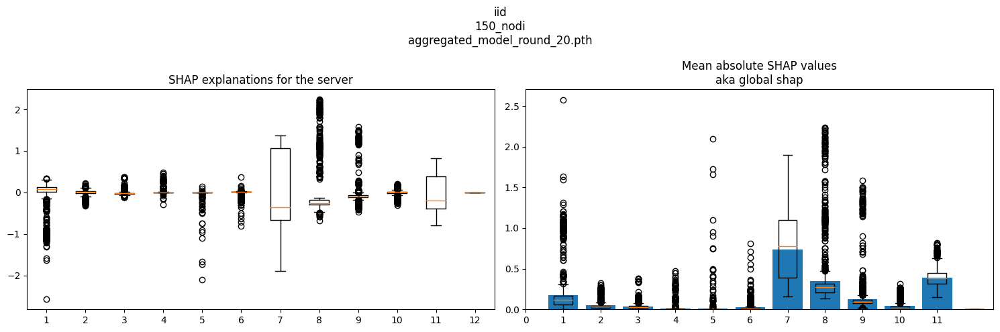

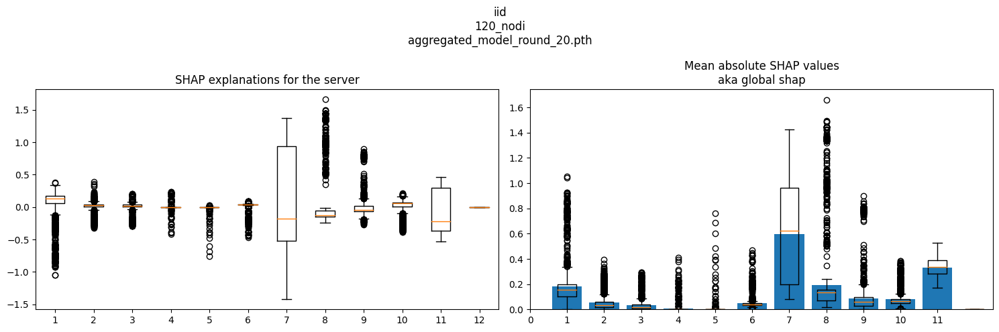

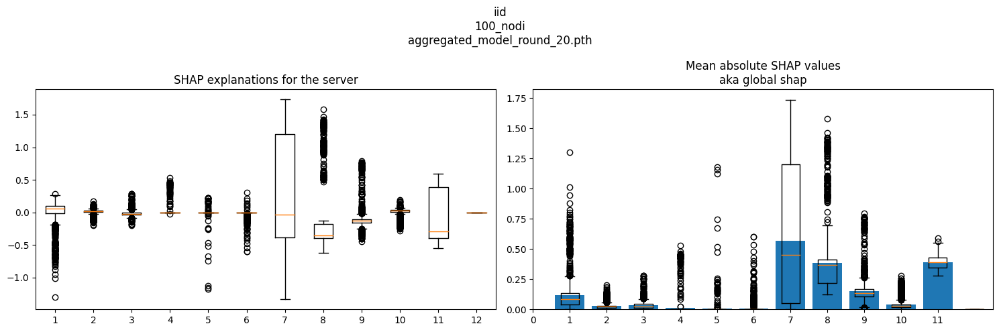

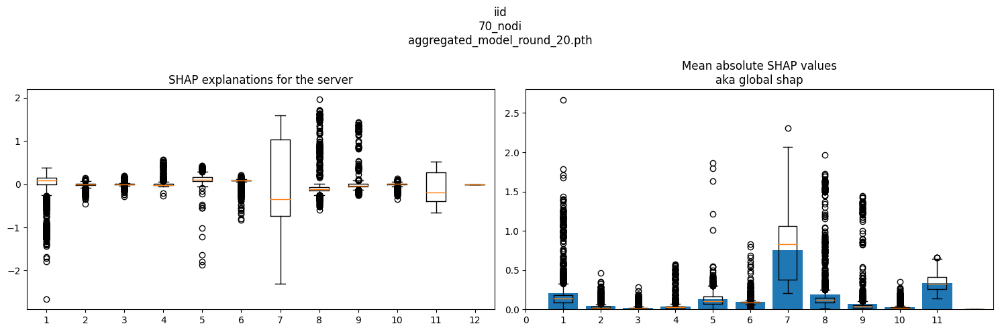

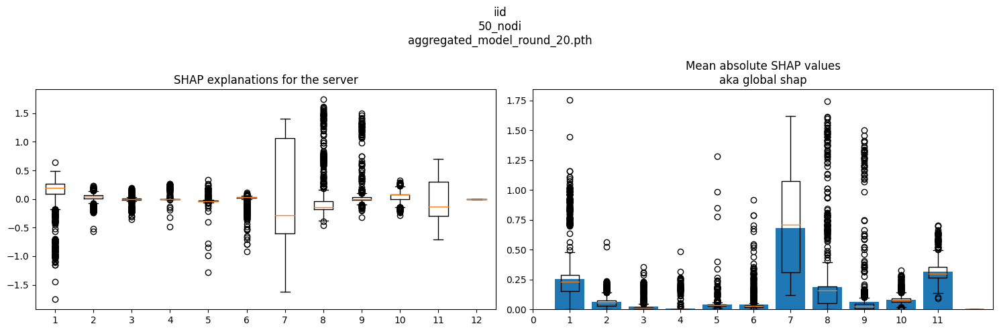

...

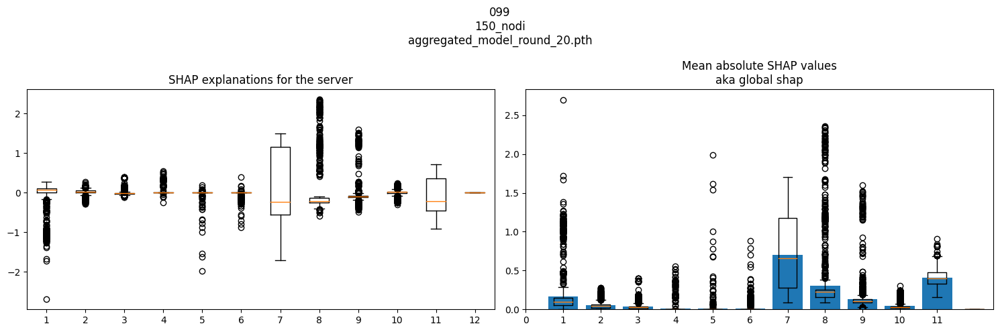

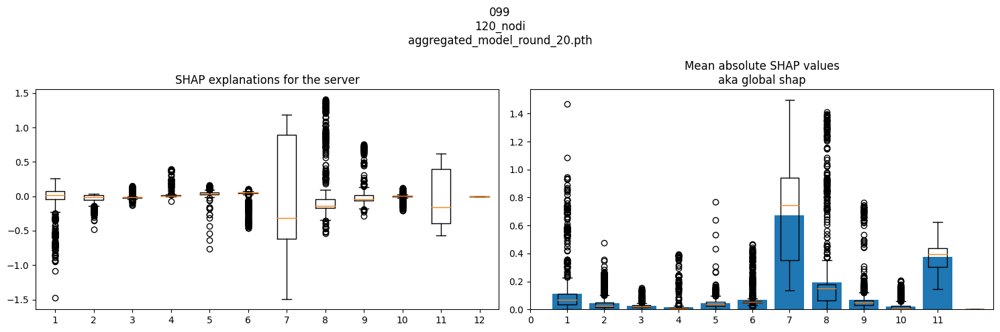

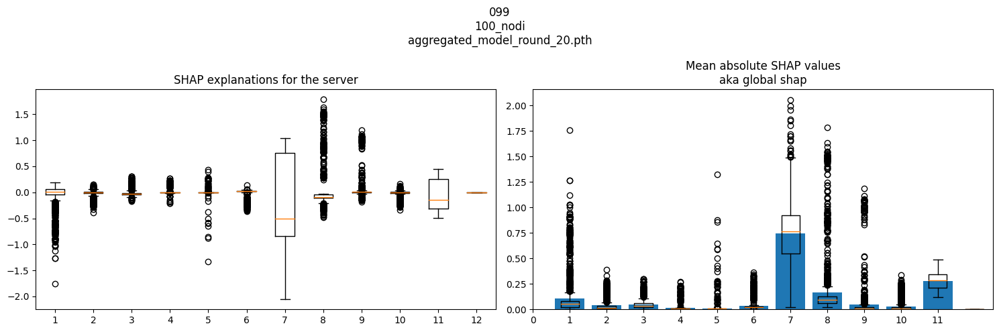

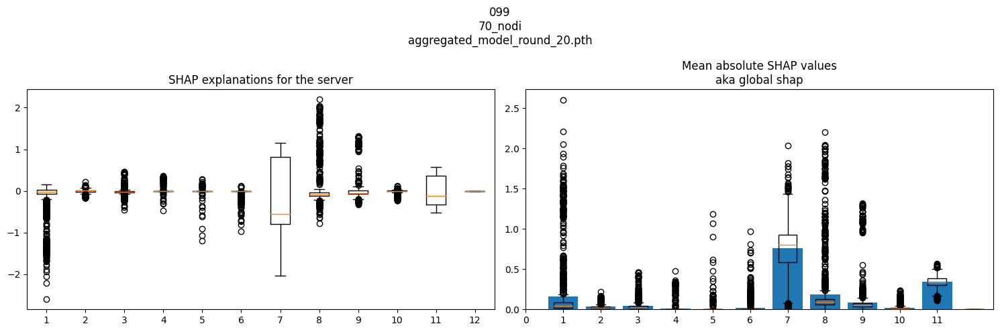

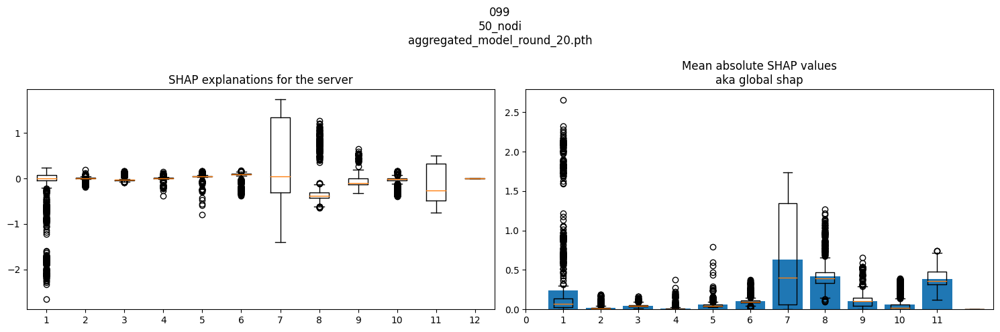

In [55]:
# for a comparison 
# insert all the global explanation in a dataframe to plot them
import pandas as pd
import seaborn as sns
all_global_exp = {}
for dist in distribs:
    for p in partitions:
        # plot it as barplots
        audit_expl = all_audit_expl[(dist,p)]
        plt.figure(figsize=(15,5))
        plt.subplot(1,2,1)
        plt.title("SHAP explanations for the server")
        plt.boxplot(audit_expl)
        plt.subplot(1,2,2)
        plt.title("Mean absolute SHAP values\naka global shap")
        plt.boxplot(np.abs(audit_expl))
        plt.bar(np.arange(audit_expl.shape[1])+1,np.mean(np.abs(audit_expl),axis=0))
        plt.xticks(np.arange(audit_expl.shape[1]),[str(i) for i in range(audit_expl.shape[1])])
        all_global_exp[(dist,p)] = np.mean(np.abs(audit_expl),axis=0)
        # the sup title should be the name of the dataset, epsilon (if in [1,2]) the name of the model, the number of nodes
        plt.suptitle(dist+"\n"+p+"\n"+model_name)
        plt.tight_layout()
        plt.show()


Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 'combination'], dtype='object')


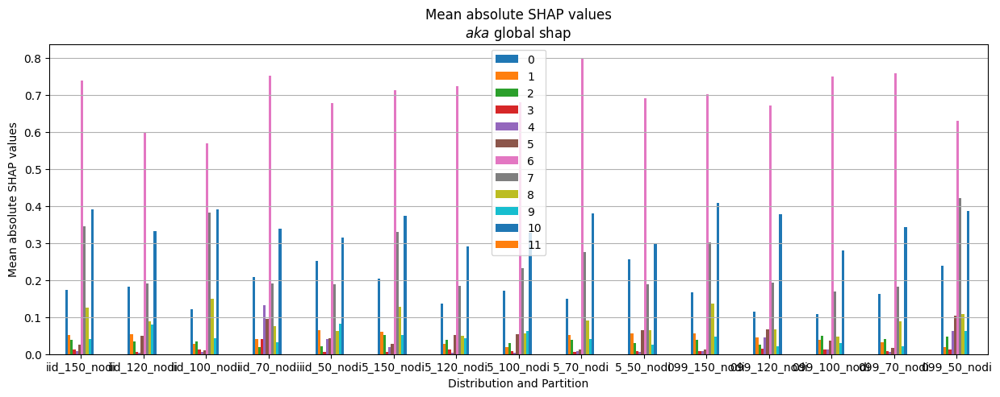

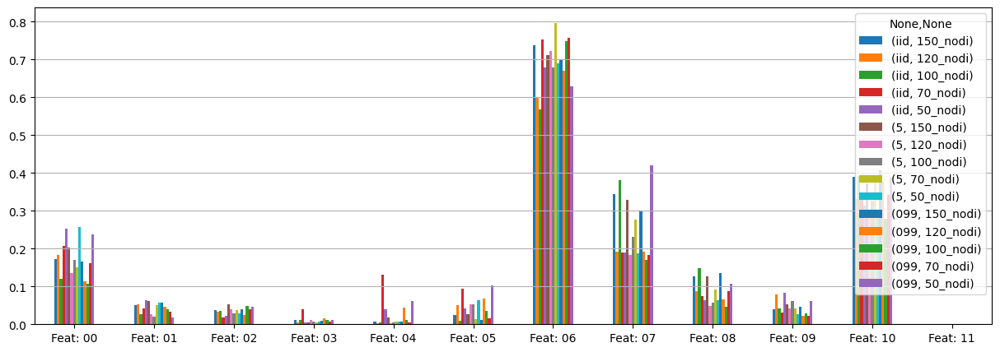

In [56]:
# convert all_global_exp to a dataframe and plot every global explanation in a single plot using seaborn and barplotcolored differently for each combination of partition and distribution
df = pd.DataFrame(all_global_exp).T
df.columns = np.arange(df.shape[1])
df = df.reset_index()
df["combination"] = df["level_0"]+"_"+df["level_1"]
df = df.drop(["level_0","level_1"],axis=1)
print(df.columns)
# plot the global explanations
plt.figure(figsize=(15,5))
plt.title("Mean absolute SHAP values\n$aka$ global shap")
#ax = df.plot(x='combination',kind='bar',rot=0,y=np.arange(df.shape[1]-1),
#        ax=plt.gca(),
#        legend=True)

ax = df.plot(x='combination',
             y=range(df.shape[1]-1),
             kind='bar',rot=0,
        ax=plt.gca(),
        legend=True)
# in the ax there are 6 barplots and 
ax.set_ylabel("Mean absolute SHAP values")
ax.set_xlabel("Distribution and Partition")
#plt.xticks(np.arange(df.shape[1]),[str(i) for i in range(df.shape[1])])
#ax.set_yscale("log")
plt.grid(axis="y")
plt.show()
df2 = pd.DataFrame(all_global_exp)
ax = df2.plot(kind="bar",figsize=(15,5))
# set the xticks
f_num = df.shape[1]-1
plt.xticks(np.arange(f_num),["Feat: "+str(i).zfill(2) for i in range(f_num)],rotation=0)
plt.grid(axis="y")
#ax.set_yscale("log")
plt.show()

In [57]:
folder

'dutch/50_nodi/099'

In [58]:
from iflash import compute_diffs,compare_heatmaps_cosinesim,compare_heatmaps_Frobenius, compare_heatmaps_spearmanr,compare_heatmaps_kendalltau

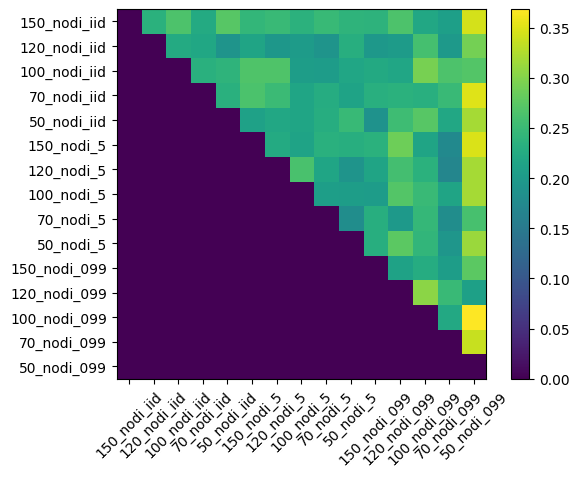

In [59]:
# retrive the representative samples from the all_server_samples dictionary
all_server_samples_list = []
all_server_samples_list_names = []
for distr in distribs:
    for p in partitions:
        to_add = np.array(all_server_samples[(distr,p)]['X'])
        #to_add = np.array(all_audit_expl[(distr,p)])
        if to_add.shape[0] == 40:
            all_server_samples_list.append(to_add)
        else:
            # pad "to add" to 40
            to_add = np.pad(to_add,((0,40-to_add.shape[0]),(0,0)))
            all_server_samples_list.append(to_add)
        all_server_samples_list_names.append(p+"_"+distr)

plt.imshow(compute_diffs(all_server_samples_list))
plt.yticks(np.arange(len(all_server_samples_list)),all_server_samples_list_names)
plt.xticks(np.arange(len(all_server_samples_list)),all_server_samples_list_names,rotation=45)
plt.colorbar()
plt.show()

In [60]:
all_audit_expl[(dist,p)].shape

(2000, 12)

In [61]:
folder
def load_shap_explanations_nb(node,distr,part):
    shap_f = all_shap_folders[(distr,part)]
    file_path = os.path.sep.join([shap_f,
                                    "shap_explanations_"+node+".npz"])
    if os.path.exists(file_path):
        return load_npz(file_path)
    else:
        print("cannot load exp from",shap_f)
        return False
load_shap_explanations_nb(random_train_node,dist,p)

In [62]:
audit_expl.shape

(2000, 12)

In [65]:

def load_representative_samples_nb(node,partition,distrib,folder="income"):
    shap_f = all_shap_folders[(distrib,partition)]
    samples_f = shap_f.replace("shap","samples")
    # can fail
    representative = load_representative(node,partition=partition,distrib=distrib)
    if isinstance(representative,bool):
        # always succed
        data_f = os.path.join(partition,distrib,"federated")
        X_feat,y_labs = load_train_set(node,folder=foldern,data_f=data_f)
        
        y_labs = np.eye(torch.max(y_labs)+1)[y_labs]
        X_feat = torch.Tensor(X_feat)
        y_labs = torch.Tensor(y_labs)
        print("representative exists?",representative)
        if X_feat.shape[0] > 12:
            
            # load the data
            dataset = TensorDataset(X_feat,y_labs)
            print("original dataset shape",dataset.tensors[0].shape,dataset.tensors[1].shape)
            if dataset.tensors[0].shape[0] == 1:
                print("TOO FEW SAMPLES, NO REPRESENTATIVE, DIRECT DATASET")
                rep_X_feat,rep_y_labs = dataset.tensors
            else:
                rep_X_feat,rep_y_labs = get_representative_samples_france(dataset=dataset,samples_per_class=10)
        else:
            print("TOO FEW SAMPLES, NO REPRESENTATIVE, DIRECT DATASET")
            rep_X_feat,rep_y_labs = X_feat,y_labs
        
        store_npz(f"./{samples_f}/representative_samples_{node}.npz",X=rep_X_feat,y=rep_y_labs)
    else:
        print("found representatives for node",node,"!",end ='\t')
        rep_X_feat, rep_y_labs = representative["X"],representative["y"]
        print(rep_X_feat.shape,"samples")
    
    return {"X":rep_X_feat,"y":rep_y_labs}
for dist in distribs:
    for p in partitions:
        train_nodes = all_train_nodes[(dist,p)]
        #train_nodes = sorted(train_node)
        for node in train_nodes:
            expl={}
            #print(node)
            
            data_dict = load_representative_samples_nb(node,partition=p,distrib=dist)
            # print(node,data_dict["X"].shape,data_dict["y"].shape)
            # instanciate the dataloader
            
            data = TensorDataset(torch.Tensor(data_dict["X"]),
                                    torch.Tensor(data_dict["y"]))
            loader_bk_dt = DataLoader(data, batch_size=256,shuffle=False)
            
            # get the shap explanations using the load_shap_explanations_nb
            # if the result is an instance of bool, then it has to be computed
            # otherwise we are good
            node_exp =  load_shap_explanations_nb(node, distr=dist,part = p)
            if isinstance(node_exp,bool) or node_exp["shap"].shape != (audit_expl.shape):
                print("to recompute")
                if node_exp:
                    print(node_exp["shap"].shape)
                node_exp = get_shap_explanations(model,
                            background_data_loader = loader_bk_dt,
                            explain_partition=loader_exp_dt)
                expl["shap"] = node_exp
            else:
                print("shap values for node ",node,"already computed!")
                expl["shap"] = node_exp["shap"]
            assert expl["shap"].shape[0] == audit_expl.shape[0], "Number of samples do not match!"
            assert expl["shap"].shape[1] == audit_expl.shape[1], "Number of features do not match!"
        # save the explanation
            if expl["shap"].shape == audit_expl.shape:
                shap_f = all_shap_folders[(dist,p)]
                file_path = os.path.sep.join([shap_f,
                                    "shap_explanations_"+node+".npz"])
                store_npz(file_path,**expl)
                print("saved in",file_path)
            else:
                print("error")
                


loading representatives of 1 from folder dutch_150_nodi_iid_samples
found representatives for node 1 !	(36, 12) samples
shap values for node  1 already computed!
saved in dutch_150_nodi_iid_shap/shap_explanations_1.npz
loading representatives of 2 from folder dutch_150_nodi_iid_samples
found representatives for node 2 !	(36, 12) samples
shap values for node  2 already computed!
saved in dutch_150_nodi_iid_shap/shap_explanations_2.npz
loading representatives of 3 from folder dutch_150_nodi_iid_samples
found representatives for node 3 !	(40, 12) samples
shap values for node  3 already computed!
saved in dutch_150_nodi_iid_shap/shap_explanations_3.npz
loading representatives of 4 from folder dutch_150_nodi_iid_samples
found representatives for node 4 !	(40, 12) samples
shap values for node  4 already computed!
saved in dutch_150_nodi_iid_shap/shap_explanations_4.npz
loading representatives of 5 from folder dutch_150_nodi_iid_samples
found representatives for node 5 !	(40, 12) samples
shap

100%|██████████| 2000/2000 [01:45<00:00, 19.04it/s]


saved in dutch_100_nodi_099_shap/shap_explanations_91.npz
loading representatives of 92 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_92.npz
representative exists? False
original dataset shape torch.Size([295, 12]) torch.Size([295, 2])
torch.Size([295, 2]) shape of the labels
best k: 10
(40, 12) (40, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (40, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_92.npz
loading representatives of 93 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_93.npz
representative exists? False
original dataset shape torch.Size([148, 12]) torch.Size([148, 2])
torch.Size([148, 2]) shape of the labels
best k: 9
(36, 12) (36, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (36, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_93.npz
loading representatives of 94 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_94.npz
representative exists? False
original dataset shape torch.Size([202, 12]) torch.Size([202, 2])
torch.Size([202, 2]) shape of the labels
best k: 8
(32, 12) (32, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (32, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_94.npz
loading representatives of 95 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_95.npz
representative exists? False
original dataset shape torch.Size([411, 12]) torch.Size([411, 2])
torch.Size([411, 2]) shape of the labels
best k: 7
(28, 12) (28, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (28, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_95.npz
loading representatives of 96 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_96.npz
representative exists? False
original dataset shape torch.Size([739, 12]) torch.Size([739, 2])
torch.Size([739, 2]) shape of the labels
best k: 8
(32, 12) (32, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (32, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_96.npz
loading representatives of 97 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_97.npz
representative exists? False
original dataset shape torch.Size([91, 12]) torch.Size([91, 2])
torch.Size([91, 2]) shape of the labels
best k: 10
(36, 12) (36, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (36, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_97.npz
loading representatives of 98 from folder dutch_100_nodi_099_samples
file not found! dutch_100_nodi_099_samples/representative_samples_98.npz
representative exists? False
original dataset shape torch.Size([196, 12]) torch.Size([196, 2])
torch.Size([196, 2]) shape of the labels
best k: 9
(36, 12) (36, 2)
cannot load exp from dutch_100_nodi_099_shap
to recompute
shapes of background and samples to explain (36, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_100_nodi_099_shap/shap_explanations_98.npz
loading representatives of 0 from folder dutch_70_nodi_099_samples
found representatives for node 0 !	(24, 12) samples
shap values for node  0 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_0.npz
loading representatives of 1 from folder dutch_70_nodi_099_samples
found representatives for node 1 !	(40, 12) samples
shap values for node  1 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_1.npz
loading representatives of 2 from folder dutch_70_nodi_099_samples
file not found! dutch_70_nodi_099_samples/representative_samples_2.npz
representative exists? False
original dataset shape torch.Size([95, 12]) torch.Size([95, 2])
torch.Size([95, 2]) shape of the labels
best k: 7
(28, 12) (28, 2)
cannot load exp from dutch_70_nodi_099_shap
to recompute
shapes of background and samples to explain (28, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_2.npz
loading representatives of 3 from folder dutch_70_nodi_099_samples
found representatives for node 3 !	(36, 12) samples
shap values for node  3 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_3.npz
loading representatives of 4 from folder dutch_70_nodi_099_samples
file not found! dutch_70_nodi_099_samples/representative_samples_4.npz
representative exists? False
original dataset shape torch.Size([2304, 12]) torch.Size([2304, 2])
torch.Size([2304, 2]) shape of the labels
best k: 10
(40, 12) (40, 2)
cannot load exp from dutch_70_nodi_099_shap
to recompute
shapes of background and samples to explain (40, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_4.npz
loading representatives of 5 from folder dutch_70_nodi_099_samples
found representatives for node 5 !	(36, 12) samples
shap values for node  5 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_5.npz
loading representatives of 7 from folder dutch_70_nodi_099_samples
found representatives for node 7 !	(36, 12) samples
shap values for node  7 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_7.npz
loading representatives of 8 from folder dutch_70_nodi_099_samples
found representatives for node 8 !	(32, 12) samples
shap values for node  8 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_8.npz
loading representatives of 9 from folder dutch_70_nodi_099_samples
found representatives for node 9 !	(28, 12) samples
shap values for node  9 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_9.npz
loading representatives of 10 from folder dutch_70_nodi_099_samples
found re

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_16.npz
loading representatives of 17 from folder dutch_70_nodi_099_samples
found representatives for node 17 !	(40, 12) samples
shap values for node  17 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_17.npz
loading representatives of 18 from folder dutch_70_nodi_099_samples
found representatives for node 18 !	(20, 12) samples
shap values for node  18 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_18.npz
loading representatives of 20 from folder dutch_70_nodi_099_samples
found representatives for node 20 !	(40, 12) samples
shap values for node  20 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_20.npz
loading representatives of 21 from folder dutch_70_nodi_099_samples
file not found! dutch_70_nodi_099_samples/representative_samples_21.npz
representative exists? False
original dataset shape torch.Size([372, 12]) torch.Size([372, 2])
torch.Size([372, 2]) shape of the labels
best

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_21.npz
loading representatives of 22 from folder dutch_70_nodi_099_samples
file not found! dutch_70_nodi_099_samples/representative_samples_22.npz
representative exists? False
original dataset shape torch.Size([272, 12]) torch.Size([272, 2])
torch.Size([272, 2]) shape of the labels
best k: 6
(24, 12) (24, 2)
cannot load exp from dutch_70_nodi_099_shap
to recompute
shapes of background and samples to explain (24, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_22.npz
loading representatives of 23 from folder dutch_70_nodi_099_samples
file not found! dutch_70_nodi_099_samples/representative_samples_23.npz
representative exists? False
original dataset shape torch.Size([1625, 12]) torch.Size([1625, 2])
torch.Size([1625, 2]) shape of the labels
best k: 10
(40, 12) (40, 2)
cannot load exp from dutch_70_nodi_099_shap
to recompute
shapes of background and samples to explain (40, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_23.npz
loading representatives of 24 from folder dutch_70_nodi_099_samples
found representatives for node 24 !	(40, 12) samples
shap values for node  24 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_24.npz
loading representatives of 27 from folder dutch_70_nodi_099_samples
found representatives for node 27 !	(16, 12) samples
shap values for node  27 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_27.npz
loading representatives of 28 from folder dutch_70_nodi_099_samples
found representatives for node 28 !	(24, 12) samples
shap values for node  28 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_28.npz
loading representatives of 29 from folder dutch_70_nodi_099_samples
found representatives for node 29 !	(36, 12) samples
shap values for node  29 already computed!
saved in dutch_70_nodi_099_shap/shap_explanations_29.npz
loading representatives of 30 from folder dutch_70_nodi_099

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_70_nodi_099_shap/shap_explanations_69.npz
loading representatives of 0 from folder dutch_50_nodi_099_samples
found representatives for node 0 !	(36, 12) samples
shap values for node  0 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_0.npz
loading representatives of 1 from folder dutch_50_nodi_099_samples
found representatives for node 1 !	(32, 12) samples
shap values for node  1 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_1.npz
loading representatives of 2 from folder dutch_50_nodi_099_samples
found representatives for node 2 !	(40, 12) samples
shap values for node  2 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_2.npz
loading representatives of 3 from folder dutch_50_nodi_099_samples
found representatives for node 3 !	(40, 12) samples
shap values for node  3 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_3.npz
loading representatives of 4 from folder dutch_50_nodi_099_samples
found re

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_50_nodi_099_shap/shap_explanations_6.npz
loading representatives of 8 from folder dutch_50_nodi_099_samples
found representatives for node 8 !	(36, 12) samples
shap values for node  8 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_8.npz
loading representatives of 9 from folder dutch_50_nodi_099_samples
found representatives for node 9 !	(32, 12) samples
shap values for node  9 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_9.npz
loading representatives of 10 from folder dutch_50_nodi_099_samples
found representatives for node 10 !	(28, 12) samples
shap values for node  10 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_10.npz
loading representatives of 11 from folder dutch_50_nodi_099_samples
file not found! dutch_50_nodi_099_samples/representative_samples_11.npz
representative exists? False
original dataset shape torch.Size([738, 12]) torch.Size([738, 2])
torch.Size([738, 2]) shape of the labels
best k: 7
(28

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_50_nodi_099_shap/shap_explanations_11.npz
loading representatives of 13 from folder dutch_50_nodi_099_samples
found representatives for node 13 !	(20, 12) samples
shap values for node  13 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_13.npz
loading representatives of 14 from folder dutch_50_nodi_099_samples
found representatives for node 14 !	(16, 12) samples
shap values for node  14 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_14.npz
loading representatives of 15 from folder dutch_50_nodi_099_samples
found representatives for node 15 !	(27, 12) samples
shap values for node  15 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_15.npz
loading representatives of 17 from folder dutch_50_nodi_099_samples
found representatives for node 17 !	(36, 12) samples
shap values for node  17 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_17.npz
loading representatives of 18 from folder dutch_50_nodi_099

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_50_nodi_099_shap/shap_explanations_22.npz
loading representatives of 24 from folder dutch_50_nodi_099_samples
found representatives for node 24 !	(40, 12) samples
shap values for node  24 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_24.npz
loading representatives of 25 from folder dutch_50_nodi_099_samples
file not found! dutch_50_nodi_099_samples/representative_samples_25.npz
representative exists? False
original dataset shape torch.Size([970, 12]) torch.Size([970, 2])
torch.Size([970, 2]) shape of the labels
best k: 10
(40, 12) (40, 2)
cannot load exp from dutch_50_nodi_099_shap
to recompute
shapes of background and samples to explain (40, 12) (2000, 12)


  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_50_nodi_099_shap/shap_explanations_25.npz
loading representatives of 26 from folder dutch_50_nodi_099_samples
found representatives for node 26 !	(32, 12) samples
shap values for node  26 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_26.npz
loading representatives of 28 from folder dutch_50_nodi_099_samples
found representatives for node 28 !	(32, 12) samples
shap values for node  28 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_28.npz
loading representatives of 32 from folder dutch_50_nodi_099_samples
found representatives for node 32 !	(26, 12) samples
shap values for node  32 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_32.npz
loading representatives of 33 from folder dutch_50_nodi_099_samples
found representatives for node 33 !	(36, 12) samples
shap values for node  33 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_33.npz
loading representatives of 34 from folder dutch_50_nodi_099

  0%|          | 0/2000 [00:00<?, ?it/s]`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
`np.int` is a deprecated alias for the builtin `int`. To silence this warning, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
100%|██████████|

saved in dutch_50_nodi_099_shap/shap_explanations_34.npz
loading representatives of 35 from folder dutch_50_nodi_099_samples
found representatives for node 35 !	(32, 12) samples
shap values for node  35 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_35.npz
loading representatives of 36 from folder dutch_50_nodi_099_samples
found representatives for node 36 !	(40, 12) samples
shap values for node  36 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_36.npz
loading representatives of 37 from folder dutch_50_nodi_099_samples
found representatives for node 37 !	(36, 12) samples
shap values for node  37 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_37.npz
loading representatives of 39 from folder dutch_50_nodi_099_samples
found representatives for node 39 !	(32, 12) samples
shap values for node  39 already computed!
saved in dutch_50_nodi_099_shap/shap_explanations_39.npz
loading representatives of 43 from folder dutch_50_nodi_099

In [66]:
data_f = os.path.join("150_nodi","099","federated")
data_f
X_feat,y_labs = load_train_set(node,folder=foldern,data_f=data_f)
node,foldern,data_f

('49', 'dutch', '150_nodi/099/federated')

In [67]:
X_feat,y_labs,
node

'49'

In [68]:
all_all_expl = {}   
for dist in distribs:
    for p in partitions:
        train_nodes = all_train_nodes[(dist,p)]
        all_expl = []
        for node in train_nodes:
            out = load_shap_explanations_nb(node,distr=dist,part=p)
            if isinstance(out,bool):
                print("no explanation for node",node)
            else:
                all_expl.append(out["shap"])
        all_expl = np.array(all_expl)
        print(all_expl.shape)
        all_all_expl[(dist,p)] = all_expl

(100, 2000, 12)
(84, 2000, 12)
(70, 2000, 12)
(49, 2000, 12)
(35, 2000, 12)
(100, 2000, 12)
(84, 2000, 12)
(70, 2000, 12)
(49, 2000, 12)
(35, 2000, 12)
(100, 2000, 12)
(84, 2000, 12)
(70, 2000, 12)
(49, 2000, 12)
(35, 2000, 12)


In [69]:
for dist in distribs:
    for p in partitions:
        audit_expl = all_audit_expl[(dist,p)]
        all_expl = all_all_expl[(dist,p)]
        print(p,dist,np.abs((audit_expl-np.mean(all_expl,0))).mean())

150_nodi iid 0.01708551872424314
120_nodi iid 0.053673499700263375
100_nodi iid 0.07997117931077068
70_nodi iid 0.048800494526002665
50_nodi iid 0.04955864355860491
150_nodi 5 0.017430359017371562
120_nodi 5 0.05587048166542975
100_nodi 5 0.045003152482045256
70_nodi 5 0.0348271158341982
50_nodi 5 0.04940747709663069
150_nodi 099 0.029982700876563233
120_nodi 099 0.055270210480555325
100_nodi 099 0.0739079540239836
70_nodi 099 0.06463727128926865
50_nodi 099 0.08960288557005944


In [70]:
all_expl[0]

array([[-0.05360033, -0.13710822, -0.03433865, ..., -0.04379895,
        -0.36171064,  0.        ],
       [-0.49309974, -0.25822836,  0.11805486, ..., -0.167714  ,
         0.31087389,  0.        ],
       [ 0.09458907, -0.04208818, -0.05050235, ...,  0.05470027,
         0.35117702,  0.        ],
       ...,
       [ 0.14599845, -0.03047965, -0.02939965, ...,  0.02788349,
        -0.52583528,  0.        ],
       [ 0.15650162, -0.03043353,  0.2890323 , ...,  0.03476155,
         0.53897309,  0.        ],
       [ 0.16871211, -0.03231632, -0.03108241, ...,  0.02743168,
        -0.49254947,  0.        ]])

In [71]:
'''for j,e in enumerate(np.round(audit_expl[:3,:],5)):
    print("explanation:","\t".join([str(np.round(el,4)) for el in e]))
    print("client 1:   ","\t".join([str(np.round(el,4)) for el in all_expl[1,j,:]]))'''

'for j,e in enumerate(np.round(audit_expl[:3,:],5)):\n    print("explanation:","\t".join([str(np.round(el,4)) for el in e]))\n    print("client 1:   ","\t".join([str(np.round(el,4)) for el in all_expl[1,j,:]]))'

In [72]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [73]:
dt_name = "dutch"

In [74]:
partitions

['150_nodi', '120_nodi', '100_nodi', '70_nodi', '50_nodi']

computed and plotted $ShapGap_{L2}$ distance for 150_nodi iid ... 0 0
computed and plotted $ShapGap_{Kendall}$ similarity for 150_nodi iid ... 0 1
computed and plotted $ShapGap_{Cos}$ similarity for 150_nodi iid ... 0 2
computed and plotted $ShapGap_{Spearmann}$ similarity for 150_nodi iid ... 0 3
computed and plotted $ShapGap_{L2}$ distance for 150_nodi 5 ... 1 4
computed and plotted $ShapGap_{Kendall}$ similarity for 150_nodi 5 ... 1 5
computed and plotted $ShapGap_{Cos}$ similarity for 150_nodi 5 ... 1 6
computed and plotted $ShapGap_{Spearmann}$ similarity for 150_nodi 5 ... 1 7
computed and plotted $ShapGap_{L2}$ distance for 150_nodi 099 ... 2 8
computed and plotted $ShapGap_{Kendall}$ similarity for 150_nodi 099 ... 2 9
computed and plotted $ShapGap_{Cos}$ similarity for 150_nodi 099 ... 2 10
computed and plotted $ShapGap_{Spearmann}$ similarity for 150_nodi 099 ... 2 11


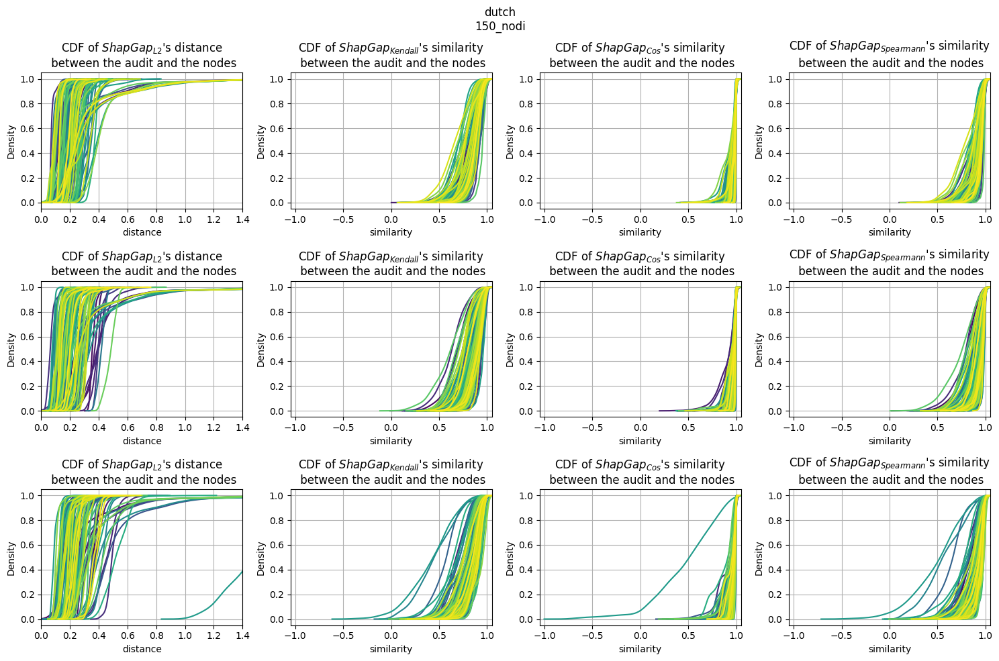

computed and plotted $ShapGap_{L2}$ distance for 120_nodi iid ... 0 0
computed and plotted $ShapGap_{Kendall}$ similarity for 120_nodi iid ... 0 1
computed and plotted $ShapGap_{Cos}$ similarity for 120_nodi iid ... 0 2
computed and plotted $ShapGap_{Spearmann}$ similarity for 120_nodi iid ... 0 3
computed and plotted $ShapGap_{L2}$ distance for 120_nodi 5 ... 1 4
computed and plotted $ShapGap_{Kendall}$ similarity for 120_nodi 5 ... 1 5
computed and plotted $ShapGap_{Cos}$ similarity for 120_nodi 5 ... 1 6
computed and plotted $ShapGap_{Spearmann}$ similarity for 120_nodi 5 ... 1 7
computed and plotted $ShapGap_{L2}$ distance for 120_nodi 099 ... 2 8
computed and plotted $ShapGap_{Kendall}$ similarity for 120_nodi 099 ... 2 9
computed and plotted $ShapGap_{Cos}$ similarity for 120_nodi 099 ... 2 10
computed and plotted $ShapGap_{Spearmann}$ similarity for 120_nodi 099 ... 2 11


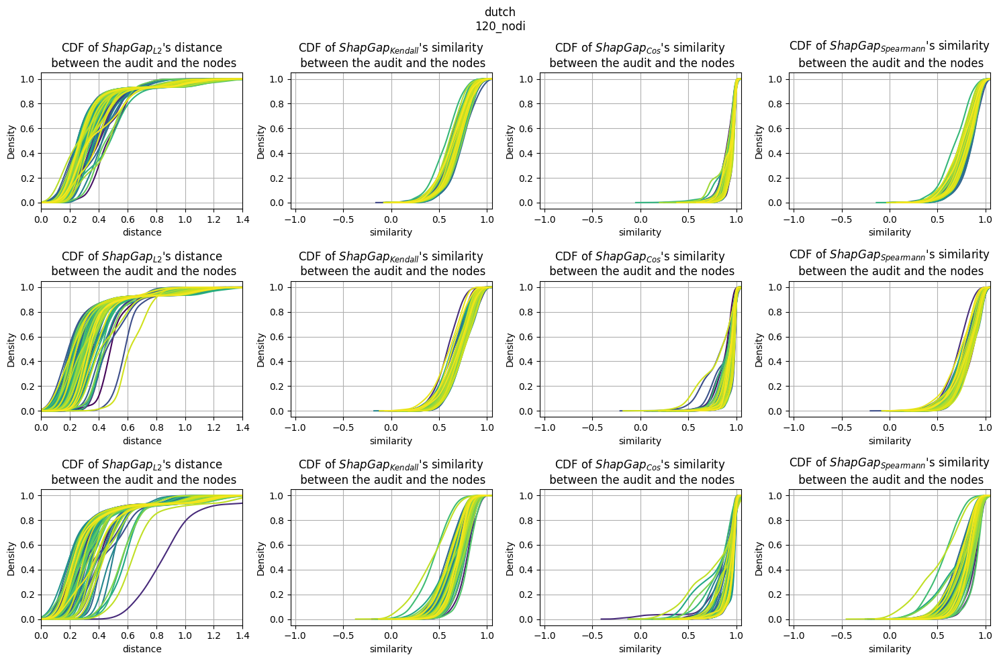

computed and plotted $ShapGap_{L2}$ distance for 100_nodi iid ... 0 0
computed and plotted $ShapGap_{Kendall}$ similarity for 100_nodi iid ... 0 1
computed and plotted $ShapGap_{Cos}$ similarity for 100_nodi iid ... 0 2
computed and plotted $ShapGap_{Spearmann}$ similarity for 100_nodi iid ... 0 3
computed and plotted $ShapGap_{L2}$ distance for 100_nodi 5 ... 1 4
computed and plotted $ShapGap_{Kendall}$ similarity for 100_nodi 5 ... 1 5
computed and plotted $ShapGap_{Cos}$ similarity for 100_nodi 5 ... 1 6
computed and plotted $ShapGap_{Spearmann}$ similarity for 100_nodi 5 ... 1 7
computed and plotted $ShapGap_{L2}$ distance for 100_nodi 099 ... 2 8
computed and plotted $ShapGap_{Kendall}$ similarity for 100_nodi 099 ... 2 9
computed and plotted $ShapGap_{Cos}$ similarity for 100_nodi 099 ... 2 10
computed and plotted $ShapGap_{Spearmann}$ similarity for 100_nodi 099 ... 2 11


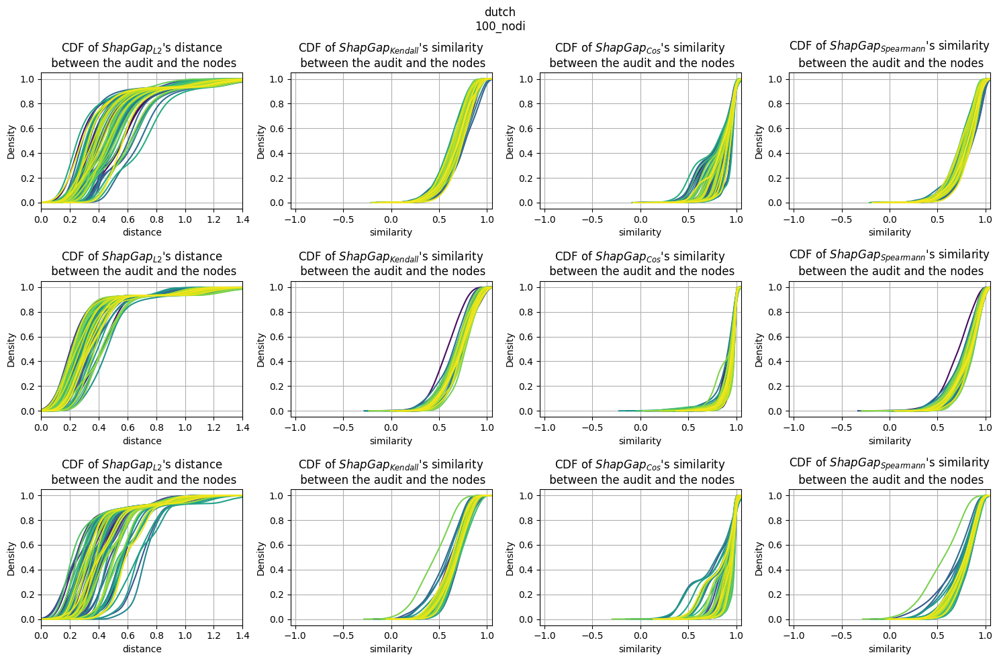

computed and plotted $ShapGap_{L2}$ distance for 70_nodi iid ... 0 0
computed and plotted $ShapGap_{Kendall}$ similarity for 70_nodi iid ... 0 1
computed and plotted $ShapGap_{Cos}$ similarity for 70_nodi iid ... 0 2
computed and plotted $ShapGap_{Spearmann}$ similarity for 70_nodi iid ... 0 3
computed and plotted $ShapGap_{L2}$ distance for 70_nodi 5 ... 1 4
computed and plotted $ShapGap_{Kendall}$ similarity for 70_nodi 5 ... 1 5
computed and plotted $ShapGap_{Cos}$ similarity for 70_nodi 5 ... 1 6
computed and plotted $ShapGap_{Spearmann}$ similarity for 70_nodi 5 ... 1 7
computed and plotted $ShapGap_{L2}$ distance for 70_nodi 099 ... 2 8
computed and plotted $ShapGap_{Kendall}$ similarity for 70_nodi 099 ... 2 9
computed and plotted $ShapGap_{Cos}$ similarity for 70_nodi 099 ... 2 10
computed and plotted $ShapGap_{Spearmann}$ similarity for 70_nodi 099 ... 2 11


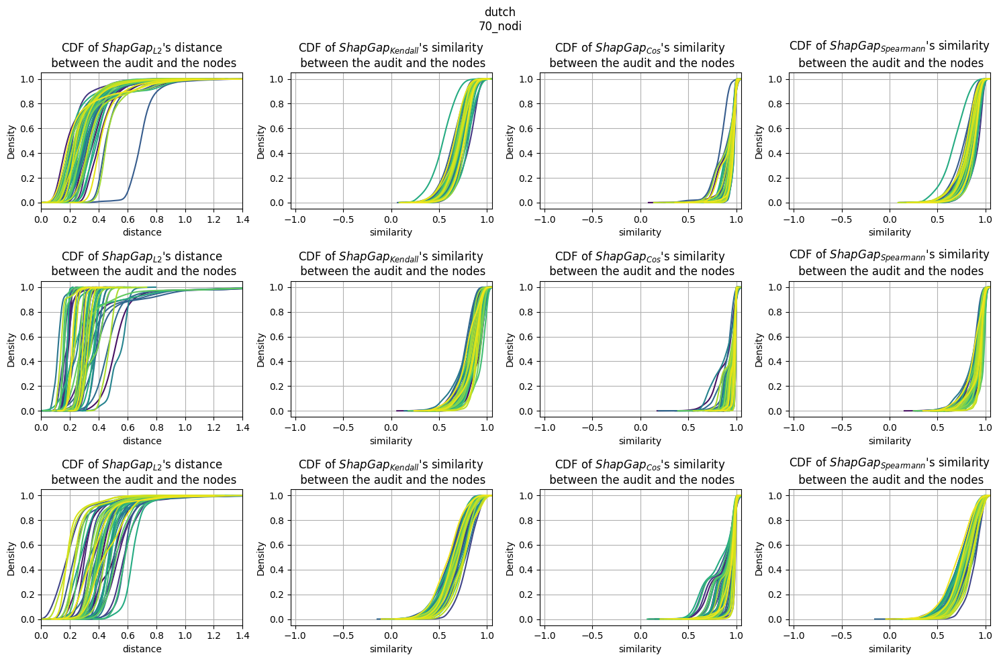

computed and plotted $ShapGap_{L2}$ distance for 50_nodi iid ... 0 0
computed and plotted $ShapGap_{Kendall}$ similarity for 50_nodi iid ... 0 1
computed and plotted $ShapGap_{Cos}$ similarity for 50_nodi iid ... 0 2
computed and plotted $ShapGap_{Spearmann}$ similarity for 50_nodi iid ... 0 3
computed and plotted $ShapGap_{L2}$ distance for 50_nodi 5 ... 1 4
computed and plotted $ShapGap_{Kendall}$ similarity for 50_nodi 5 ... 1 5
computed and plotted $ShapGap_{Cos}$ similarity for 50_nodi 5 ... 1 6
computed and plotted $ShapGap_{Spearmann}$ similarity for 50_nodi 5 ... 1 7
computed and plotted $ShapGap_{L2}$ distance for 50_nodi 099 ... 2 8
computed and plotted $ShapGap_{Kendall}$ similarity for 50_nodi 099 ... 2 9
computed and plotted $ShapGap_{Cos}$ similarity for 50_nodi 099 ... 2 10
computed and plotted $ShapGap_{Spearmann}$ similarity for 50_nodi 099 ... 2 11


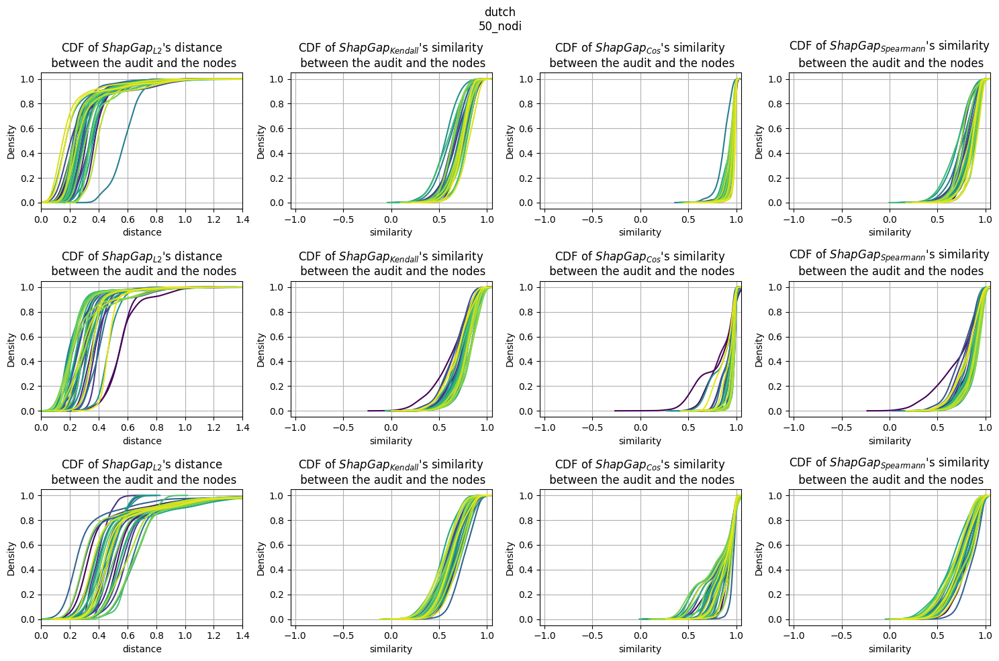

In [75]:
import seaborn as sns
for p in partitions:
    fig,ax = plt.subplots(len(distribs),4,figsize=(15,10))
    ax = ax.flatten()
    for ii,dist in enumerate(distribs):
        
        all_expl = all_all_expl[(dist,p)]
        audit_expl = all_audit_expl[(dist,p)]
        # compute the difference between the shap values of the server and the average of the nodes
        # then plot the kde plot of the differences
        for j,metr in enumerate(["$ShapGap_{L2}$","$ShapGap_{Kendall}$","$ShapGap_{Cos}$","$ShapGap_{Spearmann}$"]):
            
            comparing_f = [compare_heatmaps_Frobenius,compare_heatmaps_kendalltau,compare_heatmaps_cosinesim,compare_heatmaps_spearmanr][j]
            metric_d = ["distance","similarity","similarity","similarity"][j]
            j+=int(ii*(len(distribs)+1))
            for jj,explanation_c in enumerate(all_expl):
                # select color from the hsv color map
                color = plt.cm.viridis(jj/len(all_expl))
                
                res = comparing_f(explanation_c,audit_expl)
                #res=res.sum(1).reshape(-1,1)
                #print(res.max(),res.mean(),res.std(),res.shape)
                #print(res.shape)
                sns.kdeplot(res,cumulative=True,color=color,ax=ax[j])
            ax[j].set_title("CDF of "+metr+"'s "+metric_d+"\n between the audit and the nodes")
            ax[j].set_xlabel(metric_d)
            if metric_d != "distance":
                ax[j].set_xlim(-1.05,1.05)
            else:
                ax[j].set_xlim(0,1.4)
            ax[j].set_ylim(-0.05,1.05)
            ax[j].grid(True)
            print("computed and plotted",metr,metric_d,"for",p,dist,"...",ii,j)
            
    plt.suptitle(dt_name+"\n"+p)
    plt.tight_layout()
    # save the image
    plt.savefig(p+"_Dutch_cumulative_metrics.pdf")
    plt.show()
    plt.clf()
    plt.close()

# FLEXAI 
## Explanation as a service

In [76]:
feat_names = ["feat_"+str(i+1).zfill(2) for i in range(audit_expl.shape[1])]
feat_names = [
        "age","household_position","household_size","prev_residence_place","citizenship","country_birth","edu_level","economic_status","cur_eco_activity","Marital_status","sex_binary",'bias'
        ]
        
print(feat_names)

['age', 'household_position', 'household_size', 'prev_residence_place', 'citizenship', 'country_birth', 'edu_level', 'economic_status', 'cur_eco_activity', 'Marital_status', 'sex_binary', 'bias']


In [77]:
focus = [folder]


In [78]:
all_expl = all_all_expl[(dist,p)]
all_expl.shape,all_all_expl.keys()

((35, 2000, 12),
 dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]))

In [79]:
folder

'dutch/50_nodi/099'

In [80]:
exps = []
all_shap_dict = {}
all_weights_dict = {}
all_weights_dict_MACRO = {}
all_num_samples = {}
for dist in distribs:
    for p in partitions:
        if dist == "non_iid_099" and p == "150 nodi":
            continue
        audit_expl = all_audit_expl[(dist,p)]
        all_expl = all_all_expl[(dist,p)]
        exps.append((dist,p))
        all_shap_dict[exps[-1]]= {"Server":audit_expl,
                                "Clients":all_expl,
                                "E_hat":all_expl.mean(axis=0)}

for exp in exps:
            # checkfor nans
            #print(all_shap_dict[exp]["Clients"]!=all_shap_dict[exp]["Clients"]).any()
            train_nodes = all_train_nodes[exp]
            print(exp,len(train_nodes),len(all_shap_dict[exp]["Clients"]))
            model = torch.load(all_models_paths[exp])
            dist,p =exp
            all_weights_dict[exp] =         [get_f1(dt_name+"/"+p+"/"+dist,node,model=model) for node in train_nodes]
            all_weights_dict_MACRO[exp] =   [get_f1(dt_name+"/"+p+"/"+dist,node,model=model,macro=True) for node in train_nodes]            

            all_shap_dict[exp]["E_weighted"] = np.average(all_shap_dict[exp]["Clients"],axis=0,
                                                          
                                                          weights=all_weights_dict[exp]
                                                          )
            all_shap_dict[exp]["E_f1_macro"] = np.average(all_shap_dict[exp]["Clients"],axis=0,
                                                          weights=all_weights_dict_MACRO[exp]
                                                          )
            all_shap_dict[exp]["Delta"] = all_shap_dict[exp]["Server"]-all_shap_dict[exp]["E_hat"]

            all_num_samples[exp] = [get_num_samples(dt_name+"/"+p+"/"+dist,node) for node in train_nodes]



('iid', '150_nodi') 100 100
0.8419226097518654
0.8722093810319382
0.7893307930459634
0.8197325893920321
0.8947368421052632
0.7813545220821801
0.7971994791828605
0.7825299512517557
0.872108175442848
0.8722977638555173
0.8801125580786597
0.8195488721804511
0.8199575024517816
0.842373593872519
0.8499315075512498
0.8797264531749999
0.8497771578266934
0.7894736842105263
0.8416705159905443
0.8271859471991464
0.8188436608763289
0.7517955193326828
0.7665197446968949
0.8120939634533567
0.8570297669534311
0.8272887974076427
0.7971078985199653
0.8342632443176907
0.8796992481203008
0.8424636058230682
0.8646616541353384
0.804289936798518
0.8721804511278195
0.8270676691729323
0.7966462292521342
0.8124157644038852
0.8489645165545442
0.8421769316909294
0.7895212930562499
0.8195488721804511
0.798242114262573
0.8120300751879699
0.8349892588614395
0.819774846953449
0.8272887974076427
0.7749731471535983
0.8503990163222992
0.9021450247584671
0.7896880209573707
0.8120513327423733
0.797337477836096
0.8342482

In [81]:
all_shap_dict.keys(),all_weights_dict.keys()

(dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]),
 dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]))

In [82]:
focus = []
for p in partitions:
    for dist in distribs:
        exp = (dist,p)
        focus.append(exp)
focus

[('iid', '150_nodi'),
 ('5', '150_nodi'),
 ('099', '150_nodi'),
 ('iid', '120_nodi'),
 ('5', '120_nodi'),
 ('099', '120_nodi'),
 ('iid', '100_nodi'),
 ('5', '100_nodi'),
 ('099', '100_nodi'),
 ('iid', '70_nodi'),
 ('5', '70_nodi'),
 ('099', '70_nodi'),
 ('iid', '50_nodi'),
 ('5', '50_nodi'),
 ('099', '50_nodi')]

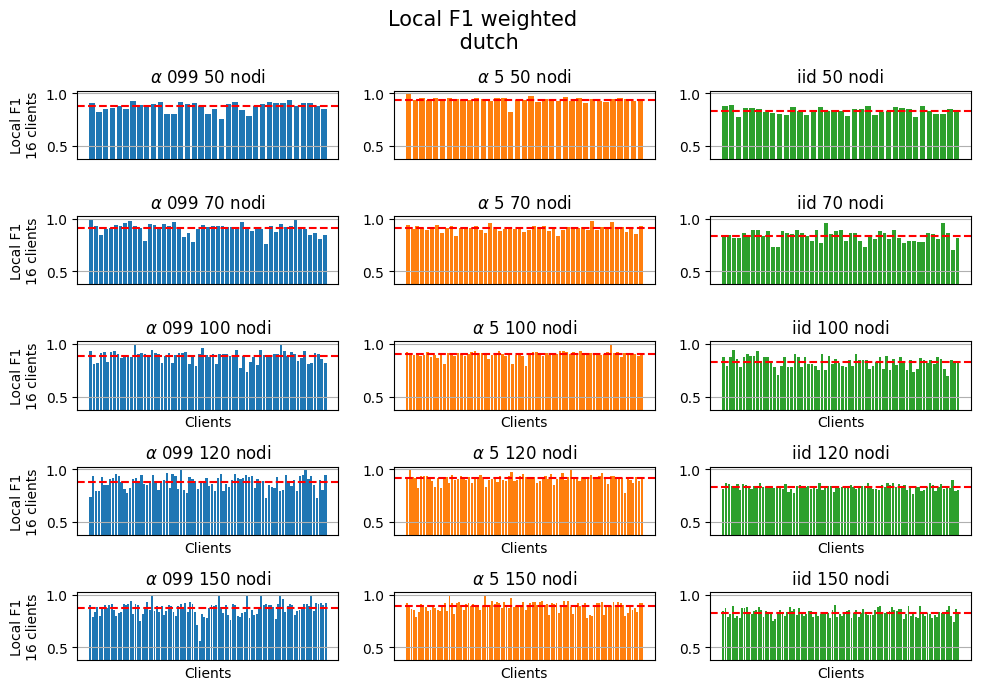

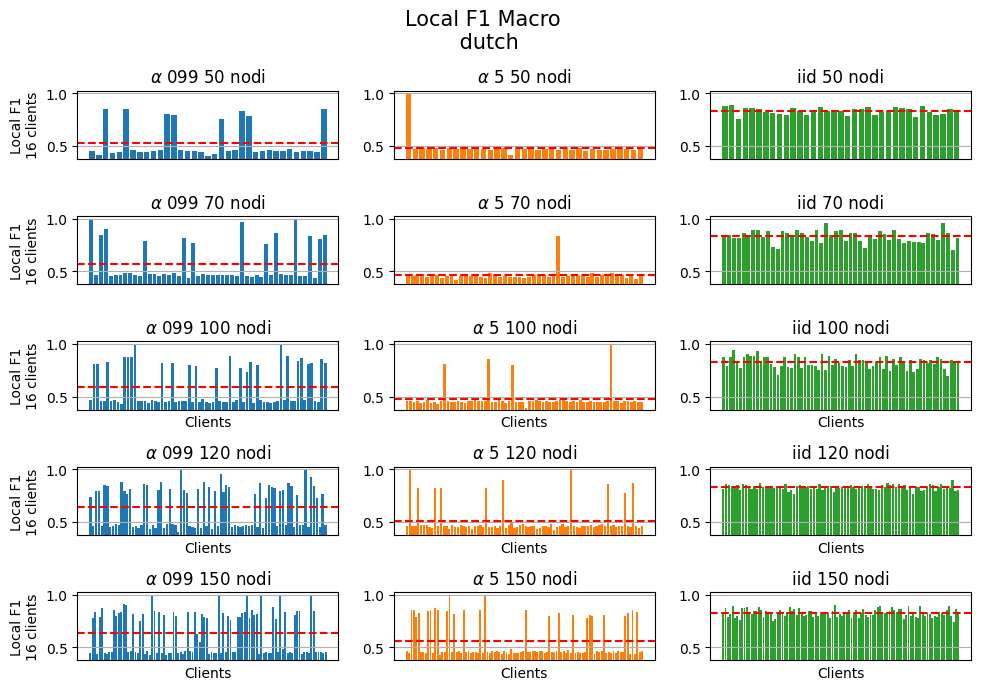

In [87]:

#QUIQUOQUA
#low_bound = 0.75
for m in ["weighted","Macro"]:
    if m == "weighted":
        values = all_weights_dict
    if m == "Macro":
        values = all_weights_dict_MACRO

    fig,axes = plt.subplots(5,3,figsize=(10,7))
    axes = axes.flatten()
    for j,k in enumerate(focus[::-1]):

        # use as color the jth color of the tab10 palette
        axes[j].bar(np.arange(np.array(values[k]).shape[0]),values[k],color=sns.color_palette("tab10")[j%3])
        title = " ".join(["imb "+k[0] if k[0]!='iid'else k[0]]+k[1].split("_"))
        title = title.replace("imb","$\\alpha$")

        axes[j].set_title(title)
        if j%3==0:
            
            axes[j].set_ylabel("Local F1\n"+("12 clients" if "12" in k else "16 clients"))
        if j>5:
            axes[j].set_xlabel("Clients")
        # only y grid
        axes[j].grid(axis='y')
        # set y limit
        axes[j].set_ylim(.375,1.025)
        axes[j].set_xticks([],[])
        #axes[j].set_yticks([0.5,0.75,1])
        # set font size
        axes[j].tick_params(axis='y', which='major', labelsize=10)
        # place a red line at the mean
        axes[j].axhline(np.mean(values[k]),color="red",linestyle="--")


        # add a lower bar plot with the stacked bar plot of positive and negative samples
        num_samples = all_num_samples[k]
        all_s = np.array(num_samples)[:,0]
        positiv,negativ = np.array(num_samples)[:,1],np.array(num_samples)[:,2]
        # axes[j].bar(np.arange(len(positiv)),-positiv,label="Positive",color="green")
        # axes[j].bar(np.arange(len(negativ)),-negativ,bottom=-positiv,label="Negative",color="red")




    plt.suptitle("Local F1 "+m+" \n"+" "+dt_name.split("_")[0],fontsize=15)
    plt.tight_layout()
    plt.savefig(dt_name+"_local_f1_weighted_bars.pdf")
    plt.show()
plt.close()


In [88]:
focus

[('iid', '150_nodi'),
 ('5', '150_nodi'),
 ('099', '150_nodi'),
 ('iid', '120_nodi'),
 ('5', '120_nodi'),
 ('099', '120_nodi'),
 ('iid', '100_nodi'),
 ('5', '100_nodi'),
 ('099', '100_nodi'),
 ('iid', '70_nodi'),
 ('5', '70_nodi'),
 ('099', '70_nodi'),
 ('iid', '50_nodi'),
 ('5', '50_nodi'),
 ('099', '50_nodi')]

0 4 150 nodi ('iid', '150_nodi') 0.8283158526814611
1 4 150 nodi ('5', '150_nodi') 0.8912052238506165
2 4 150 nodi ('099', '150_nodi') 0.868991372915771
3 2 120 nodi ('iid', '120_nodi') 0.8308124867017503
4 2 120 nodi ('5', '120_nodi') 0.9126287877404283
5 2 120 nodi ('099', '120_nodi') 0.875696955704582
6 3 100 nodi ('iid', '100_nodi') 0.8282544314673408
7 3 100 nodi ('5', '100_nodi') 0.9018955806160273
8 3 100 nodi ('099', '100_nodi') 0.8841226121542007
9 1 70 nodi ('iid', '70_nodi') 0.8334898672630505
10 1 70 nodi ('5', '70_nodi') 0.9063494938951653
11 1 70 nodi ('099', '70_nodi') 0.9066477881007431
12 0 50 nodi ('iid', '50_nodi') 0.8343723166056278
13 0 50 nodi ('5', '50_nodi') 0.9382734454829178
14 0 50 nodi ('099', '50_nodi') 0.873562673645595
['iid', '5', '099']
['iid', '5', '099']
['iid', '5', '099']
['iid', '5', '099']
['iid', '5', '099']


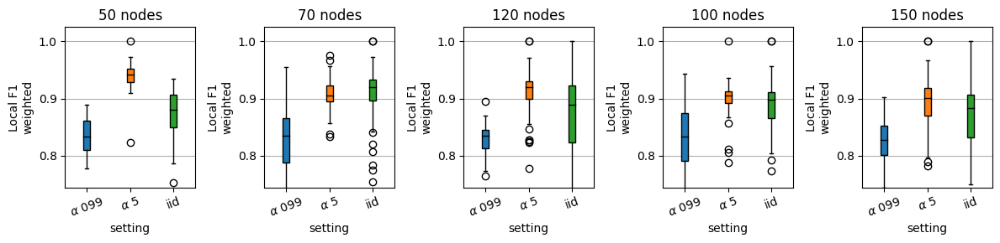

In [95]:


fig,axes = plt.subplots(1,5,figsize=(12,3))
axes = axes.flatten()
ticks = [[],[],[],[],[]]
low_bound = 0.745
# create barplots for the f1 weighted of the clients
# color them based on the setting as the j color of the tab10 palette

for posit,k in enumerate(focus):
    if "70" in k[1]:
        j=1
        title = "F1 wighted (70)"
    if '150' in k[1]:
        j=4
        title = "F1 wighted (150)"
    elif "50" in k[1]:
        j=0
        title = "F1 wighted (50)"
    elif "100" in k[1]:
        j=3
        title = "F1 wighted (100)"
    elif "120" in k[1]:
        j=2
        title = "F1 wighted (120)"
    if k[0] == "iid":
        i=0
    elif k[0] == "099":
        i=2
    elif k[0] == "5":
        i=1
    title = " ".join(k[1].split("_"))
    print(posit,j,title,k,np.mean(all_weights_dict[k]))
    patches = axes[j].boxplot(np.array(all_weights_dict[k]).T,positions=[i],patch_artist=True,showfliers=True)
    for patch in patches["boxes"]:
        patch.set_facecolor(sns.color_palette("tab10")[i])
    # set the mean in black
    for m_line in patches["medians"]:
        m_line.set_color("black")
    
    ticks[j].append(k[0])
    axes[j].set_title(title.replace("nodi","nodes"))
for j,ax in enumerate(axes):
    print(ticks[j])
    ax.grid(axis='y')
    ax.set_ylim(low_bound,1.025)
    ax.set_ylabel("Local F1\nweighted",fontsize=10)
    #for j,ax in enumerate(axes):
    tck = ticks[j]
    
    tck = [(" ".join(["imb "+k if k!='iid'else k])) for k in tck]
    
    tck = [tck_.replace("imb","$\\alpha$") for tck_ in tck]
    ax.set_xticks(np.arange(3),tck[::-1],rotation=20)
    axes[j].set_xlabel("setting")
    axes[j].set_yticks([0.80,0.90,1])
    #ax.set_xlabel("Clients")

plt.tight_layout()
plt.savefig(dt_name+"_local_f1_weighted_boxplot.pdf")
plt.show()
plt.close()

In [96]:
for exp in exps:
    # print the size of the samples explained 
    print(exp)
    te_X_feats,_,te_y_labs = load_dutch()
            # choose 2000 random
            
    exp_set = {}
    exp_set["X"] = te_X_feats
    exp_set["y"] = te_y_labs
    print(exp_set["X"].shape)
    # plot the shap explanations
    print(exp_set["y"].shape)
#result = compute_faithfulness(model,folder, all_shap_dict, 0,exp_dt)

('iid', '150_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('iid', '120_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('iid', '100_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('iid', '70_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('iid', '50_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('5', '150_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('5', '120_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('5', '100_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('5', '70_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('5', '50_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('099', '150_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2000,)
('099', '120_nodi')
Using ['sex_binary'] as sensitive feature(s).
(2000, 12)
(2

In [97]:
focus = exps
dt_name+"_"+folder,model_name,model_path,focus

('dutch_dutch/50_nodi/099',
 'aggregated_model_round_20.pth',
 'dutch/50_nodi/099/models/aggregated_model_round_20.pth',
 [('iid', '150_nodi'),
  ('iid', '120_nodi'),
  ('iid', '100_nodi'),
  ('iid', '70_nodi'),
  ('iid', '50_nodi'),
  ('5', '150_nodi'),
  ('5', '120_nodi'),
  ('5', '100_nodi'),
  ('5', '70_nodi'),
  ('5', '50_nodi'),
  ('099', '150_nodi'),
  ('099', '120_nodi'),
  ('099', '100_nodi'),
  ('099', '70_nodi'),
  ('099', '50_nodi')])

### Uncomment the next cell to create and save the actual files

In [98]:

base_values = sorted([-1.0,1.0,0.001,0.2,-0.2,])
all_faith_dict = {}
indexes_per_calss = {}
activations_of_models = {}
for exp in focus:
    if not exp in all_faith_dict.keys():
        print("computing faithfulness for",exp)
        
        print("Experiment:",exp)
        model_path = all_models_paths[exp]
        model = torch.load(model_path)
        print("model loaded from",model_path,"!")
        # load the data to explain that is saved in the samples folder
        path_ = os.path.sep.join([".",all_shap_folders[exp].replace("shap","samples"),
                                            "explain_samples_dutch_"+exp[1]+"_"+exp[0]+".npz"])
        print("loading",path_)
        test_s = load_npz(path_)
        exp_dt = TensorDataset(torch.Tensor(test_s["X"]),
                            torch.Tensor(np.eye(2)[test_s["y"]]))
        
        indexes, results_dict,activas = get_exps_faiths(neural_model=model,
                                                        exp = exp,
                                                        base_values = base_values,
                                                        all_shap_values_dict = all_shap_dict,
                                                        te_set = exp_dt)
        all_faith_dict[exp] = results_dict
        indexes_per_calss[exp] = indexes
        activations_of_models[exp] = activas




computing faithfulness for ('iid', '150_nodi')
Experiment: ('iid', '150_nodi')
model loaded from dutch/150_nodi/iid/models/aggregated_model_round_20.pth !
loading ./dutch_150_nodi_iid_samples/explain_samples_dutch_150_nodi_iid.npz
Base value: -1.0
(2000, 2)
Server:
	>0: 0.6325  		>0.7: 0.085
Clients:
	>0: 0.752  		>0.7: 0.089
	>0: 0.793  		>0.7: 0.0575
	>0: 0.815  		>0.7: 0.0895
	>0: 0.786  		>0.7: 0.11
	>0: 0.56  		>0.7: 0.0665
	>0: 0.828  		>0.7: 0.0625
	>0: 0.858  		>0.7: 0.062
	>0: 0.814  		>0.7: 0.055
	>0: 0.853  		>0.7: 0.065
	>0: 0.578  		>0.7: 0.079
	>0: 0.7505  		>0.7: 0.063
	>0: 0.891  		>0.7: 0.052
	>0: 0.8115  		>0.7: 0.055
	>0: 0.688  		>0.7: 0.0885
	>0: 0.5435  		>0.7: 0.0835
	>0: 0.8015  		>0.7: 0.064
	>0: 0.5225  		>0.7: 0.0765
	>0: 0.83  		>0.7: 0.089
	>0: 0.5125  		>0.7: 0.067
	>0: 0.8145  		>0.7: 0.0535
	>0: 0.5415  		>0.7: 0.0675
	>0: 0.8045  		>0.7: 0.0535
	>0: 0.5475  		>0.7: 0.1155
	>0: 0.833  		>0.7: 0.0605
	>0: 0.6385  		>0.7: 0.09
	>0: 0.5375  		>0.7: 0.0535
	

In [99]:
activations_of_models = {}
indexes_per_class = {}
for exp in focus:
    print(exp)
    model = torch.load(all_models_paths[exp])
    activations_of_models[exp] = {}
    activations_of_models[exp][100] = model(torch.Tensor(exp_set["X"])).detach().numpy()
    activations_of_models[exp][1000] = activations_of_models[exp][100]
    class_idxs = []
    for i in range(2):
        class_idxs.append(np.where(exp_set["y"]==i))

    indexes_per_class[exp] = class_idxs
activations_of_models.keys(),len(activations_of_models[exp]),


('iid', '150_nodi')
('iid', '120_nodi')
('iid', '100_nodi')
('iid', '70_nodi')
('iid', '50_nodi')
('5', '150_nodi')
('5', '120_nodi')
('5', '100_nodi')
('5', '70_nodi')
('5', '50_nodi')
('099', '150_nodi')
('099', '120_nodi')
('099', '100_nodi')
('099', '70_nodi')
('099', '50_nodi')


(dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]),
 2)

In [100]:
all_faith_dict[exp][100]["Server"].shape

KeyError: 100

In [101]:
# assert that the faithfulness is computed for the same experiments as the shap values
for k in all_shap_dict.keys():
    if not k in all_faith_dict.keys():
        print(k,"not in faithfulness")
    if not k in indexes_per_calss.keys():
        print(k,"not in indexes")
    if not k in activations_of_models.keys():
        print(k,"not in activations")


In [103]:

# the keys are tuple, so we have to join them to save the file
import json
with open(dt_name+"_all_faith_dict.json","w+") as f:
    # convert the numpy arrays to lists
    
    all_faith_dict_list = {"%".join([str(el) for el in k]):
                            {base_value:
                                {k2:list([list(values) for values in v2])
                                for k2,v2 in serverclient.items()}
                            for base_value,serverclient in v.items()}
                        for k,v in all_faith_dict.items()}
    json.dump(all_faith_dict_list,f)
with open(dt_name+"_indexes_per_calss.json","w+") as f:
    indexes_per_calss_list = {"%".join([str(el) for el in k]):
                              [(v1.tolist() if not isinstance(v1,list) else v1)
                               for v1 in v] for k,v in indexes_per_calss.items()}
    json.dump(indexes_per_calss_list,f)

with open(dt_name+"_activations_of_models.json","w+") as f:
    activations_of_models_list = {"%".join([str(el) for el in k]):
                                  {k1:(v1.tolist() if not isinstance(v1,list) else v1)
                                   for k1,v1 in v.items()} for k,v in activations_of_models.items()}
    json.dump(activations_of_models_list,f)
    

#### Load the files

In [99]:

import json

with open(dt_name+"_indexes_per_calss.json", "r") as f:
    indexes_per_calss_list = json.load(f)

indexes_per_calss = {tuple(k.split("%")):
                      np.array([np.array(v1) for v1 in v]) for k, v in indexes_per_calss_list.items()}
with open(dt_name+"_activations_of_models.json", "r") as f:
    activations_of_models_list = json.load(f)



activations_of_models = {tuple(k.split("%")):
                         {float(k1): np.array(v1) for k1, v1 in v.items()} for k, v in activations_of_models_list.items()}

# Now you have loaded dictionaries: all_faith_dict, indexes_per_calss, activations_of_models
# Convert the lists back to NumPy arrays
with open(dt_name+"_all_faith_dict.json", "r") as f:
    all_faith_dict_list = json.load(f)
all_faith_dict = {tuple(k.split("%")):
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_list.items()}
all_shap_dict[list(all_shap_dict.keys())[0]].keys()


Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta'])

In [107]:
all_faith_dict.keys(),all_faith_dict[exps[0]].keys()
all_faith_dict[exps[0]][100].keys(),all_faith_dict[exps[0]][100]["Server"].shape

KeyError: 100

In [105]:
model,model(torch.Tensor(exp_dt.tensors[0]))

(LinearClassificationNetValerio(
   (layer1): Linear(in_features=12, out_features=64, bias=False)
   (layer2): Linear(in_features=64, out_features=2, bias=False)
 ),
 tensor([[-0.9664,  0.8185],
         [-1.0492,  1.0152],
         [ 2.2572, -2.7009],
         ...,
         [-1.8927,  1.6030],
         [ 1.5447, -2.5638],
         [-0.7710,  0.6530]]))

In [106]:
print(activations_of_models.keys(),activations_of_models[exps[0]].keys(),)
activations_of_models[exps[0]][100]

dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]) dict_keys([100, 1000])


array([[-1.1059897 ,  1.0773867 ],
       [-0.7364466 ,  0.65093255],
       [ 1.8626248 , -1.7233877 ],
       ...,
       [-1.8107609 ,  1.7875118 ],
       [ 2.8917682 , -2.792801  ],
       [-0.87363756,  0.87857705]], dtype=float32)

In [104]:
all_faith_dict.keys(),all_faith_dict[exps[-1]].keys(),all_faith_dict[exps[0]][1000].keys()

(dict_keys([('iid', '50_nodi'), ('iid', '70_nodi'), ('iid', '150_nodi'), ('5', '50_nodi'), ('5', '70_nodi'), ('5', '150_nodi'), ('099', '50_nodi'), ('099', '70_nodi'), ('099', '150_nodi')]),
 dict_keys([100.0, 1000.0]),
 dict_keys(['Server', 'Clients']))

In [136]:
all_base_values = {exp:{} for exp in focus}
def check_compute_faithfulness(neural_model,exp, all_shap_values_dict, base_value,te_set,local_mean=False,store_base_values={},compute=False):

    shap_values_dict = all_shap_values_dict[exp]
    model = aix_model(neural_model)
    num_clients = len(shap_values_dict["Clients"])
    # for every class get the indices of the samples so that we can return the indexes of the samples of that class
    class_idxs = []
    num_classes = te_set.tensors[1].shape[1]
    # now substitute the tensors[1] with its argmax
    ordinal_targets = te_set.tensors[1].argmax(axis=1)
    for i in range(num_classes):
        class_idxs.append(np.where(ordinal_targets == i)[0])
    x = te_set.tensors[0].numpy()
    
    faith_dict = {"Server": [], "Clients": []}

    activations = model.predict_proba(x)
    print(activations.shape)
    all_base_values = []

    train_nodes = all_train_nodes[exp]
    for client_id in range(num_clients + 1):
        if client_id == 0:
            key = "Server"
            coefs = shap_values_dict[key]
        else:
            key = "Clients"
            coefs = shap_values_dict[key][client_id - 1]

        
        faits = []
        num_samples = 2000
        # load the train data of the node

        folder = os.path.join(foldern,exp[1],exp[0])
        print(client_id,key,train_nodes[client_id - 1],client_id - 1,folder)
        
        if client_id == 0:
            all_X_feat, all_y_labs = np.array([]),np.array([])
            for noed in train_nodes:
                X_feat, y_labs = load_train_set(node=noed,folder=folder)
                
                all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat
                all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs

            all_X_feat = torch.Tensor(all_X_feat)
            data = all_X_feat,42
        else:
            data = load_train_set(node=train_nodes[client_id - 1],folder=folder)
        # compute the mean of the train data

        print(data[0].shape)
        mean = data[0].mean(axis=0)
        # compute the mean of the means
        base_value = data[0].mean()
        all_base_values.append(base_value)
        #print("mean",mean)
        #print("base value",base_value)
        print(key)
        if compute:
            for sample, fi in zip(x[:num_samples], coefs[:num_samples]):
            
                faith_m = faithfulness_metric(model=model,
                                          x=sample,
                                          coefs=fi,
                                          base=(mean if local_mean else base_value * np.ones(shape=fi.shape[0])),
                                          )
            
                faits.append(faith_m)
        
            faith_dict[key].append(np.array(faits))
            '''
            if key != "Server":

                plt.plot(mean,alpha=0.5)
            else:
                plt.plot(mean,label=key)
            '''
        if local_mean:
            store_base_values[exp][100] = mean
        else:
            store_base_values[exp][1000] = base_value * np.ones(shape=data[0].shape[1])
    '''
    plt.title("Mean of the features for experiment "+str(exp))
    plt.legend()
    plt.show()
    plt.plot(sorted(all_base_values))
    plt.hlines(all_base_values[0],0,len(all_base_values),color="red")
    plt.show()
    '''

    return class_idxs,faith_dict,activations
for exp in focus:
    print(exp)
    if exp[1] == "50_nodi":
        print(exp, "to compute")
        compute = False
    else:
        compute = False
    compute = True
    model = torch.load(all_models_paths[exp])

    print("loading model from",all_models_paths[exp])
    _,new_f_local_mean,_ = check_compute_faithfulness(model,exp,all_shap_dict,0,exp_dt,local_mean=False,store_base_values=all_base_values,compute=compute)


    _, new_f_mean_mean,_ = check_compute_faithfulness(model,exp,all_shap_dict,0,exp_dt,local_mean=True,store_base_values=all_base_values,compute=compute)
    # if exp not in all_faith_dict.keys():
    #     #all_faith_dict[exp] = {}
    if True:# not 100 in all_faith_dict[exp].keys():
        print("adding 100")
        all_faith_dict[exp][100] = new_f_local_mean
        all_faith_dict[exp][100]["Clients"] = np.array(all_faith_dict[exp][100]["Clients"])
        all_faith_dict[exp][100]["Server"] = np.array(all_faith_dict[exp][100]["Server"])
    if True:#not 1000 in all_faith_dict[exp].keys():
        print("adding 1000")
        all_faith_dict[exp][1000]=new_f_mean_mean
        all_faith_dict[exp][1000]["Clients"] = np.array(all_faith_dict[exp][1000]["Clients"])
        all_faith_dict[exp][1000]["Server"] = np.array(all_faith_dict[exp][1000]["Server"])
    else:
        keys = all_faith_dict[exp].keys()
        assert 100 in keys and 1000 in keys, "missing keys:"+str(keys)
        print("ok")
    break
print(all_faith_dict_list.keys())




('iid', '150_nodi')
loading model from dutch/150_nodi/iid/models/aggregated_model_round_20.pth
(2000, 2)
0 Server 149 -1 dutch/150_nodi/iid
torch.Size([38900, 12])
Server
1 Clients 1 0 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
2 Clients 2 1 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
3 Clients 3 2 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
4 Clients 4 3 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
5 Clients 5 4 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
6 Clients 6 5 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
7 Clients 7 6 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
8 Clients 8 7 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
9 Clients 9 8 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
10 Clients 10 9 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
11 Clients 11 10 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
12 Clients 12 11 dutch/150_nodi/iid
torch.Size([389, 12])
Clients
13 Clients 13 12 dutch/150_nodi/iid
torch.Size([389, 12])
Clients

In [137]:
all_faith_dict[exp][100]["Clients"].shape

(100, 2000)

In [138]:
all_faith_dict[exp].keys(),partitions,distribs

(dict_keys([-1.0, -0.2, 0.001, 0.2, 1.0, 100, 1000]),
 ['150_nodi', '120_nodi', '100_nodi', '70_nodi', '50_nodi'],
 ['iid', '5', '099'])

In [157]:
for p in partitions:
    for d in distribs[::-1]:
        for bv in all_faith_dict[(d,p)].keys():
            try:
                all_faith_dict[(d,p)][bv]["Clients"].shape
                print("Experiment:",(d,p),"Base value:",bv)
                if isinstance(all_faith_dict[(d,p)][bv]["Server"],list):
                    print(all_faith_dict[(d,p)][bv]["Server"].shape)
                else:
                    print(all_faith_dict[(d,p)][bv]["Server"].shape)
            except Exception as e:
                print("exception:",e)
                print("Error in retrieving shapes for",(d,p),bv,e)
            

exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('099', '150_nodi') -1.0 'list' object has no attribute 'shape'
exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('099', '150_nodi') -0.2 'list' object has no attribute 'shape'
exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('099', '150_nodi') 0.001 'list' object has no attribute 'shape'
exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('099', '150_nodi') 0.2 'list' object has no attribute 'shape'
exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('099', '150_nodi') 1.0 'list' object has no attribute 'shape'
Experiment: ('099', '150_nodi') Base value: 100
(2000,)
Experiment: ('099', '150_nodi') Base value: 1000
(2000,)
exception: 'list' object has no attribute 'shape'
Error in retrieving shapes for ('5', '150_nodi') -1.0 'list' object has no attribute 'shape'
exception: 'list' ob

150_nodi 099

Faithfulnesses for base value -1.0
Server 0.19545357868813476 0.3239923233991103 (2000,)

Faithfulnesses for base value -0.2
Server 0.31739067824932227 0.31921750968711904 (2000,)

Faithfulnesses for base value 0.001
Server 0.43572562324756553 0.38903098037415745 (2000,)

Faithfulnesses for base value 0.2
Server 0.3916977015235491 0.4156822346060267 (2000,)

Faithfulnesses for base value 1.0
Server -0.28250055682609987 0.46812632616307454 (2000,)



Faithfulnesses for base value 100
Server 0.3419059384557907 0.4714554756705829 (2000,)

Faithfulnesses for base value 1000
Server 0.02132952838010999 0.8823631376531371 (2000,)
150_nodi 5

Faithfulnesses for base value -1.0
Server 0.19234763500298 0.33520362926459535 (2000,)

Faithfulnesses for base value -0.2
Server 0.3233113480174681 0.3333385991025428 (2000,)

Faithfulnesses for base value 0.001
Server 0.43448623646407497 0.38712252974122124 (2000,)

Faithfulnesses for base value 0.2
Server 0.3864315074966505 0.40513464771857993 (2000,)

Faithfulnesses for base value 1.0
Server -0.29720165886024763 0.5067783654468192 (2000,)

Faithfulnesses for base value 100
Server 0.33901468677476376 0.45992466462618786 (2000,)

Faithfulnesses for base value 1000
Server 0.033477475496720116 0.8548614454956901 (2000,)
150_nodi iid

Faithfulnesses for base value -1.0
Server 0.18874747603077813 0.3242891952435363 (2000,)

Faithfulnesses for base value -0.2
Server 0.3185283441883469 0.315610613902825

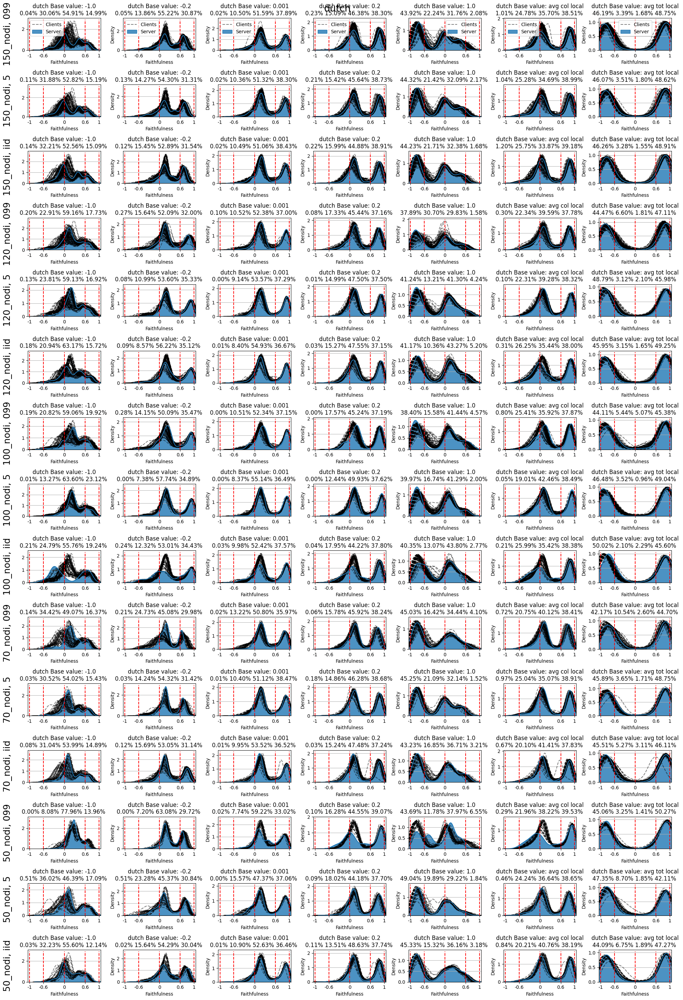

In [159]:
# the fill color is based soley on the dataset, orange for dry bean, blue for dutch, red for adult, light blue for diamonds



n_bvs = len(sorted(all_faith_dict[exps[0]].keys()))
fig,ax = plt.subplots(len(partitions)*len(distribs),n_bvs,figsize=(20,30))
ax = ax.reshape(-1)
o_i = 0
for p in partitions:
    for d in distribs[::-1]:
        # now we plot the faithfulnesses:
        exp = (d,p)
        print(p,d)
        # create the figure with as many subplots as the number of base values
        # then plot the distribution of the faithfulnesses of all the nodes with a low opacity
        # then plot the faithfulness of the server with a higher opacity
        base_values = sorted(all_faith_dict[exp].keys())
        for j,bv in enumerate(base_values):
                j+=n_bvs*o_i
                # get the faithfulnesses
                ff = all_faith_dict[exp][bv]
                print()
                # get the indexes of the classes
                indexes = indexes_per_calss[exp]
                # get the activations of the model
                activas = activations_of_models
                # plot the faithfulnesses
                print("Faithfulnesses for base value",bv)
                print("Server",ff["Server"].mean(),ff["Server"].std(),ff["Server"].shape)
                for i in range(len(ff["Clients"])):
                    # plot the faithfulness of the nodes
                    if i == 0:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False,label="Clients")
                    else:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False)
                # plot the faithfulness of the server
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],label="Server",fill=True,alpha=0.8,cumulative=False)
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False)
                trs = [-0.6,0,0.6]
                trs = [-1]+trs+[1]
                percs = []
                title_addition = ''
                for i in range(len(trs) - 1):
                    lower = trs[i]
                    upper = trs[i+1]
                    pperc = ((np.array(ff["Clients"][:]) > lower) & (np.array(ff["Clients"][:]) <= upper)).mean()
                    perc = np.round(pperc * 100, 2)
                    percs.append(perc)
                    title_addition += f"{perc:.2f}% "

                ylim = ax[j].get_ylim()

                ax[j].vlines(trs,0,ylim[1],colors="red",linestyles="--")

                # set the xticks at -1,-0.6,0,0.6,1
                ax[j].set_xticks(trs)

                # set the xticks labels
                ax[j].set_xticklabels([str(t) for t in trs])
                # add to the title the average percentage of client's explanations that are less than -0.6

                if bv == 100:
                    bv = 'avg col local'
                if bv == 1000:
                    bv = 'avg tot local'
                ax[j].set_title(f"{dt_name} Base value: {bv}\n{title_addition}")
                ax[j].set_xlabel("Faithfulness")
                ax[j].set_ylabel("Density") 
                # fix the x limits
                ax[j].set_xlim(-1.05,1.05)
                # set the y grid
                ax[j].grid(axis="y")

                # plot vertical lines at -0.6, 0 and 0.6
                # if the subplot is the first of the row, set the ylabel as the p and d
                if j%len(base_values) == 0:
                    ax[j].set_ylabel(p+", "+d,rotation=90,labelpad=20,fontsize=19)
                # if the subplot is the first raw set the legend
                if j < len(base_values):
                    ax[j].legend()
        o_i+=1 
plt.suptitle(dt_name,fontsize=20)
plt.tight_layout()
plt.show()

In [160]:
all_base_values

{('iid',
  '150_nodi'): {1000: tensor([0.3459, 0.3459, 0.3459, 0.3459, 0.3459, 0.3459, 0.3459, 0.3459, 0.3459,
          0.3459, 0.3459, 0.3459], dtype=torch.float64), 100: tensor([0.3821, 0.1915, 0.2314, 0.0283, 0.0180, 0.0578, 0.6406, 0.0923, 0.7653,
          0.2579, 0.4859, 1.0000])},
 ('iid', '120_nodi'): {},
 ('iid', '100_nodi'): {},
 ('iid', '70_nodi'): {},
 ('iid', '50_nodi'): {},
 ('5', '150_nodi'): {},
 ('5', '120_nodi'): {},
 ('5', '100_nodi'): {},
 ('5', '70_nodi'): {},
 ('5', '50_nodi'): {},
 ('099', '150_nodi'): {},
 ('099', '120_nodi'): {},
 ('099', '100_nodi'): {},
 ('099', '70_nodi'): {},
 ('099', '50_nodi'): {}}

ShapGap L2: 0.2719675293786304
ShapGap Kendall: 0.9230769230769231
ShapGap Cosine: 0.9092454939995261
ShapGap Spearman: 0.9807017543859651


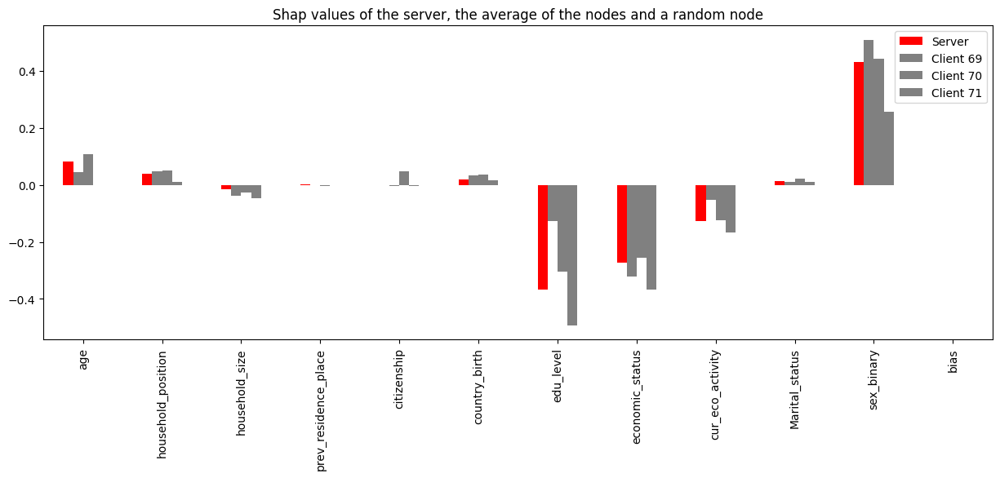

0.10859131266382371
-0.008677270263433456
-0.7836758625693618


In [161]:
# take a random sample
random_sample = np.random.choice(np.arange(len(exp_set["X"])),1)[0]
random_sample
# add the explanation of the random sample of the server of the E_hat and of the random node to a dataframe and plot the bars relative to the explanation values
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
train_nodes = all_train_nodes[list(all_shap_dict.keys())[0]]
random_train_node = np.random.choice(train_nodes)
random_client = list(train_nodes).index(random_train_node)
df = pd.DataFrame({"Server":all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                     #"E_hat":all_shap_dict[list(all_shap_dict.keys())[0]]["E_hat"][random_sample],
                     "Client "+str(random_client):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample],
                     "Client "+str(random_client+1):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+1][random_sample],
                     "Client "+str(random_client+2):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+2][random_sample]}
                     ,index=feat_names)
# the bar relative to the server should be red
# all the other bars should be in gray shades
colors = ["red"]+["gray"]*3
plt.figure(figsize=(15,5))
df.plot(kind="bar",color=colors,ax=plt.gca())


# compute the metrics of the example explanations wrt the server
shapgap_l2 = single_Frobs_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_kendall = single_kendalltau_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_cos = single_cosinesim_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_spearman = single_spearmanr_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
print("ShapGap L2:",shapgap_l2)
print("ShapGap Kendall:",shapgap_kendall)
print("ShapGap Cosine:",shapgap_cos)
print("ShapGap Spearman:",shapgap_spearman)

plt.title("Shap values of the server, the average of the nodes and a random node")

plt.show()

for i in range(3):
    print(all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+i][random_sample].sum())

In [162]:
all_shap_folders

{('iid', '50_nodi'): 'dutch_50_nodi_iid_shap',
 ('iid', '70_nodi'): 'dutch_70_nodi_iid_shap',
 ('iid', '100_nodi'): 'dutch_100_nodi_iid_shap',
 ('iid', '120_nodi'): 'dutch_120_nodi_iid_shap',
 ('iid', '150_nodi'): 'dutch_150_nodi_iid_shap',
 ('5', '50_nodi'): 'dutch_50_nodi_5_shap',
 ('5', '70_nodi'): 'dutch_70_nodi_5_shap',
 ('5', '100_nodi'): 'dutch_100_nodi_5_shap',
 ('5', '120_nodi'): 'dutch_120_nodi_5_shap',
 ('5', '150_nodi'): 'dutch_150_nodi_5_shap',
 ('099', '50_nodi'): 'dutch_50_nodi_099_shap',
 ('099', '70_nodi'): 'dutch_70_nodi_099_shap',
 ('099', '100_nodi'): 'dutch_100_nodi_099_shap',
 ('099', '120_nodi'): 'dutch_120_nodi_099_shap',
 ('099', '150_nodi'): 'dutch_150_nodi_099_shap'}

In [163]:
import matplotlib.ticker as ticker

In [164]:
b_v = 1000

In [165]:
def plot_faith_dry(exp,faits,all_shap_values_dict,te_set,top_k,activations = None,show_samples=10,chosen_idxs=None,show=True,vmax=None,vmax_diff = 1.5 ,dt_name = "dt_name",feat_names=None):
    ''' find the index of the experiment in the dictionaries'''
    #faits = all_faith_dict[exp]
    # create the figure
    # create the matrix of faithfulness
    # the first col is the server, the others are the clients
    # the first row is the faithfulness of the first sample, the others are the other samples
    # so the matrix is 4x5
    fontsize = 20
    print (exp,faits["Server"].shape,"faits[\"server\"] shape")
    

    ff = np.zeros((len(faits["Server"][0]),len(faits["Clients"])+1))
    
    # fill the matrix
    ff[:,0] = faits["Server"][0]
    for c in range(len(faits["Clients"])):
        
        ff[:,c+1] = faits["Clients"][c]
    # plot the matrix
    print(ff.shape)
    # choose 32 random samples
    #random_idxs = np.random.choice(np.arange(len(ff)),32)
    plt.clf()
    # create 2 subplots
    fig, axes = plt.subplots(1,3,figsize=(20,10))
    ax_density = axes[0]
    ax_cdf = axes[1]
    ax_boxplot = axes[2]
    # create a color map with as many colors as the number of classes
    # the color map is used to color the samples based on the class
    cmap = sns.color_palette("tab10", len(chosen_idxs))
    
    if not chosen_idxs is None:
        samples_per_class = show_samples // len(chosen_idxs)
        print(samples_per_class,"samples per class")
        # if this is true, chosen_idxs ia a list of lists of indexes
        # divided by class
        # so for each one of the classes, we want to plot show_samples samples // num_classes
        # so we take the first show_samples // num_classes samples of each class
        # but not randomly, we take the equally spaced samples from the most faithful to the least faithful of that class
        random_idxs = []
        all_tp = []
        all_fp = []
        yticks = []
        predicted_ticks = []

        for i in range(len(chosen_idxs)):
            idxs = chosen_idxs[i]
            idxs = np.array(idxs)
            # now select the faithfulness values of the samples of that class
            faiths = ff[idxs]
            
            # print the min and max of the faithfulness values and the client idx or the server
            #print("class",i,"min",np.min(faiths,axis=0),"max",np.max(faiths,axis=0))

            ### SORTED BY FAITHFULNESS VALUES of the SERVER
            # sort the indexes of the samples of that class by the faithfulness values
            sorted_idxs = np.argsort(faiths[:,0])[::-1]
            # take the equally spaced indexes of the sorted indexes
            idx_of_idxs = np.arange(len(sorted_idxs),step=len(sorted_idxs)//samples_per_class)
            idx_of_idxs = np.array(idx_of_idxs)[:samples_per_class] # take only the first samples_per_class

            ### SORTED BY FAITHFULNESS std of all the clients and the server
            # sort the indexes of the samples of that class by the standard deviation of the faithfulness values
            maximum_std_sorted_idxs = np.argsort(np.std(faiths,axis=1))[::-1]
            # within those samples, place the true positives at the beginning and the false positives at the end
            sorted_idxs = maximum_std_sorted_idxs

            
            # visualize the std of the faithfulness values of the samples at maximum_std_sorted_idxs
            values = np.std(faiths[maximum_std_sorted_idxs]
            ,axis=1)
            # remove the nans
            values = values[~np.isnan(values)]
            ax_density.plot(values,label="std(faits)\n for class "+str(i))

            # now use the same data to plot the boxplot
            # the x axis is the class
            # the y axis is for the boxes the std of the faithfulness values
            # in the label place the percentiles of the std of the faithfulness values, 25, 50, 75
            label = "std(faits)\n for class "+str(i)
            label+="\n25th percentile:"+str(np.percentile(values,25).round(2))
            label+="\n50th percentile:"+str(np.percentile(values,50).round(2))
            label+="\n75th percentile:"+str(np.percentile(values,75).round(2))

            return_dict = ax_boxplot.boxplot(values,positions=[i],patch_artist=True,showfliers=True)
            patches = return_dict["boxes"]
            # set the color of the boxes
            print(len(patches),"patches")
            # check if there are NaNs
            if np.isnan(values).sum()>0:
                print("class",i)
                print("Nans in the std of the faithfulness values")
            for patch in patches:
                patch.set_facecolor(cmap[i])
            # add the label at the position of the x tick
            
            sorted_idxs = np.array(sorted_idxs)
            # take the most discordant samples based on the std of the faithfulness values
            idx_of_idxs = np.arange(samples_per_class)
            # chosen samples are the ones with the highest std of the faithfulness values
            # we place the true positives at the beginning and the false positives at the end
            high_std_idxs = list(idxs[sorted_idxs[idx_of_idxs]])
            tp_first = []
            fp_last = []
            for e in high_std_idxs:
                if activations[e].argmax() == i:
                    tp_first.append(e)
                else:
                    fp_last.append(e)
            # order both the tp and the fb by the magnitude of the prediction probability
            tp_first = sorted(tp_first,key=lambda x:activations[x].max(),reverse=True)
            fp_last = sorted(fp_last,key=lambda x:activations[x].max(),reverse=True)

            assert len(tp_first)+len(fp_last) == len(high_std_idxs)
            # re-add the indexes to the list of "random indexes"
            random_idxs = random_idxs + tp_first+fp_last
            all_tp+=tp_first
            all_fp+=fp_last
            
            if len(yticks)>0:
                off = yticks[-1]
            else:
                off = 0
            predicted_ticks.append(off+len(tp_first))
            predicted_ticks.append(off+len(tp_first)+len(fp_last))
            print(off)
            print(predicted_ticks)

            yticks.append(len(random_idxs))
        if not vmax is None:
            # get the current y limits

            ymin,ymaxold = ax_density.get_ylim()
            ax_density.set_ylim(0,vmax)
            ax_boxplot.set_ylim(0,vmax)
        
        # place the xticks
        ax_boxplot.set_xticks(np.arange(len(chosen_idxs)),["class "+str(i) for i in range(len(chosen_idxs))])
        for axx in [ax_density,ax_boxplot,ax_cdf]:
            # set the grid
            axx.grid(True)
            axx.legend(fontsize=18)
            # set the font of the ticks
            axx.tick_params(axis='both', which='major', labelsize=18)
        
        # using the sns.kdeplot, we can plot the cumulative distribution function of the faithfulness values of the samples of the clients and the server 
        # the x axis is the faithfulness values, the y axis is the cumulative distribution function
        for i in range(len(chosen_idxs)):
            idxs = chosen_idxs[i]
            # find any samples that have NaNs in the faithfulness values of any of the clients or the server and remove them
            idxs = np.array(idxs)
            faiths = ff[idxs,:]
            #faiths = np.abs(ff[idxs,:])
            
            print(type(faiths),"type of faiths",faiths.shape,"shape of faiths")
            # plot the cumulative distribution function of the faithfulness values of the samples of the clients and the server
            sns.kdeplot(faiths[:,0],ax=ax_cdf,label="Server",cumulative=True,lw=3)
            for c in range(len(faits["Clients"])):
                if c==0:
                    label="Clients, class "+str(i)
                else:
                    label=None
                sns.kdeplot(faiths[:,c+1],ax=ax_cdf,label=label,cumulative=True,ls='--',color=cmap[i])
        ax_cdf.set_xlim(-1.5,1.5)
        ax_cdf.set_ylim(-0.05,1.05)
        ax_boxplot.set_title("std of the faithfulness values per class")
        ax_density.set_title("std of the faithfulness values")


        # set the title
        ax_cdf.set_title("Cumulative distribution function of the faithfulness values per class, ")
        # set the x label
        ax_cdf.set_xlabel("faithfulness values")
        # set the y label
        ax_cdf.set_ylabel("cumulative distribution function")
        # set the legend
        ax_cdf.legend()
        if not vmax is None:
            for axe_ in [ax_density,ax_boxplot]:
                curr_ylim = axe_.get_ylim()

                axe_.set_ylim(curr_ylim[0],vmax)
        

        plt.suptitle(str(exp)+"\nstd of the client's faithfulness\n values of the explanations of the samples",fontsize=20)
        plt.tight_layout()
        if show:
            plt.show()
        else:
            # save the plot
            plt.savefig(dt_name+"_"+"_".join([str(e4) for e4 in exp])+"_std_of_faithfulness_values.pdf")
        plt.close()

    # plot the examples AND the coefficients of the Server and the E_hat
    fig, axes = plt.subplots(1,1+len(top_k),figsize=(20,10))

    # Rename axes for clarity
    faithfulness_ax =       axes[0]
    top_3_agg_ax =          axes[1:]
    activations_ax =        axes[-1]
            
    activations_ax.imshow(activations[random_idxs],interpolation='none',cmap='gray', rasterized=True)
    activations_ax.set_aspect('auto')
    for ax in axes:
        for y in yticks[:-1]:
            print(y,"axes is",ax)
            ax.axhline(y-0.5, color='black', lw=3)
    for j,top_agg in enumerate(top_k):
        
        select_axis = top_3_agg_ax[j]
        print("EXPLAINED SHAPE",all_shap_values_dict[exp][top_agg][random_idxs].shape)

        print(random_idxs[:10])
        print((all_shap_values_dict[exp]["Server"][random_idxs]-
                           all_shap_values_dict[exp][top_agg][random_idxs]).std(0))
        select_axis.imshow(all_shap_values_dict[exp]["Server"][random_idxs]-
                           all_shap_values_dict[exp][top_agg][random_idxs],
                           interpolation='none',cmap='bwr', rasterized=True,
                           vmin=-abs(vmax_diff),vmax=abs(vmax_diff))
        select_axis.set_aspect('auto')
        select_axis.set_title("difference from the audit of\n"+top_agg,fontsize=fontsize)
        select_axis.set_xticks(np.arange(len(feat_names)),feat_names,rotation=90,ha='center',fontsize=fontsize-3)


    # Plot the coefficients
    im2 = faithfulness_ax.imshow(ff[random_idxs,:],interpolation='none',vmin=-1,vmax=1,cmap='coolwarm', rasterized=True)
    #print(ff[random_idxs[0],:],"worst")
    #print(ff[random_idxs[-1],:])
    #print()
    
    abs_recomputed_yticks = [0]+yticks
    
    recomputed_yticks = [(abs_recomputed_yticks[i]+abs_recomputed_yticks[i+1])//2 for i in range(len(abs_recomputed_yticks)-1)]
    #sec.set_yticks(recomputed_yticks,["class "+str(i)+"\n\n" for i in range(len(chosen_idxs))],rotation=90,ha='right')
    #sec3 = faithfulness_ax.secondary_yaxis(location=0)
    predicted_ticks = [0]+predicted_ticks

    recomputed_predicted = [(predicted_ticks[i]+predicted_ticks[i+1])//2 for i in range(len(predicted_ticks)-1)]
    
    #sec3.set_yticks(recomputed_predicted,["TP","FP"]*len(chosen_idxs),rotation=90)#,ha='right')
    
    
    # now we do the same but using the twinx to get second Y-axis
    ax2 = faithfulness_ax.twinx()
    ax2.spines["left"].set_position(("axes", -0.2))
    ax2.tick_params('both', length=0, width=0, which='minor')
    ax2.tick_params('both', direction='in', which='major')
    ax2.yaxis.set_ticks_position("left")
    ax2.yaxis.set_label_position("left")

    # the yticks are in percentage of the whole figure, while we have the absolute values 
    perc_recomputed_yticks = np.array(abs_recomputed_yticks)/len(random_idxs)
    print(perc_recomputed_yticks,"classes")
    ax2.set_yticks(perc_recomputed_yticks[::-1])
    mid_recomputed_pred = [perc_recomputed_yticks[i]+(perc_recomputed_yticks[i+1]-perc_recomputed_yticks[i])/2 for i in range(len(perc_recomputed_yticks)-1)]
    print(perc_recomputed_yticks)
    print(mid_recomputed_pred)
    ax2.yaxis.set_major_formatter(ticker.NullFormatter())
    ax2.yaxis.set_minor_locator(ticker.FixedLocator(mid_recomputed_pred))
    ax2.yaxis.set_minor_formatter(ticker.FixedFormatter(["prdicted\nclass "+str(i) for i in range(len(chosen_idxs))][::-1]))
    # make them bigger
    ax2.tick_params(axis='y', which='minor', labelsize=fontsize-2)
    # now we do the same for the TP/FP
    
    ax3 = faithfulness_ax.twinx()
    ax3.spines["left"].set_position(("axes", -0.1))
    ax3.tick_params('both', length=0, width=0, which='minor')
    ax3.tick_params('both', direction='in', which='major')
    ax3.yaxis.set_ticks_position("left")
    ax3.yaxis.set_label_position("left")

    # the yticks are in percentage of the whole figure, while we have the absolute values 
    perc_recomputed_yticks = np.array(predicted_ticks)/len(random_idxs)
    print(["TP","FP"]*len(chosen_idxs))
    recomputed_predicted = np.array(recomputed_predicted)/len(random_idxs)
    print(perc_recomputed_yticks,"TP/FP")
    ax3.set_yticks(1-perc_recomputed_yticks[::-1])
    ax3.yaxis.set_major_formatter(ticker.NullFormatter())
    ax3.yaxis.set_minor_locator(ticker.FixedLocator(1-recomputed_predicted))
    ax3.yaxis.set_minor_formatter(ticker.FixedFormatter((["TP","FP"]*len(chosen_idxs))))
    ax3.tick_params(axis='y', which='minor', labelsize=fontsize-2)

    ax4 = faithfulness_ax.twiny()
    ax4.spines["bottom"].set_position(("axes", -0.05))
    ax4.tick_params('both', length=0, width=0, which='minor')
    ax4.tick_params('both', direction='in', which='major')
    ax4.xaxis.set_ticks_position("bottom")
    ax4.xaxis.set_label_position("bottom")
    # the yticks are in percentage of the whole figure, while we have the absolute values
    # 1 is for the server the others are the clients

    
    ticks_pos = np.arange(ff.shape[1])/(ff.shape[1]-1)
    # we take the first, the second and the last
    print(ticks_pos,"ticks pos")
    print(np.concatenate([ticks_pos[:2],ticks_pos[-1:]]))
    ticks_perc = np.concatenate([ticks_pos[:2],ticks_pos[-1:]])
    ax4.set_xticks(ticks_perc)
    ax4.xaxis.set_major_formatter(ticker.NullFormatter())
    ax4.xaxis.set_minor_locator(ticker.FixedLocator(ticks_perc))
    #ax4.xaxis.set_minor_formatter(ticker.FixedFormatter(["Server","Clients"]))
    faithfulness_ax.set_xticks([0]+[ff.shape[1]/2],["Audit","Clients"],rotation=0,ha='center',fontsize=fontsize-3)
    faithfulness_ax.tick_params('both', length=0, width=0, which='minor')
    # SINCE there are many samples and few clients, in order to better vsualize the plot, we plot only the first show_samples samples
    # plot the mean of the abs values as ticks
    '''x_ticks = ["Audit "+          str(np.round(np.mean((ff[:,0])),2))+"+-"+str(np.round(np.std(np.abs(ff[:,0])),2))]+
                ["C"+str(i+1)+" "+str(np.round(np.mean((ff[:,i+1])),2))+"+-"+str(np.round(np.std(np.abs(ff[:,i+1])),2))
                                                          for i in range(len(faits["Clients"]))
                ]
    faithfulness_ax.set_xticks(np.arange(len(faits["Clients"])+1)+0.5,x_ticks,rotation=90,ha='right')'''
    # set the title
    faithfulness_ax.set_aspect('auto')
    faithfulness_ax.set_title("faithfulness\nof samples",fontsize=fontsize)

    # silence all the y ticks
    for ax in axes:
        #if ax != faithfulness_ax:
            ax.set_yticks([])
    
     # plot a horizontal line to separate the samples of each class, the number of samples is show_samples
    
    plt.suptitle(dt_name+" "+str(exp),y=1.02,fontsize=20)
    if show:
        plt.show()
        plt.close()
    else:
        plt.savefig(dt_name+"_"+"_".join([str(e4) for e4 in exp])+"_faithfulness_strides.pdf")
        plt.close()
        # plot a single instance explanations
    return


In [166]:
#os.listdir("dutch_70_nodi_iid_samples/explain_samples_income_70_nodi_iid.npz")
os.getcwd()


In [167]:
all_shap_dict.keys(),foldern

(dict_keys([('iid', '150_nodi'), ('iid', '120_nodi'), ('iid', '100_nodi'), ('iid', '70_nodi'), ('iid', '50_nodi'), ('5', '150_nodi'), ('5', '120_nodi'), ('5', '100_nodi'), ('5', '70_nodi'), ('5', '50_nodi'), ('099', '150_nodi'), ('099', '120_nodi'), ('099', '100_nodi'), ('099', '70_nodi'), ('099', '50_nodi')]),
 'dutch')

In [168]:
'''for exp in focus:
    print(exp)
    plt.title("Mean of the values of the values of the explanations of the server")
    plt.bar(np.arange(all_shap_dict[exp]["Server"].shape[1]),abs(all_shap_dict[exp]["Server"]).max(0))#.keys()
    plt.show()
    #plt.boxplot(all_shap_dict['models_150_nodes']["Server"])#.keys()

    fig,ax = plt.subplots(nrows=1,ncols=4,figsize=(30,5))
    ax = ax.flatten()
    ax[0].imshow(           all_shap_dict[exp]["Server"][:100,:],interpolation='none',cmap='bwr', rasterized=True,aspect='auto',vmin=-1.5,vmax=1.5)
    #3 random clients
    three_random = np.random.choice(np.arange(len(all_shap_dict[exp]["Clients"])),3)
    for j,i in enumerate(three_random):
        print(i,j)
        ax[1+j].imshow(     all_shap_dict[exp]["Clients"][i][:100,:],interpolation='none',cmap='bwr', rasterized=True,aspect='auto',vmin=-1.5,vmax=1.5)
        #ax[j].axis('auto')
    plt.show()'''

'for exp in focus:\n    print(exp)\n    plt.title("Mean of the values of the values of the explanations of the server")\n    plt.bar(np.arange(all_shap_dict[exp]["Server"].shape[1]),abs(all_shap_dict[exp]["Server"]).max(0))#.keys()\n    plt.show()\n    #plt.boxplot(all_shap_dict[\'models_150_nodes\']["Server"])#.keys()\n\n    fig,ax = plt.subplots(nrows=1,ncols=4,figsize=(30,5))\n    ax = ax.flatten()\n    ax[0].imshow(           all_shap_dict[exp]["Server"][:100,:],interpolation=\'none\',cmap=\'bwr\', rasterized=True,aspect=\'auto\',vmin=-1.5,vmax=1.5)\n    #3 random clients\n    three_random = np.random.choice(np.arange(len(all_shap_dict[exp]["Clients"])),3)\n    for j,i in enumerate(three_random):\n        print(i,j)\n        ax[1+j].imshow(     all_shap_dict[exp]["Clients"][i][:100,:],interpolation=\'none\',cmap=\'bwr\', rasterized=True,aspect=\'auto\',vmin=-1.5,vmax=1.5)\n        #ax[j].axis(\'auto\')\n    plt.show()'

In [169]:
for exp in focus:
    # just for cheking select 10 random samples
    random_samples = np.random.choice(np.arange(len(all_shap_dict[exp]["Server"])),2000,replace=False)
    # for every node in the train nodes, select the same 10 random samples and compute the difference with the server
    # then do the mean 
    # and print them
    similars = []
    for j,node in enumerate(train_nodes):
        node_shap = all_shap_dict[exp]["Clients"][j]
        diffs = np.abs(node_shap[random_samples]-all_shap_dict[exp]["Server"][random_samples])
        if np.round(diffs.std(0),2).mean()<0.01:
            #print("node",node,"is very similar to the server")
            similars.append(node)
        #print()

    print(similars)
    len(similars)

['11', '38', '52', '109', '118']


IndexError: index 84 is out of bounds for axis 0 with size 84

In [117]:
'''
# load the whole dataset and compute the PCA 
from sklearn.decomposition import PCA
all_X_feat, all_y_labs = np.array([]),np.array([])
for noed in train_nodes:
    X_feat, y_labs = load_train_set(node=noed,folder=folder)
    all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat
    all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs

all_X_feat = torch.Tensor(all_X_feat)
print(all_X_feat.shape)
all_y_labs = np.eye(np.max(all_y_labs)+1)[all_y_labs]
all_y_labs = torch.Tensor(all_y_labs)
# create and fit the PCA
pca = PCA(n_components=2)
pca.fit(all_X_feat)
# transform the data


import seaborn as sns
# load all the representatives samples 
all_representatives= {}
fig,ax = plt.subplots(1,1,figsize=(10,10))
for n in train_nodes:
    all_representatives[n] = load_representative(n)["X"]
    # sort the representative samples based on the first feature
    all_representatives[n] = all_representatives[n][np.argsort(all_representatives[n][:,0])]
    pca_trans = pca.transform(all_representatives[n])
    # plot the representative samples
    #ax.scatter(pca_trans[0],pca_trans[1])
    #use sns to plot kde of the points transformed
    
    # now plot the lines of the estimation of the density
    if n in similars:
        sns.scatterplot(x=pca_trans[:,0],y=pca_trans[:,1],ax=ax,color='red')
        sns.kdeplot(x=pca_trans[:,0],y=pca_trans[:,1],color='red',alpha=0.3)
    else:
        sns.scatterplot(x=pca_trans[:,0],y=pca_trans[:,1],ax=ax,color='k')
        sns.kdeplot(x=pca_trans[:,0],y=pca_trans[:,1],color='k',alpha=0.3)
    

plt.legend()
    
plt.show()
'''

'\n# load the whole dataset and compute the PCA \nfrom sklearn.decomposition import PCA\nall_X_feat, all_y_labs = np.array([]),np.array([])\nfor noed in train_nodes:\n    X_feat, y_labs = load_train_set(node=noed,folder=folder)\n    all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat\n    all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs\n\nall_X_feat = torch.Tensor(all_X_feat)\nprint(all_X_feat.shape)\nall_y_labs = np.eye(np.max(all_y_labs)+1)[all_y_labs]\nall_y_labs = torch.Tensor(all_y_labs)\n# create and fit the PCA\npca = PCA(n_components=2)\npca.fit(all_X_feat)\n# transform the data\n\n\nimport seaborn as sns\n# load all the representatives samples \nall_representatives= {}\nfig,ax = plt.subplots(1,1,figsize=(10,10))\nfor n in train_nodes:\n    all_representatives[n] = load_representative(n)["X"]\n    # sort the representative samples based on the first feature\n    all_representatives[n] = all_representatives[n][np.argsor

#

In [110]:
'''from sklearn.cluster import KMeans
# check if the similars node have a similar representative samples
all_centroids={}
for node in similars:
    print(len(all_representatives[node]),"samples")
    # instanciate Kmeas
    kmeans = KMeans(n_clusters=6, random_state=0,n_init=10).fit(all_representatives[node])
    all_centroids[node] = sorted(kmeans.cluster_centers_,key=lambda x:x[0])

# now using the pca compare the centroids on a visual level
for k in all_centroids.keys():
    pca_trans = pca.transform(all_centroids[k])
    
    sns.scatterplot(x=pca_trans[:,0],y=pca_trans[:,1],alpha=0.9)
plt.show()
    '''

'from sklearn.cluster import KMeans\n# check if the similars node have a similar representative samples\nall_centroids={}\nfor node in similars:\n    print(len(all_representatives[node]),"samples")\n    # instanciate Kmeas\n    kmeans = KMeans(n_clusters=6, random_state=0,n_init=10).fit(all_representatives[node])\n    all_centroids[node] = sorted(kmeans.cluster_centers_,key=lambda x:x[0])\n\n# now using the pca compare the centroids on a visual level\nfor k in all_centroids.keys():\n    pca_trans = pca.transform(all_centroids[k])\n    \n    sns.scatterplot(x=pca_trans[:,0],y=pca_trans[:,1],alpha=0.9)\nplt.show()\n    '

In [170]:
for exp in focus:
    results_dict = all_faith_dict[exp]
    indexes = indexes_per_calss[exp]
    activas = activations_of_models[exp]
    #vals,m_faits = plot_table(results_dict,class_idxs=indexes,threshold=.7,)


In [171]:
focus

[('iid', '150_nodi'),
 ('iid', '120_nodi'),
 ('iid', '100_nodi'),
 ('iid', '70_nodi'),
 ('iid', '50_nodi'),
 ('5', '150_nodi'),
 ('5', '120_nodi'),
 ('5', '100_nodi'),
 ('5', '70_nodi'),
 ('5', '50_nodi'),
 ('099', '150_nodi'),
 ('099', '120_nodi'),
 ('099', '100_nodi'),
 ('099', '70_nodi'),
 ('099', '50_nodi')]

In [172]:
# assert that the activations of the models are the same for each b_v
for exp in focus[1:]:
    print(exp)
    for jj,b_vv in enumerate(sorted(list(activations_of_models[exp].keys()))):
        print(exp,b_vv)
        assert np.allclose( activations_of_models[exp][b_vv],
                            activations_of_models[exp][sorted(list(activations_of_models[exp].keys()))[jj-1]])

('iid', '120_nodi')
('iid', '120_nodi') 100
('iid', '120_nodi') 1000
('iid', '100_nodi')
('iid', '100_nodi') 100
('iid', '100_nodi') 1000
('iid', '70_nodi')
('iid', '70_nodi') 100
('iid', '70_nodi') 1000
('iid', '50_nodi')
('iid', '50_nodi') 100
('iid', '50_nodi') 1000
('5', '150_nodi')
('5', '150_nodi') 100
('5', '150_nodi') 1000
('5', '120_nodi')
('5', '120_nodi') 100
('5', '120_nodi') 1000
('5', '100_nodi')
('5', '100_nodi') 100
('5', '100_nodi') 1000
('5', '70_nodi')
('5', '70_nodi') 100
('5', '70_nodi') 1000
('5', '50_nodi')
('5', '50_nodi') 100
('5', '50_nodi') 1000
('099', '150_nodi')
('099', '150_nodi') 100
('099', '150_nodi') 1000
('099', '120_nodi')
('099', '120_nodi') 100
('099', '120_nodi') 1000
('099', '100_nodi')
('099', '100_nodi') 100
('099', '100_nodi') 1000
('099', '70_nodi')
('099', '70_nodi') 100
('099', '70_nodi') 1000
('099', '50_nodi')
('099', '50_nodi') 100
('099', '50_nodi') 1000


In [173]:
b_v 

1000

<Figure size 640x480 with 0 Axes>

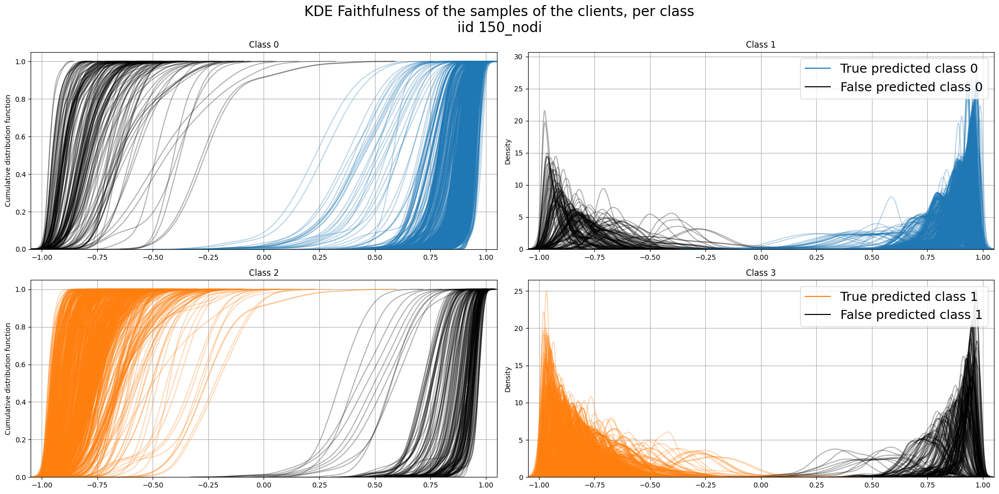

<Figure size 640x480 with 0 Axes>

In [174]:

indexes_per_calss_list.keys()#len(indexes_per_calss_list[exp])
indexes_per_calss_list2 = {exp:indexes_per_calss_list["%".join(exp)] for exp in focus}
for exp in focus:
    plt.clf()
    # plot the distributions of the faithfulness of every sample
    fig,ax = plt.subplots(len(indexes_per_calss_list2[exp]),2,figsize=(20,5*len(indexes_per_calss_list2[exp])))
    ax = ax.flatten()
    pred = activations_of_models[exp][100]
    for i,idxs in enumerate(indexes_per_calss_list2[exp]):
        color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
        ax[2*i+1].plot([0,0],[0,0],color=color,label="True predicted class "+str(i))
        ax[2*i+1].plot([0,0],[0,0],color='k',label="False predicted class "+str(i))
        for idx in idxs:
            # check if it it a true positive or a false positive
            if pred[idx].argmax() != i:
                color = 'k'
            else:
                color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i],cumulative=True)
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i+1],cumulative=False)
        # add a fake line for the legend
        


    old_y_lim = plt.ylim()
    # add fake lines for the legend

    plt.suptitle("KDE Faithfulness of the samples of the clients, per class\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    for j,axe in enumerate(ax.flatten()):
        axe.set_xlim(-1.05,1.05)
        axe.grid(True)
        axe.set_title("Class "+str(j))
        if j%2==1:
            axe.legend(fontsize=18, loc='upper right')
            axe.set_ylabel("Density")
        else:
            axe.set_ylabel("Cumulative distribution function")


    plt.ylim(old_y_lim)
    plt.savefig(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
    plt.tight_layout()
    plt.show()
    plt.close()
    plt.clf()

    break


In [ ]:
#QUAQUAQUA

(1000,
 ('iid', '50_nodi'))

In [122]:
all_shap_dict[("099","150_nodi")].keys(),exp

(dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta']),
 ('iid', '50_nodi'))

In [123]:
all_shap_dict[exp]["Clients"].shape

(30, 2000, 12)

In [124]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)



In [125]:

focus, b_v

([('iid', '50_nodi'),
  ('iid', '70_nodi'),
  ('iid', '150_nodi'),
  ('5', '50_nodi'),
  ('5', '70_nodi'),
  ('5', '150_nodi'),
  ('099', '50_nodi'),
  ('099', '70_nodi'),
  ('099', '150_nodi')],
 1000)

dict_keys(['Server', 'Clients']) (2,)


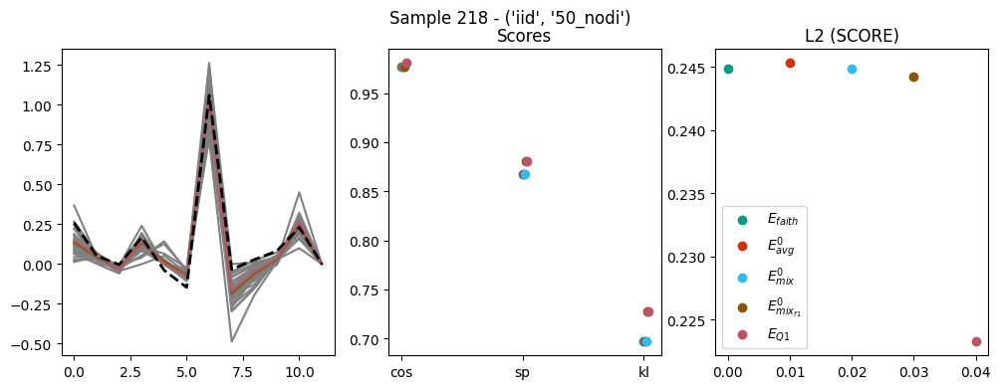

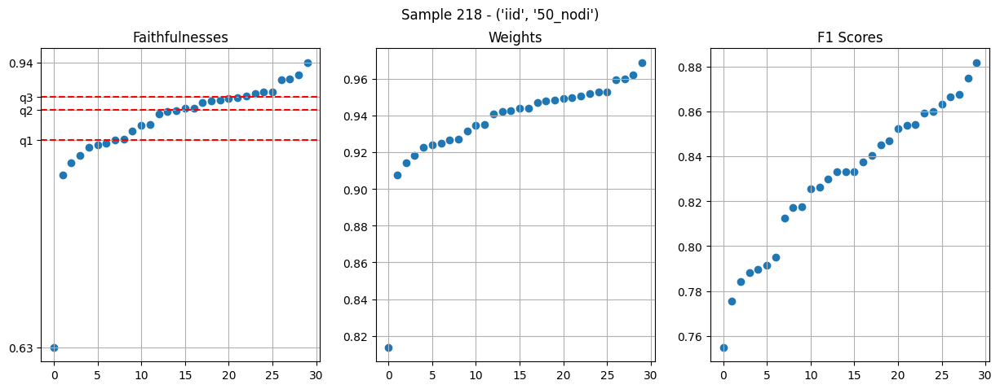

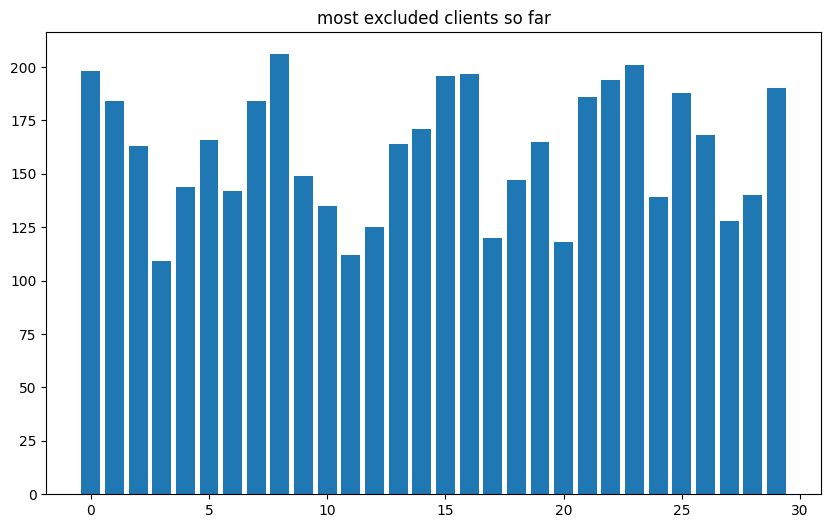

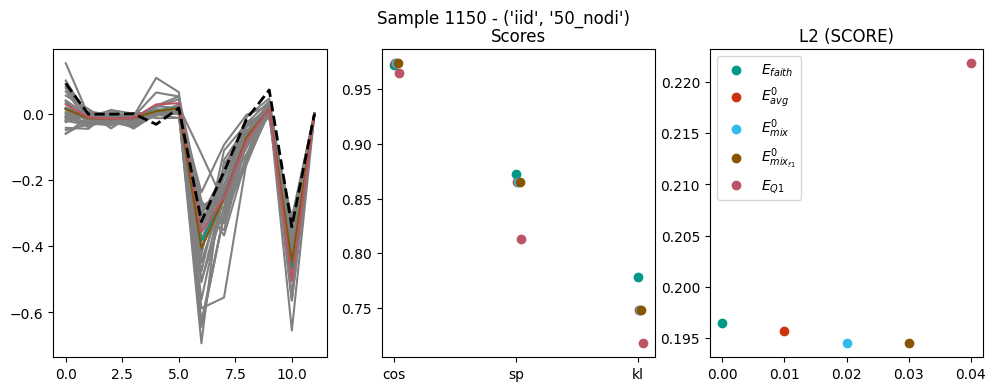

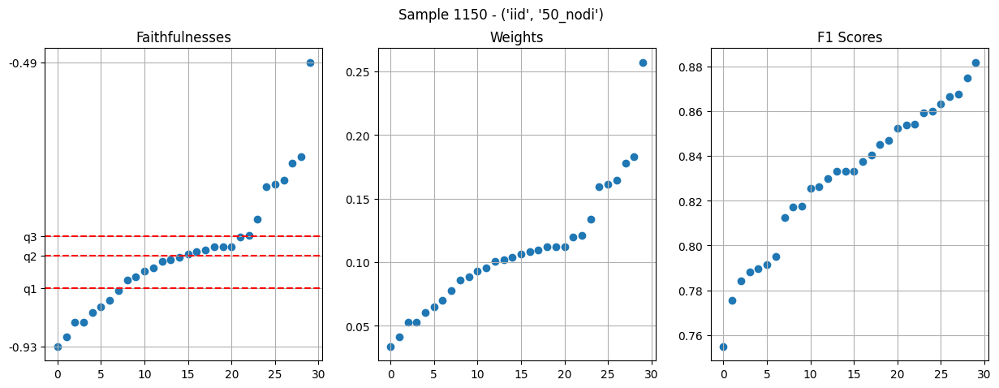

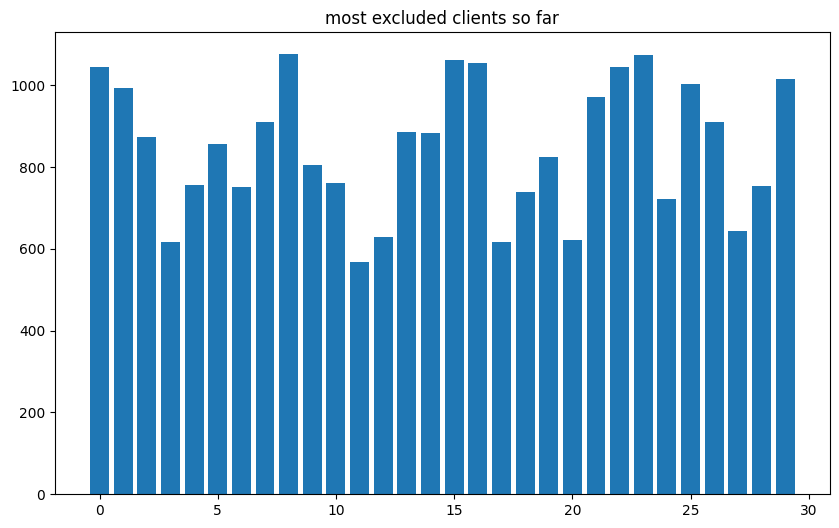

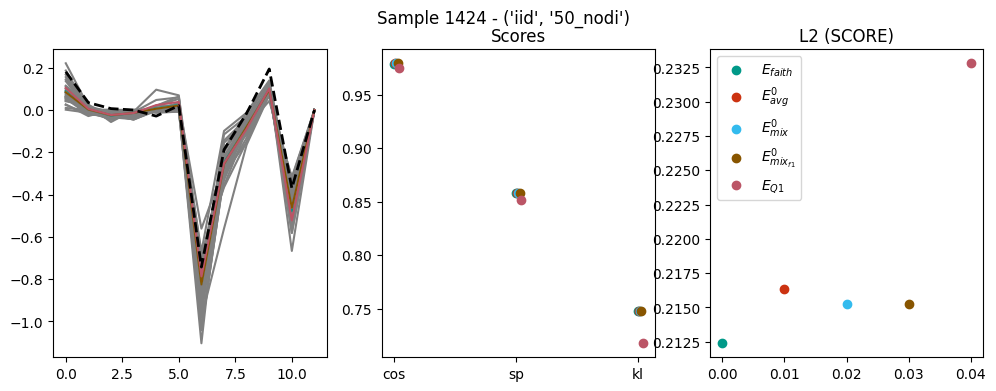

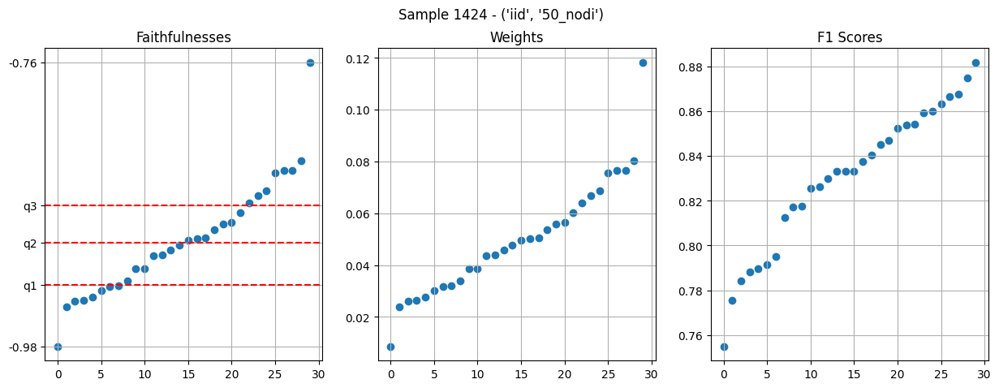

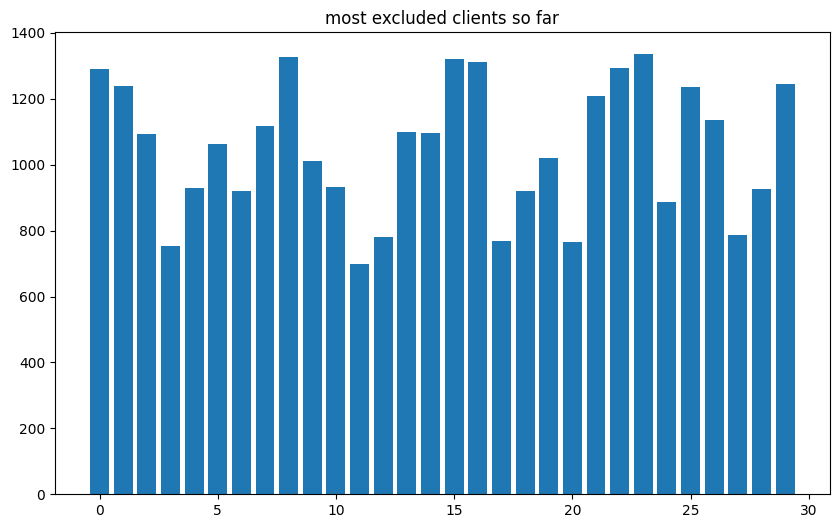

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1975 over 2000 (98.75%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [988] times
most excluded clients indexes: [[11  3 20 17 27 12 24  6 28 10 18  4  9 19  5 13 14  2  7 26 21 25  1 29
  22  0 16 15  8 23]]
[array([1812., 1742., 1541., 1045., 1310., 1498., 1272., 1561., 1861.,
       1425., 1300.,  986., 1104., 1526., 1531., 1849., 1828., 1081.,
       1304., 1440., 1052., 1703., 1808., 1866., 1261., 1738., 1594.,
       1094., 1284., 1744.])]
dict_keys(['Server', 'Clients']) (2,)


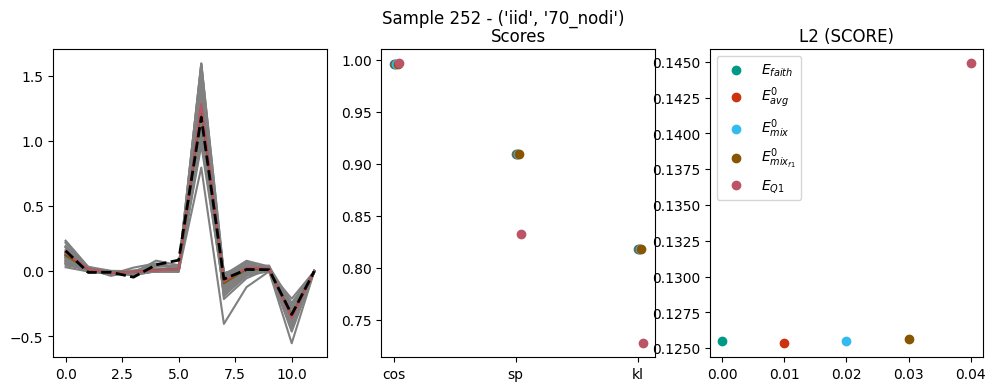

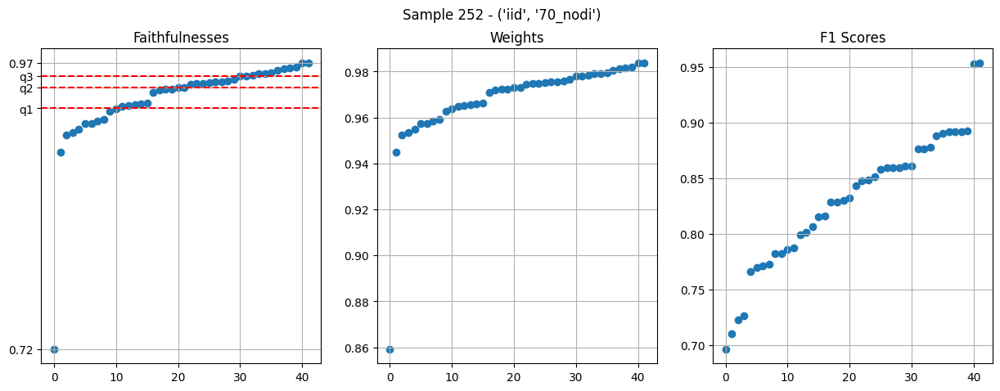

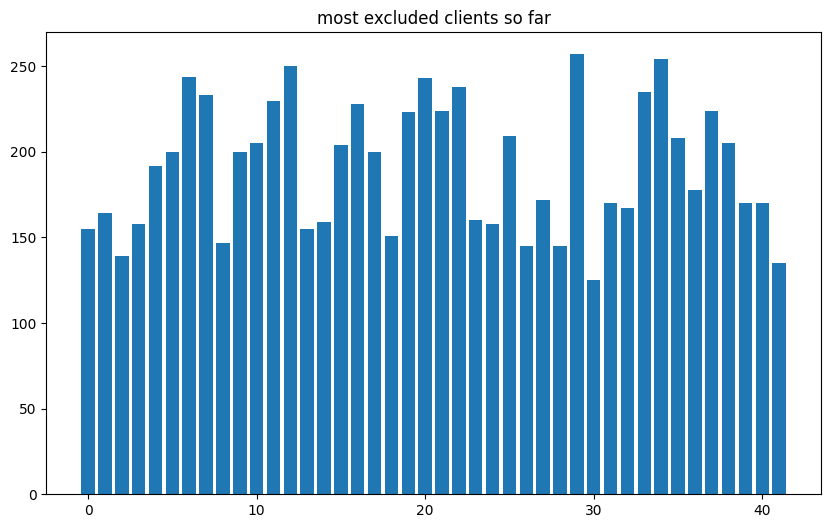

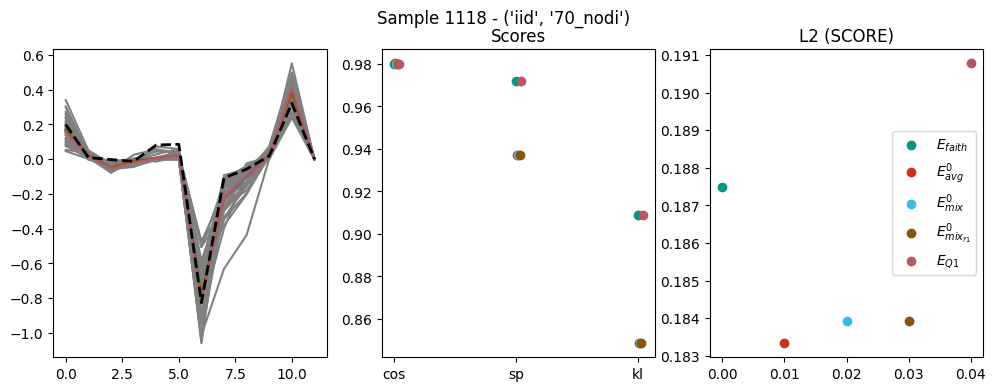

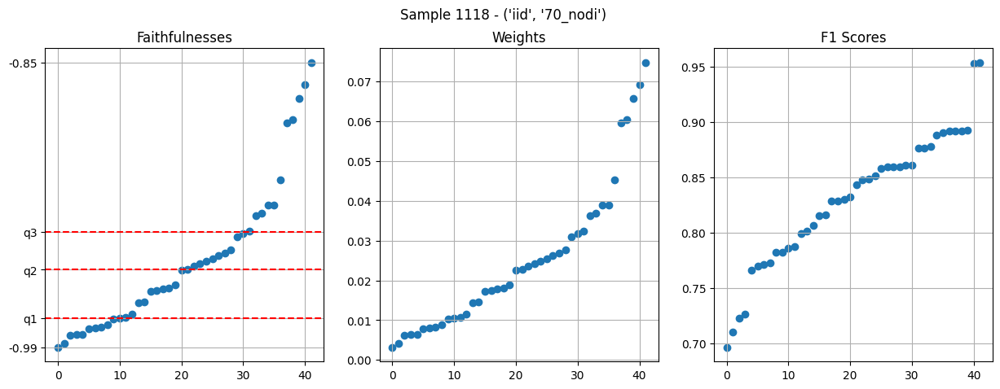

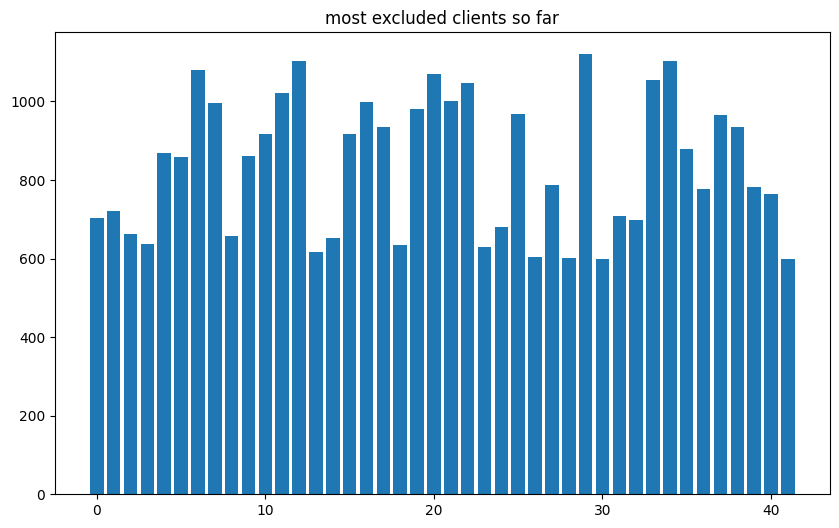

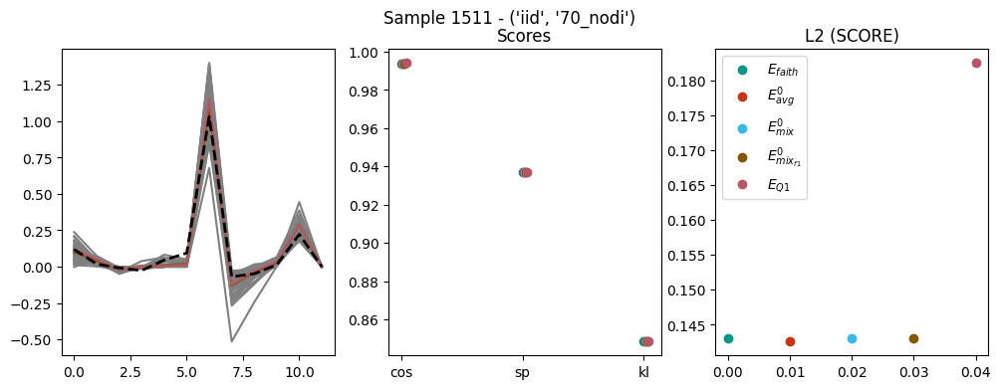

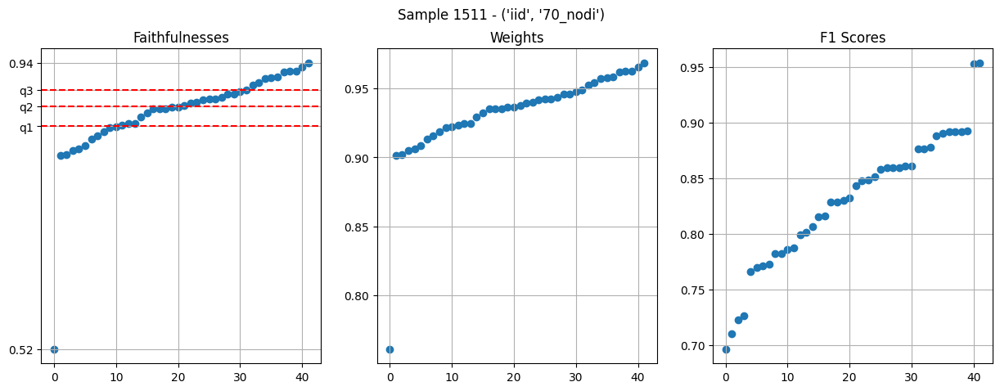

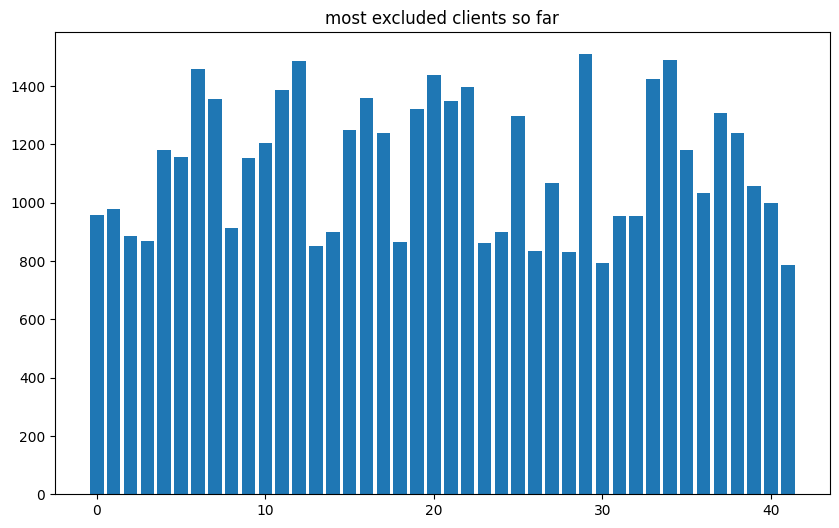

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1945 over 2000 (97.25%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1001] times
most excluded clients indexes: [[30 41 28 26 13 18  3 23 24  2 14  8 32  0 31  1 40 36 39 27  9  5 35  4
  10 17 38 15 25 37 19  7 21 16 11 22 33 20  6 12 34 29]]
[array([1260., 1293., 1177., 1146., 1569., 1525., 1930., 1776., 1217.,
       1504., 1592., 1818., 1965., 1115., 1190., 1661., 1798., 1637.,
       1145., 1735., 1902., 1787., 1842., 1147., 1176., 1712., 1097.,
       1423., 1094., 1993., 1043., 1265., 1260., 1878., 1968., 1543.,
       1364., 1719., 1646., 1389., 1331., 1063.])]
dict_keys(['Server', 'Clients']) (2,)


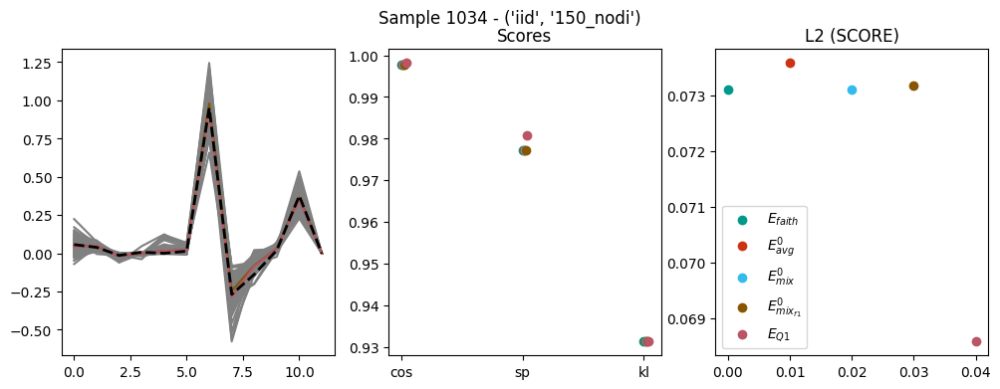

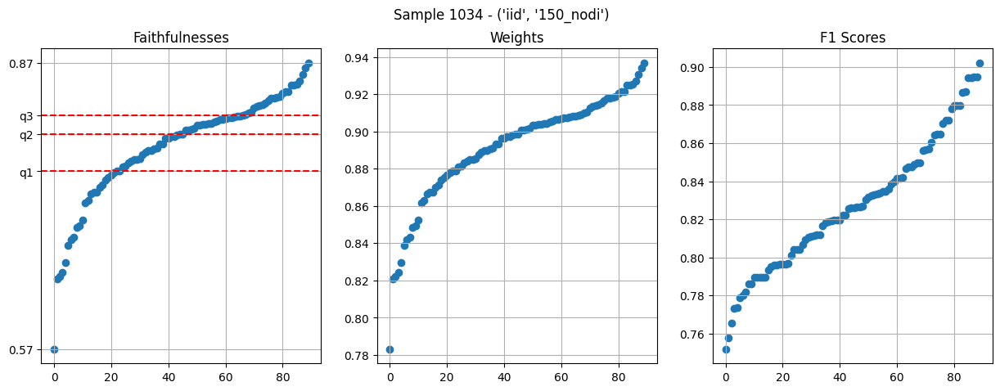

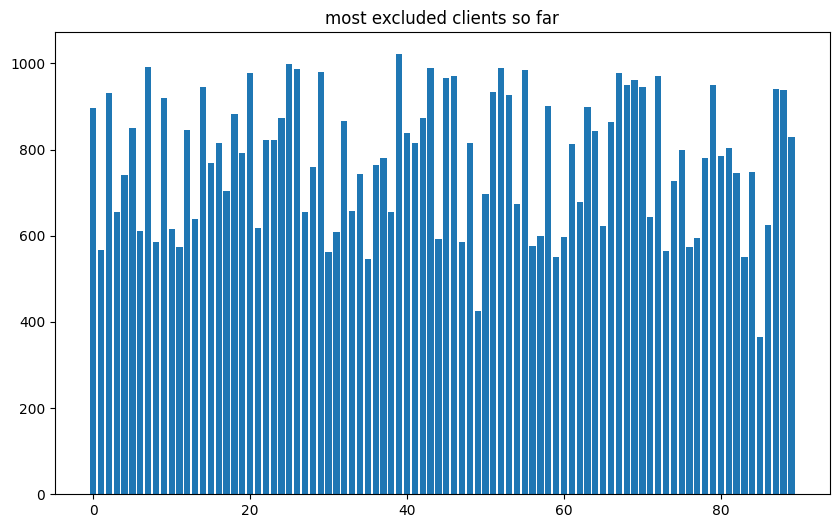

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1972 over 2000 (98.6%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1017] times
most excluded clients indexes: [[85 49 35 83 73 11 59  1 76 47 30 56 57  6 44  8 77 60 21 10 86 31 27 65
  13 71 33 38 62 54  3 17 50 74 82  4 34 28 37 15 84 80 78 36 48 19 75 61
  81 22 12 40  5 16 89 23 41 66 64 24 42 32 18 58 63  0  9 53 70  2 51 87
  14 88 68 69 79 46 20 72 29 67 45 55 43 26  7 52 25 39]]
[array([1754., 1100., 1803., 1303., 1433., 1595., 1134., 1917., 1149.,
       1774., 1192., 1079., 1583., 1228., 1837., 1476., 1600., 1311.,
       1719., 1557., 1870., 1188., 1573., 1607., 1671., 1927., 1915.,
       1216., 1461., 1881., 1113., 1209., 1685., 1265., 1457., 1036.,
       1516., 1474., 12

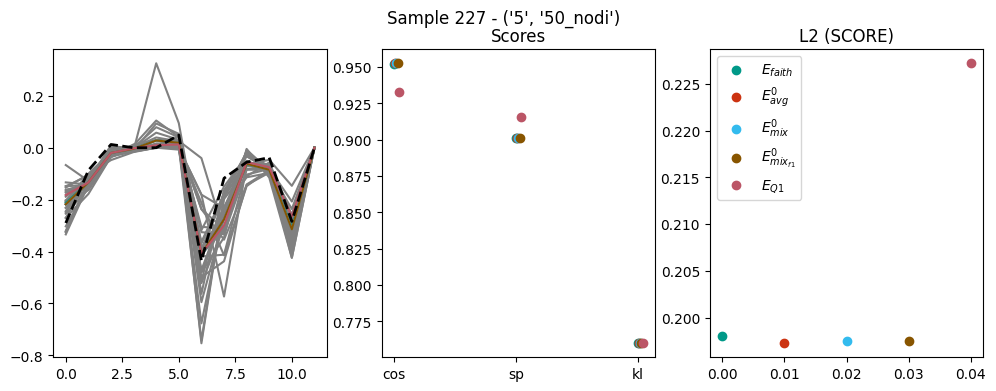

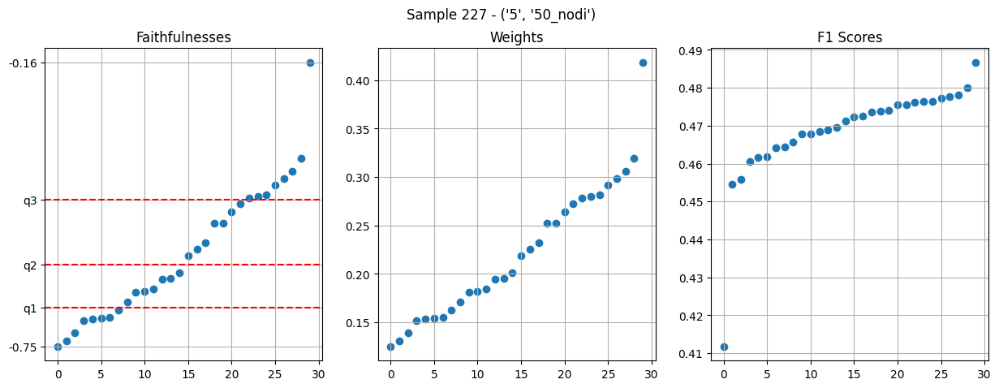

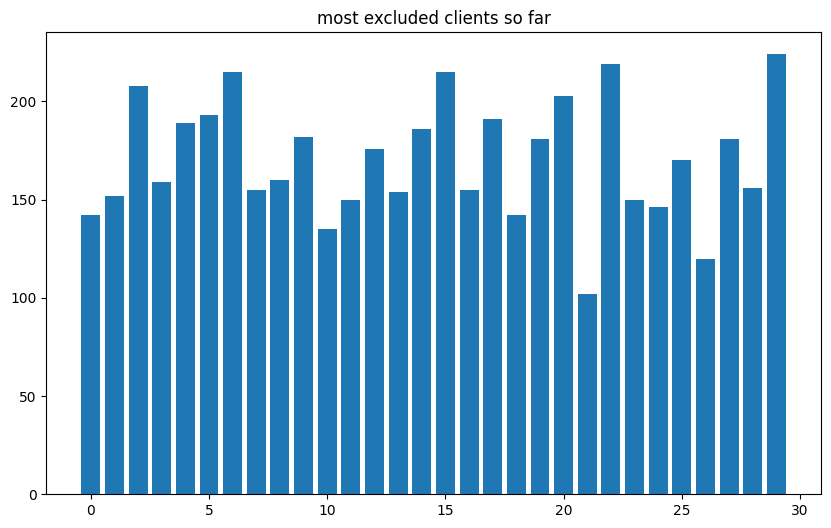

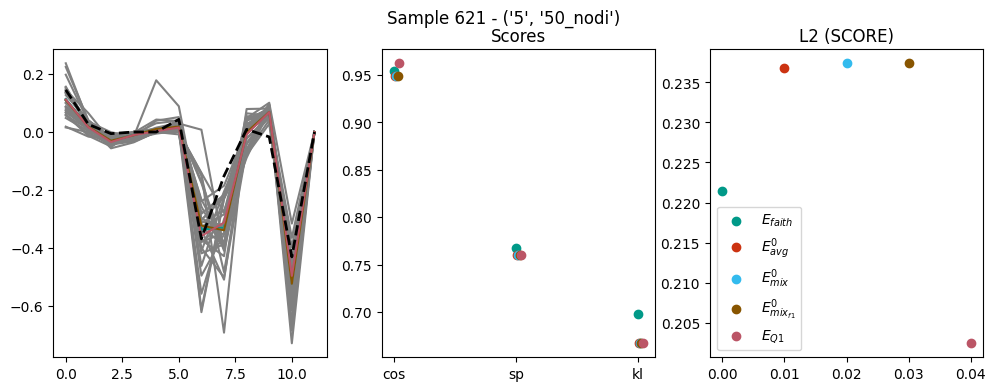

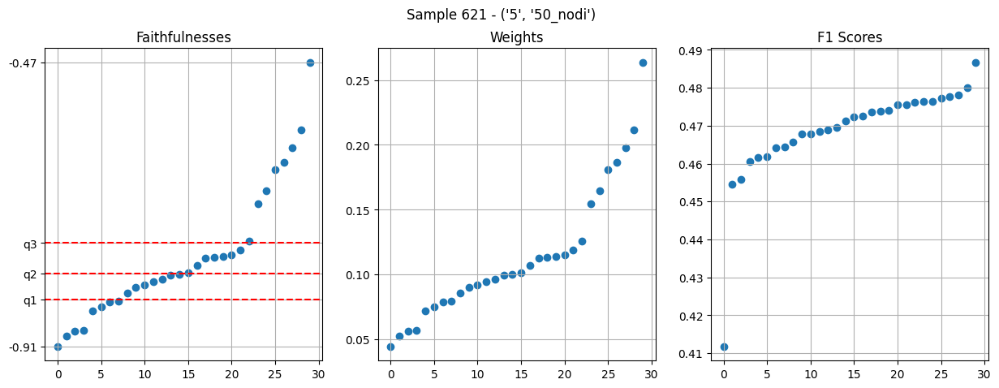

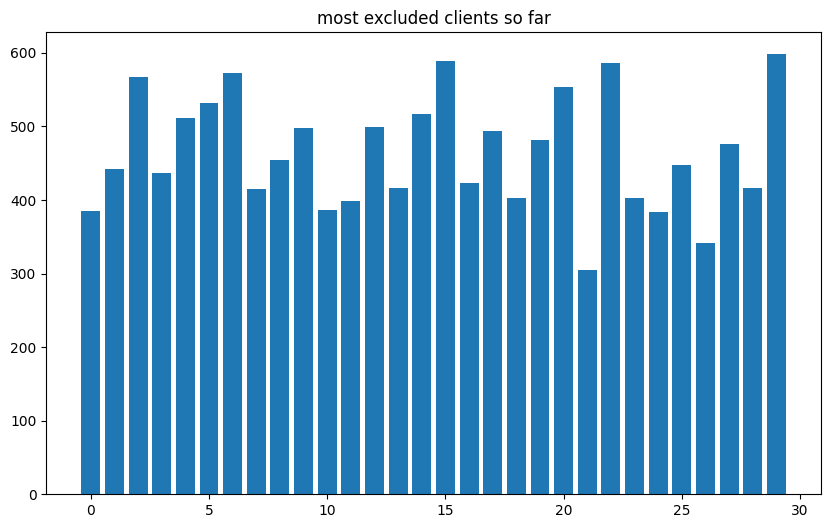

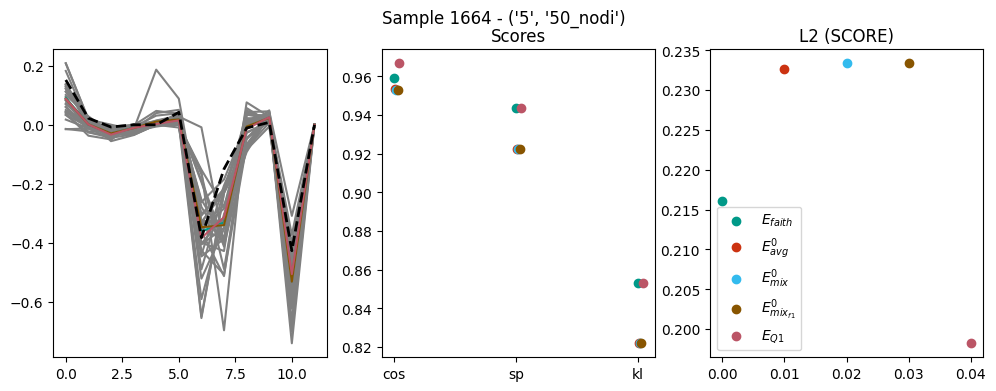

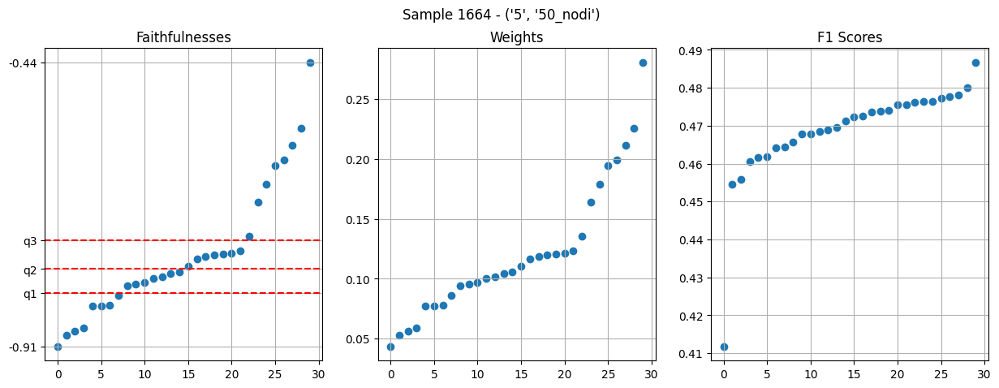

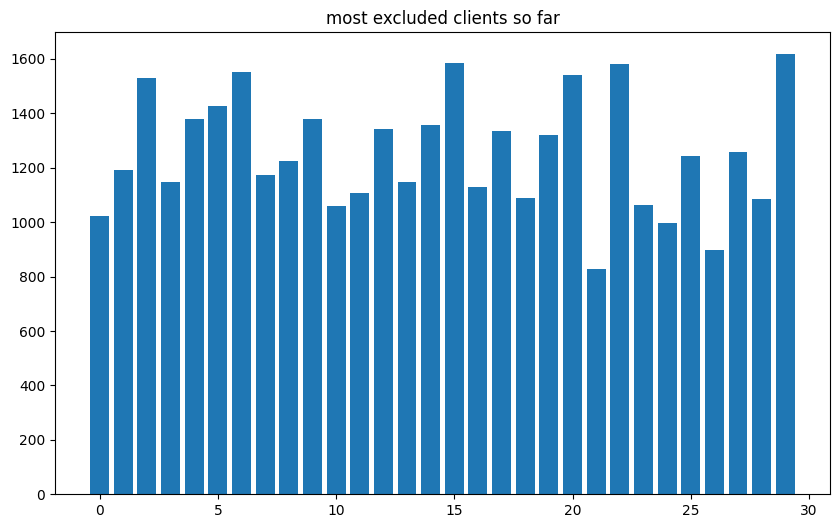

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1952 over 2000 (97.6%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [917] times
most excluded clients indexes: [[21 26 24  0 10 23 28 18 11 16  3 13  7  1  8 27 25 19 17 12 14  9  4  5
   2 20  6 22 15 29]]
[array([1231., 1429., 1837., 1379., 1662., 1699., 1858., 1419., 1473.,
       1649., 1270., 1337., 1620., 1388., 1622., 1903., 1371., 1606.,
       1310., 1581., 1852.,  995., 1885., 1281., 1199., 1503., 1069.,
       1501., 1297., 1933.])]
dict_keys(['Server', 'Clients']) (2,)


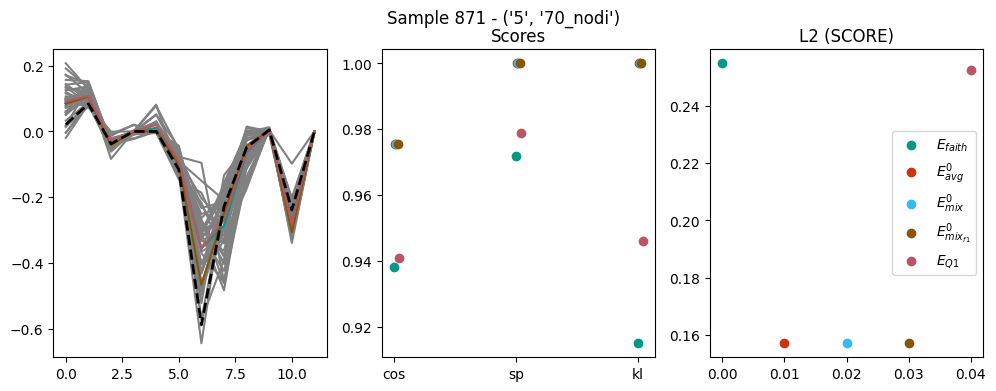

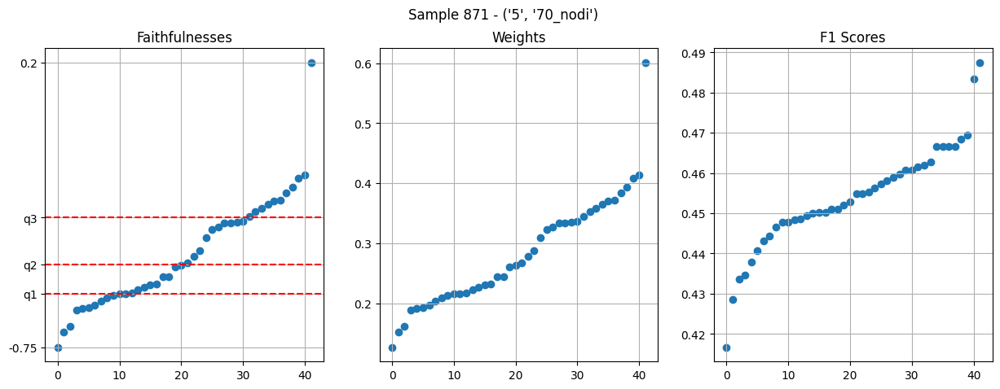

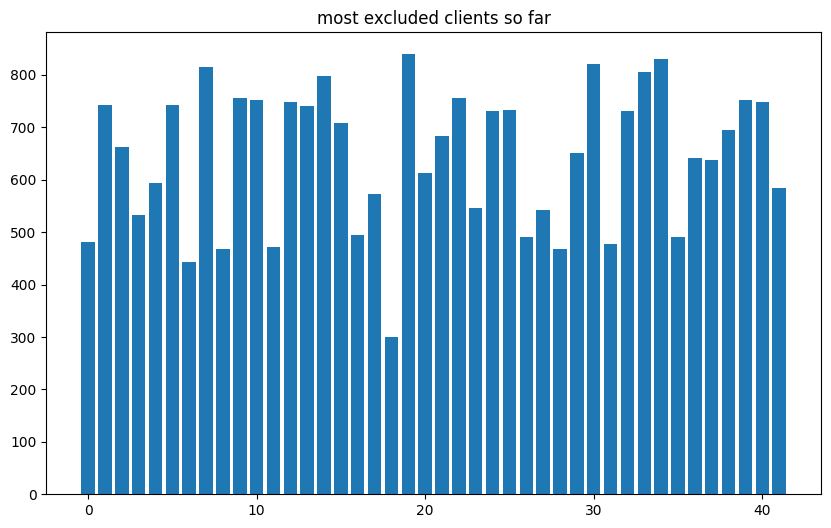

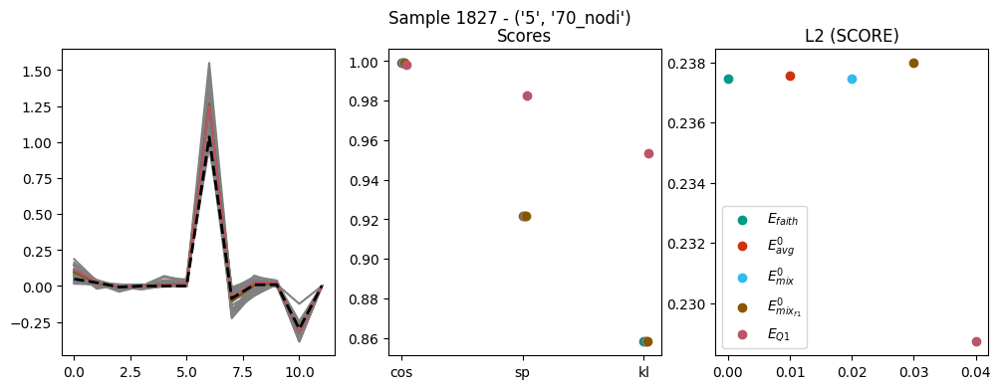

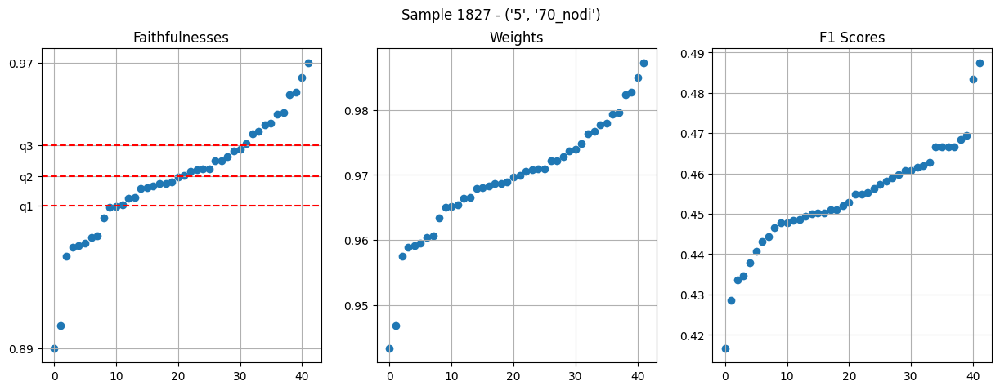

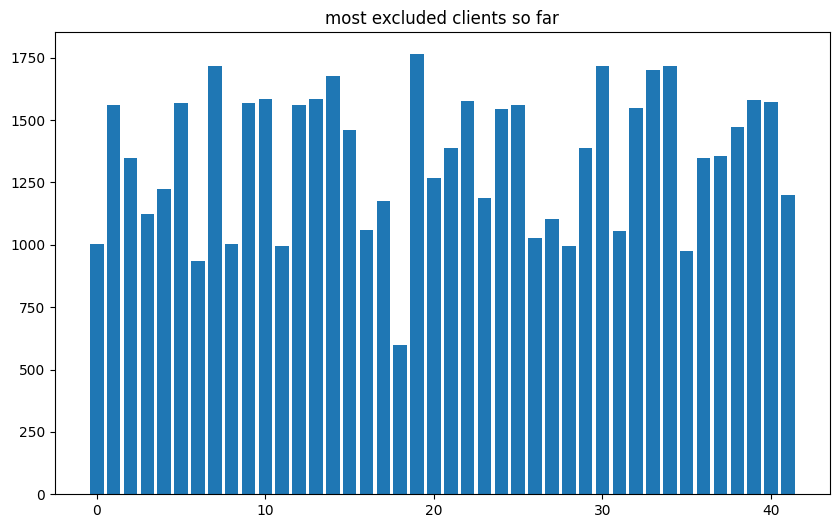

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1991 over 2000 (99.55%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1012] times
most excluded clients indexes: [[18  6 35  8 11 28  0 26 31 16 27  3 17 23 41  4 20  2 36 37 29 21 15 38
  32 24  1 25  5 40 12 22  9 10 13 39 14 33 30  7 34 19]]
[array([1102., 1702., 1473., 1222., 1342., 1711., 1024., 1880., 1085.,
       1721., 1729., 1087., 1713., 1732., 1833., 1600., 1157., 1293.,
        659., 1929., 1387., 1525., 1717., 1299., 1690., 1704., 1124.,
       1211., 1090., 1513., 1879., 1155., 1689., 1863., 1881., 1074.,
       1478., 1497., 1608., 1732., 1711., 1314.])]
dict_keys(['Server', 'Clients']) (2,)


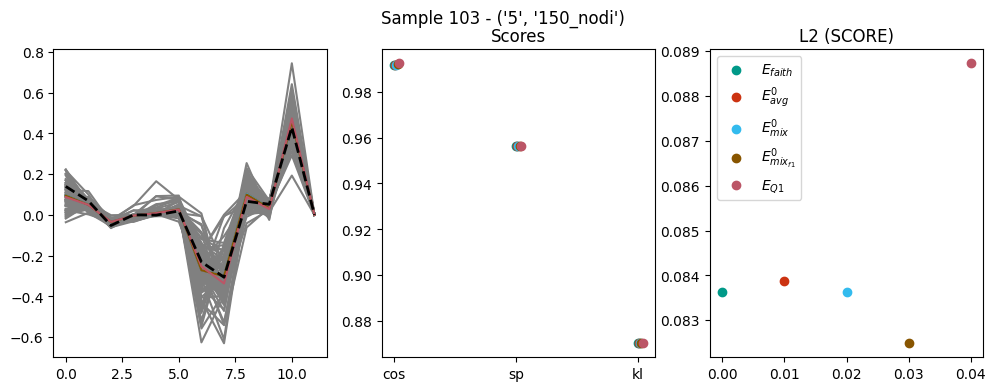

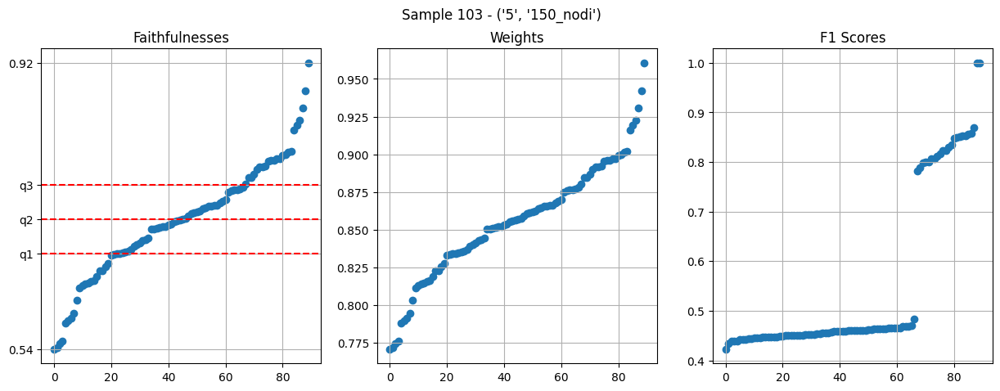

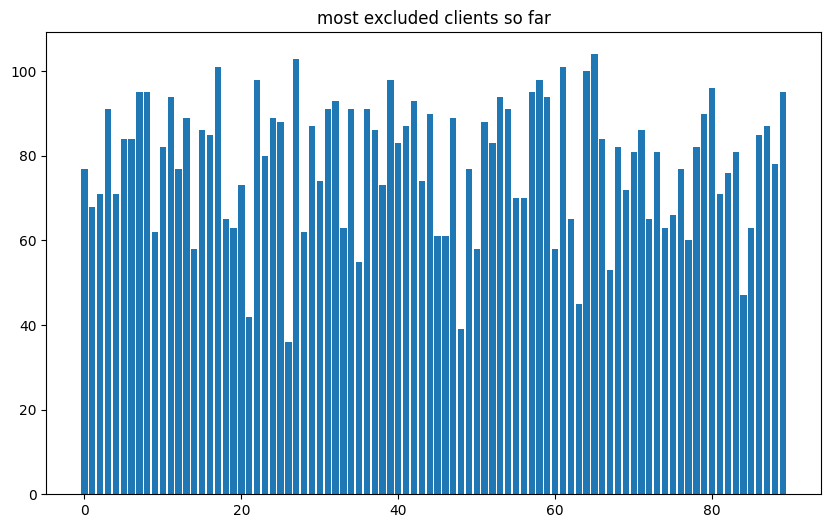

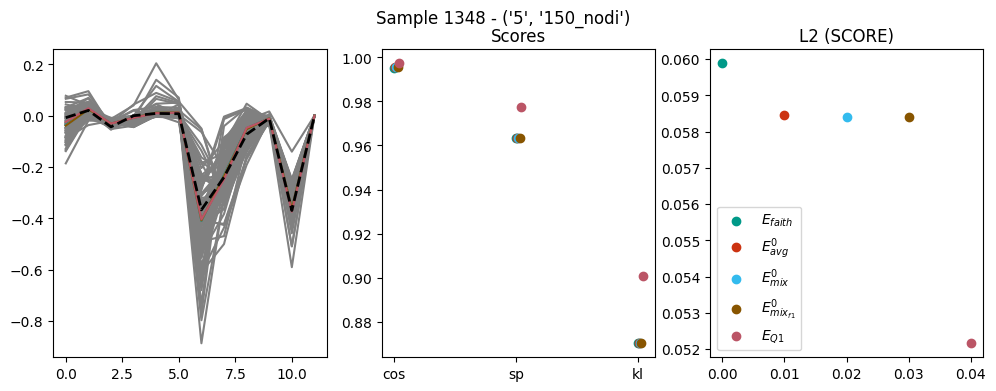

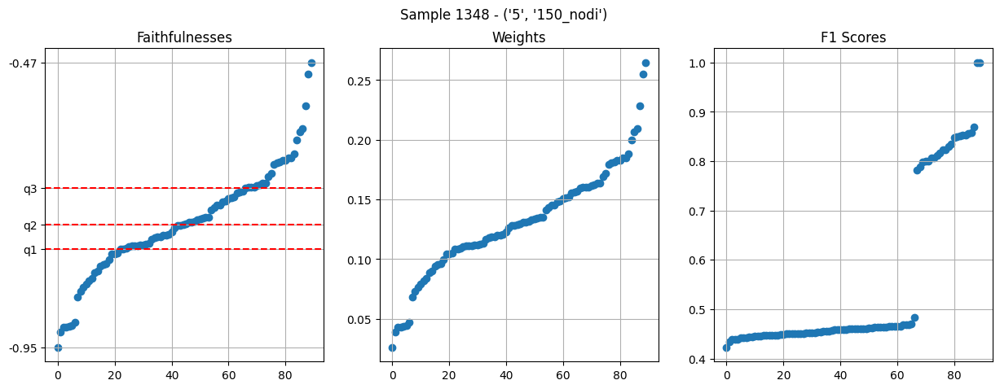

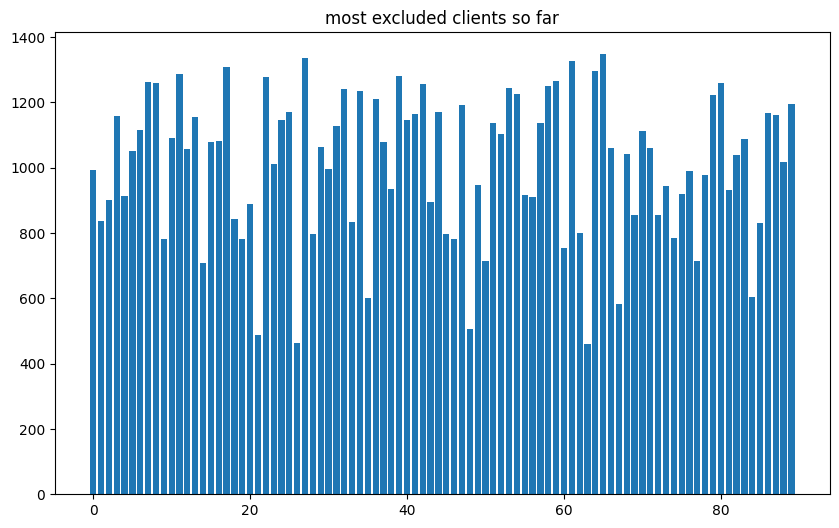

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1965 over 2000 (98.25%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1016] times
most excluded clients indexes: [[63 21 26 48 67 35 84 14 50 77 60 74 45 46 19  9 28 62  1 85 72 18 69 33
   2 20 43 56 75  4 38 73 55 81 49 78 76 30 23  0 88 82 68 66  5 29 12 71
  15 16 37 83 10 52 70 31  6 57 24 51 40  3 13 86 87 41 44 25 47 89 36 79
  54 32 34 58 53 42  8  7 80 59 22 39 11 64 17 61 27 65]]
[array([1486., 1215., 1314., 1706., 1372., 1558., 1658., 1866., 1866.,
       1180., 1624., 1909., 1568., 1711., 1059., 1581., 1590., 1934.,
       1251., 1179., 1318.,  716., 1888., 1473., 1677., 1739.,  731.,
       1981., 1199., 1563., 1465., 1656., 1825., 1264., 1831.,  888.,
       1791., 1599., 1

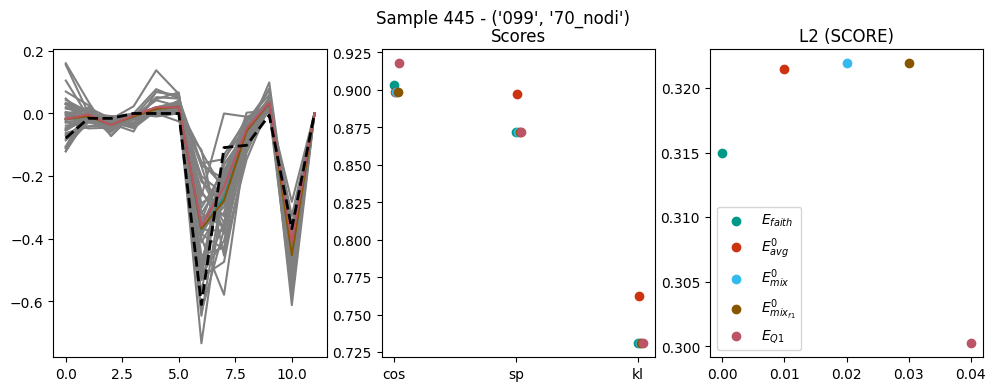

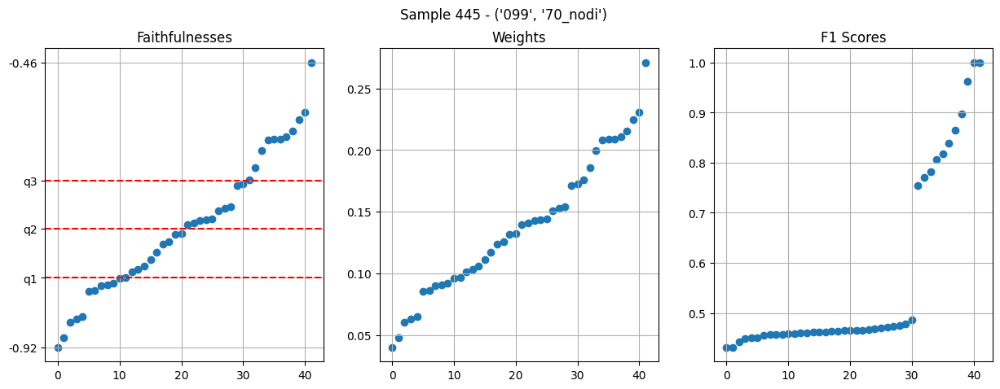

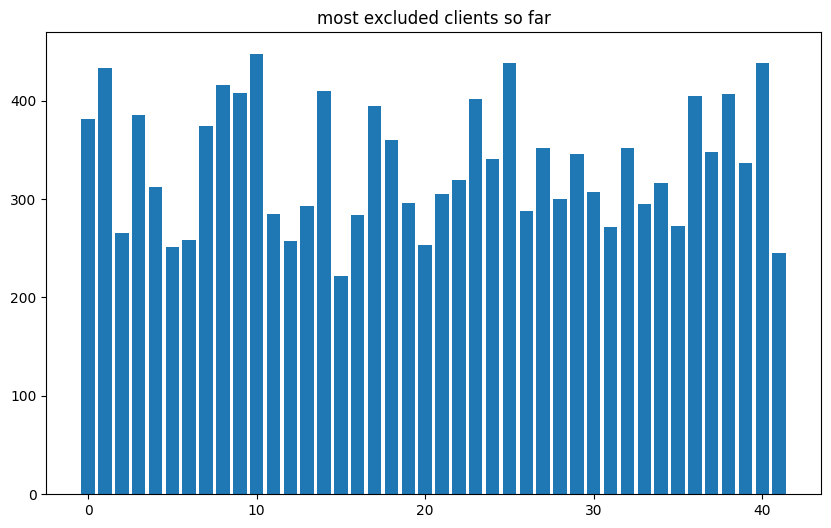

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1964 over 2000 (98.2%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [964] times
most excluded clients indexes: [[15  5 41 12 20  6 35 31 16  2 13 11 26 19 30 33 28  4 21 34 22 24 27 39
  18 32 29 37  7  0  3  9 17 36 23 14 38  8 25 40  1 10]]
[array([1735., 1965., 1252., 1757., 1361., 1022., 1144., 1711., 1881.,
       1796., 2000., 1272., 1112., 1260., 1844., 1003., 1238., 1799.,
       1566., 1284., 1112., 1395., 1448., 1820., 1475., 1951., 1273.,
       1528., 1344., 1576., 1298., 1205., 1570., 1319., 1425., 1197.,
       1805., 1609., 1844., 1544., 1953., 1096.])]
dict_keys(['Server', 'Clients']) (2,)


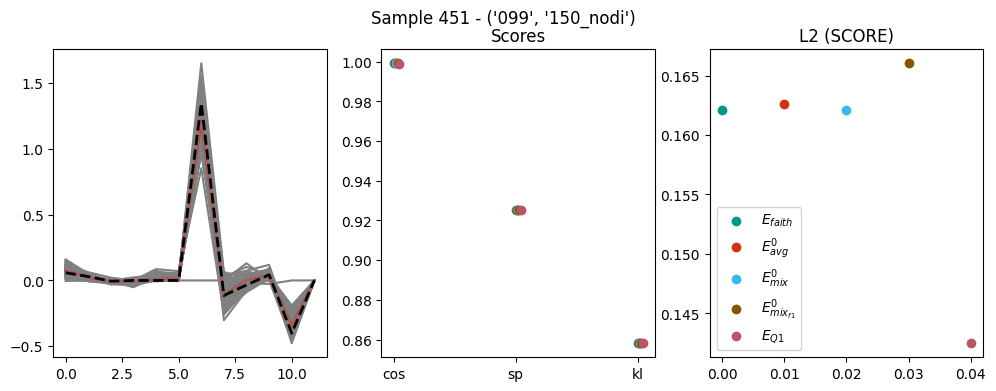

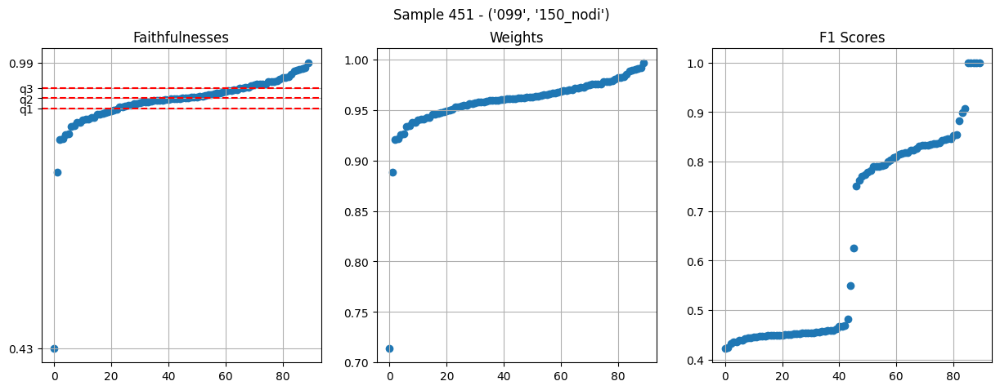

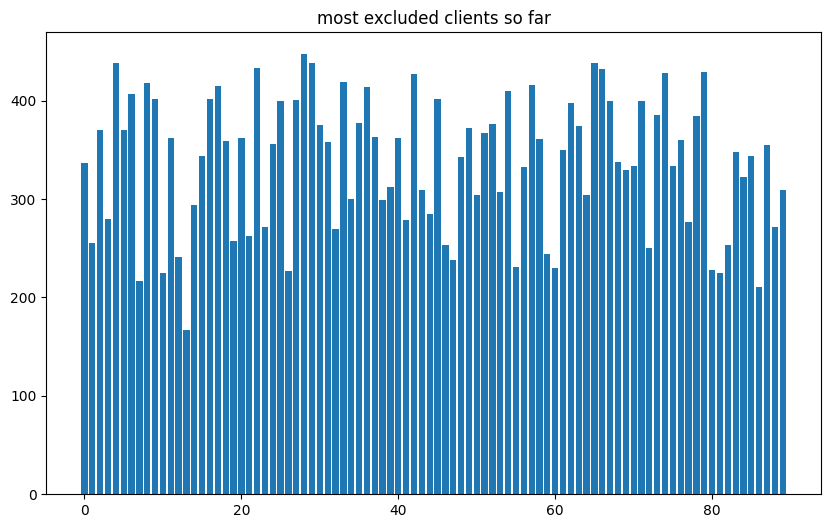

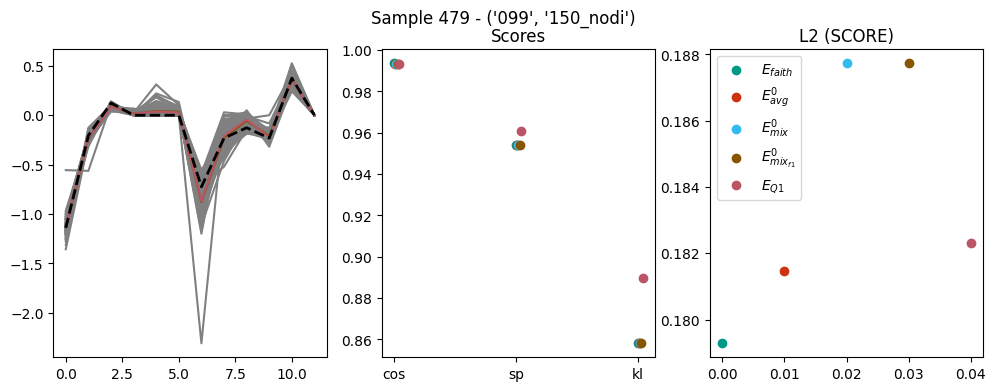

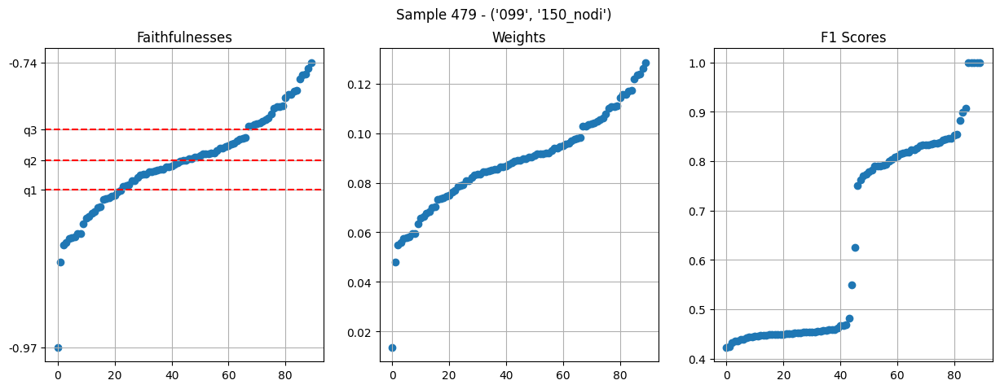

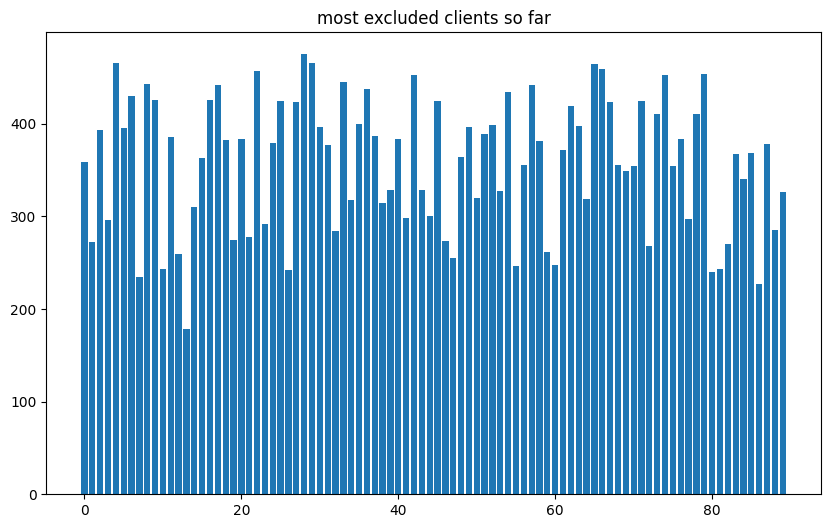

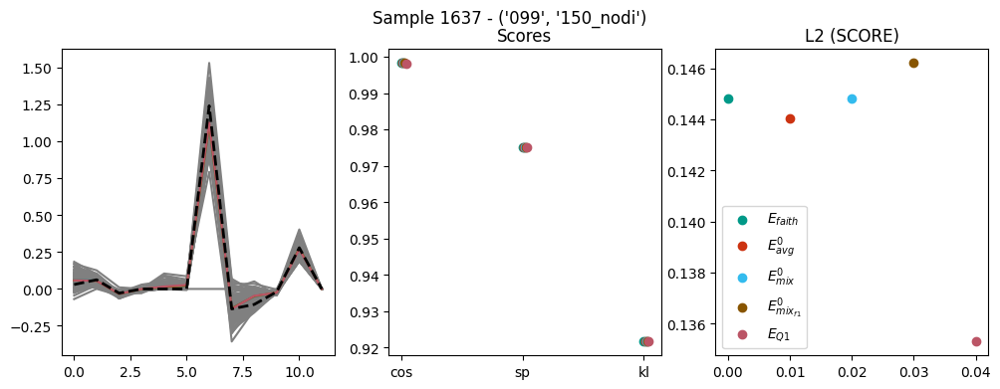

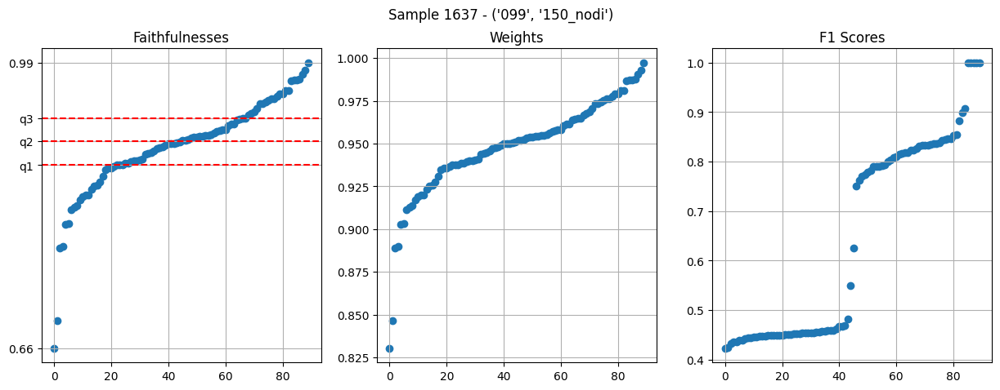

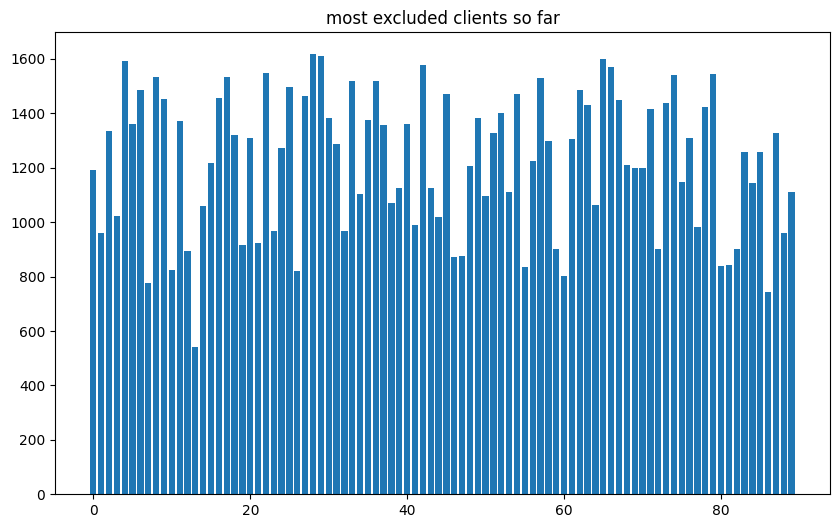

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1976 over 2000 (98.8%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1012] times
most excluded clients indexes: [[13 86  7 60 10 26 81 55 80 46 47 59 82 12 72 19 21 88 32 23  1 41 77 44
   3 64 14 38 50 34 89 53 43 39 84 75  0 70 69 68 48 15 56 83 85 24 31 58
  20 61 76 51 87 18  2 37 40  5 35 11 30 49 52 71 78 63 73 16 67  9 27 54
  45 62  6 25 36 33 57 17  8 79 74 22 66 42  4 65 29 28]]
[array([1455., 1195., 1631., 1251., 1940., 1664., 1818.,  948., 1875.,
       1770., 1008., 1673., 1109.,  671., 1302., 1480., 1764., 1872.,
       1618., 1117., 1587., 1129., 1882., 1189., 1557., 1827., 1009.,
       1781., 1972., 1964., 1675., 1568., 1182., 1859., 1343., 1668.,
       1851., 1646., 13

In [126]:
for exp in focus:
    print(all_faith_dict[exp][b_v].keys(),indexes_per_calss[exp].shape)
    policy_selection(exp = exp,
    faithfulnesses=all_faith_dict[exp][b_v],
    all_shap_values_dict=all_shap_dict,
    class_idxs = indexes_per_calss[exp],
    dt_name = "dutch",
    f1_scores=np.array(all_weights_dict_MACRO[exp]),
    show=True)#(False if exp!=focus[0] else True))

In [127]:
for k in all_shap_dict[exp].keys():
    print(k,all_shap_dict[exp][k].shape)

Server (2000, 12)
Clients (90, 2000, 12)
E_hat (2000, 12)
E_weighted (2000, 12)
E_f1_macro (2000, 12)
Delta (2000, 12)
E_fait_weighted (2000, 12)
E_avg_t_0 (2000, 12)
E_mixed (2000, 12)
E_mix_f1 (2000, 12)
E_Q1 (2000, 12)


In [128]:
props = [
        "E_hat",
        "E_weighted", # the explanation is the average of the explanations weighted by the f1 score
        "E_f1_macro", # the explanation is the average of the explanations weighted by the f1 score MACRO


        "E_fait_weighted", # the explanation is the average of the explanations weighted by the faithfulness
        "E_avg_t_0",       # the explanation is the average of the explanations filtered on the faithfulness > 0
                           # if there are not explanations that have 
        "E_mixed",         # 
        "E_mix_f1",
        "E_Q1",
        
        #"E_avg_t_06",
        #"E_france_W",
        #"E_harm",
        ]

In [129]:
exp = focus[0]
for exp in focus:
    test_s = load_npz(os.path.sep.join([".",all_shap_folders[exp].replace("shap","samples"),
                                        "explain_samples_dutch_"+exp[1]+"_"+exp[0]+".npz"]))
    exp_dt = TensorDataset(torch.Tensor(test_s["X"]),
                        torch.Tensor(np.eye(2)[test_s["y"]]))
    plot_faith_dry(exp=exp,
                faits = all_faith_dict[exp][b_v],
                all_shap_values_dict=all_shap_dict,
                te_set=exp_dt,
                activations=activations_of_models[exp][100],
                show_samples=1800,
                chosen_idxs=indexes_per_calss[exp],
                dt_name=dt_name,
                feat_names=feat_names,
                top_k=["E_Q1","E_f1_macro"],
                show=False,
                vmax=0.45,
                vmax_diff = 0.1
    )

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '50_nodi') (1, 2000) faits["server"] shape
(2000, 31)
900 samples per class
1 patches
0
[724, 900]
1 patches
900
[724, 900, 1683, 1800]
<class 'numpy.ndarray'> type of faiths (997, 31) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 31) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[315, 231, 1589, 130, 734, 963, 1574, 1726, 933, 693]
[0.07212521 0.0444149  0.0642918  0.02128813 0.06535497 0.03805739
 0.05312172 0.16131081 0.05322146 0.02888163 0.10374051 0.        ]
EXPLAINED SHAPE (1800, 12)
[315, 231, 1589, 130, 734, 963, 1574, 1726, 933, 693]
[0.0677816  0.04567246 0.06435316 0.02166369 0.06508564 0.03705528
 0.05551964 0.16242155 0.05323618 0.03000488 0.07521842 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.40222222 0.5        0.935      1.        ] TP/FP
[0.         0.0333333

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '70_nodi') (1, 2000) faits["server"] shape
(2000, 43)
900 samples per class
1 patches
0
[739, 900]
1 patches
900
[739, 900, 1655, 1800]
<class 'numpy.ndarray'> type of faiths (997, 43) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 43) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[1632, 1423, 1412, 1660, 503, 821, 897, 896, 686, 1341]
[0.06329913 0.02961625 0.05054011 0.05600102 0.07538659 0.03621867
 0.07790114 0.10472266 0.04749347 0.03688204 0.04981599 0.        ]
EXPLAINED SHAPE (1800, 12)
[1632, 1423, 1412, 1660, 503, 821, 897, 896, 686, 1341]
[0.06338942 0.02821733 0.05048829 0.05564618 0.07705174 0.0361365
 0.06271083 0.09749968 0.03990611 0.03514029 0.04381928 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.41055556 0.5        0.91944444 1.        ] TP/FP
[0.         0.0238

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '150_nodi') (1, 2000) faits["server"] shape
(2000, 91)
900 samples per class
1 patches
0
[741, 900]
1 patches
900
[741, 900, 1669, 1800]
<class 'numpy.ndarray'> type of faiths (997, 91) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 91) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 734, 963, 1726, 1574, 130, 1517]
[0.01965585 0.00575223 0.00321408 0.00322744 0.01093089 0.00545641
 0.02629304 0.01939776 0.01825136 0.00745141 0.01439244 0.        ]
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 734, 963, 1726, 1574, 130, 1517]
[0.01858835 0.00439157 0.00307337 0.00261091 0.0110267  0.00494673
 0.00883408 0.01154439 0.01783095 0.00745647 0.01027395 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.41166667 0.5        0.92722222 1.        ] TP/FP
[0.         0.0111

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '50_nodi') (1, 2000) faits["server"] shape
(2000, 31)
900 samples per class
1 patches
0
[666, 900]
1 patches
900
[666, 900, 1749, 1800]
<class 'numpy.ndarray'> type of faiths (997, 31) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 31) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[693, 231, 963, 734, 315, 1589, 1574, 1726, 1517, 130]
[0.0633723  0.05291235 0.03753365 0.0166335  0.03236922 0.05651229
 0.09129545 0.09383021 0.09523376 0.06291001 0.09582509 0.        ]
EXPLAINED SHAPE (1800, 12)
[693, 231, 963, 734, 315, 1589, 1574, 1726, 1517, 130]
[0.05974458 0.05230265 0.03763889 0.01691243 0.02924774 0.05575546
 0.07724356 0.10048503 0.09466997 0.06379448 0.09626634 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.37       0.5        0.97166667 1.        ] TP/FP
[0.         0.0333333

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '70_nodi') (1, 2000) faits["server"] shape
(2000, 43)
900 samples per class
1 patches
0
[739, 900]
1 patches
900
[739, 900, 1679, 1800]
<class 'numpy.ndarray'> type of faiths (997, 43) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 43) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1574, 1726, 130, 1517]
[0.02571554 0.01099055 0.00590378 0.00472569 0.01228375 0.01641356
 0.03454928 0.04492848 0.02873095 0.00752936 0.01531395 0.        ]
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1574, 1726, 130, 1517]
[0.02127663 0.01040087 0.00426868 0.00468443 0.01259052 0.01669693
 0.03239725 0.03724616 0.02571169 0.00676855 0.00497392 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.41055556 0.5        0.93277778 1.        ] TP/FP
[0.         0.0238095

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '150_nodi') (1, 2000) faits["server"] shape
(2000, 91)
900 samples per class
1 patches
0
[742, 900]
1 patches
900
[742, 900, 1654, 1800]
<class 'numpy.ndarray'> type of faiths (997, 91) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 91) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1726, 1574, 130, 1517]
[0.01935809 0.01156661 0.00368529 0.00863455 0.01188169 0.00467165
 0.02216429 0.02355416 0.0135767  0.00683202 0.01572518 0.        ]
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1726, 1574, 130, 1517]
[0.01621092 0.01184574 0.00315884 0.00869481 0.00982815 0.00314308
 0.00833567 0.01308988 0.00575327 0.00620052 0.01132966 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.41222222 0.5        0.91888889 1.        ] TP/FP
[0.         0.011111

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '50_nodi') (1, 2000) faits["server"] shape
(2000, 31)
900 samples per class
1 patches
0
[747, 900]
1 patches
900
[747, 900, 1684, 1800]
<class 'numpy.ndarray'> type of faiths (997, 31) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 31) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[1817, 1542, 319, 477, 1456, 1243, 597, 117, 425, 301]
[0.22726934 0.07800908 0.02416859 0.04553732 0.063292   0.04912661
 0.09092696 0.14823815 0.10032968 0.05080564 0.06026472 0.        ]
EXPLAINED SHAPE (1800, 12)
[1817, 1542, 319, 477, 1456, 1243, 597, 117, 425, 301]
[0.22129787 0.07888461 0.0232813  0.04513906 0.0619591  0.04834862
 0.08138741 0.13197136 0.09927225 0.05057424 0.05796856 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.415      0.5        0.93555556 1.        ] TP/FP
[0.         0.03333

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '70_nodi') (1, 2000) faits["server"] shape
(2000, 43)
900 samples per class
1 patches
0
[709, 900]
1 patches
900
[709, 900, 1680, 1800]
<class 'numpy.ndarray'> type of faiths (997, 43) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 43) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[693, 231, 315, 963, 734, 130, 1326, 524, 765, 1923]
[0.06825533 0.03700932 0.04763989 0.0323974  0.0528642  0.02896029
 0.08156572 0.09091726 0.05504949 0.05792923 0.04909059 0.        ]
EXPLAINED SHAPE (1800, 12)
[693, 231, 315, 963, 734, 130, 1326, 524, 765, 1923]
[0.06765215 0.03838386 0.04799843 0.0311922  0.05336534 0.02965984
 0.06921381 0.08826554 0.05244047 0.05758494 0.05152418 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.39388889 0.5        0.93333333 1.        ] TP/FP
[0.         0.02380952 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '150_nodi') (1, 2000) faits["server"] shape
(2000, 91)
900 samples per class
1 patches
0
[754, 900]
1 patches
900
[754, 900, 1650, 1800]
<class 'numpy.ndarray'> type of faiths (997, 91) shape of faiths
<class 'numpy.ndarray'> type of faiths (1003, 91) shape of faiths
900 axes is Axes(0.125,0.11;0.227941x0.77)
900 axes is Axes(0.398529,0.11;0.227941x0.77)
900 axes is Axes(0.672059,0.11;0.227941x0.77)
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1726, 1574, 130, 1517]
[0.01838908 0.00617702 0.00919004 0.01569195 0.01707339 0.01284667
 0.02041853 0.01890657 0.01476564 0.00563366 0.03136017 0.        ]
EXPLAINED SHAPE (1800, 12)
[315, 231, 693, 1589, 963, 734, 1726, 1574, 130, 1517]
[0.01554716 0.00729616 0.00850475 0.0158163  0.01694575 0.01295382
 0.01827988 0.01374964 0.01247446 0.00649309 0.03459844 0.        ]
[0.  0.5 1. ] classes
[0.  0.5 1. ]
[0.25, 0.75]
['TP', 'FP', 'TP', 'FP']
[0.         0.41888889 0.5        0.91666667 1.        ] TP/FP
[0.         0.0111

<Figure size 640x480 with 0 Axes>

In [130]:
# this function is used to compute the difference between the Explanation of the server and the different aggregations:
# it takes the name of the experiment and return the list of the name of the best aggregation
def sort_aggrg(exp):
    audit = "Server"
    proposals = props
    diffs = []
    # compute the difference between the server and the aggregations
    for p in proposals:
        print(p)

        diff = compare_heatmaps_Frobenius(all_shap_dict[exp][audit],
                                all_shap_dict[exp][p]).mean()
        diffs.append(diff)
    # sort the aggregations by the difference
    return sorted(list(zip(proposals,diffs)),key=lambda x:x[1])
sort_aggrg(exp),exp

E_hat
E_weighted
E_f1_macro
E_fait_weighted
E_avg_t_0
E_mixed
E_mix_f1
E_Q1


([('E_Q1', 0.1484343497986393),
  ('E_fait_weighted', 0.15950342449000907),
  ('E_hat', 0.16102810017274055),
  ('E_avg_t_0', 0.16110035497924424),
  ('E_weighted', 0.1632999775688188),
  ('E_mixed', 0.16361485577459475),
  ('E_f1_macro', 0.1647679132107742),
  ('E_mix_f1', 0.16483365712718673)],
 ('099', '150_nodi'))

In [131]:
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1']

In [132]:
dt_name='Dutch'


In [133]:
all_shap_dict[exp].keys(),all_faith_dict.keys(),all_faith_dict_list.keys()

(dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1']),
 dict_keys([('iid', '50_nodi'), ('iid', '70_nodi'), ('iid', '150_nodi'), ('5', '50_nodi'), ('5', '70_nodi'), ('5', '150_nodi'), ('099', '50_nodi'), ('099', '70_nodi'), ('099', '150_nodi')]),
 dict_keys(['iid%50_nodi', 'iid%70_nodi', 'iid%150_nodi', '5%50_nodi', '5%70_nodi', '5%150_nodi', '099%50_nodi', '099%70_nodi', '099%150_nodi']))

In [134]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [137]:
all_kendals_frobs = {}
# test the function
for exp in focus:
    #props  = [k for k in all_shap_dict[exp].keys() if "Clients" not in k and "Delta" not in k and "Server" not in k]
    #props = ["E_hat","E_weighted","E_fait_weighted","E_fait_weighted_50_percentile","E_mixed","E_mixed06"]
    
    k,f,cs,sprmn,d,single_k,single_f,single_cs,single_sprmn = plot_global_and_differencies(exp=exp,
                                                                all_shap_values_dict = all_shap_dict,
                                                                activations_of_models = activations_of_models,
                                                                proposals=props,
                                                                feat_names=feat_names,
                                                                indices=indexes_per_calss[exp],
                                                                dt_name = dt_name,
                                                                show=False,#True if exp==focus[0] else False,
                                                                selection=props,
                                                                vertical_single_size=4)
    all_kendals_frobs[exp] = (k,f,cs,sprmn,d,single_k,single_f,single_cs,single_sprmn)
    # _differences_global_explanation.pdf,
    # _global_explanation_by_class.pdf,
    # _global_explanation.pdf



dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.6565448673928913 -0.03656057268242456
the max and min of the global explanation are 0.019834692626485104 -0.5914073584905299
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_iid_50_nodi_global_explanation_by_class.pdf
saved the figure Dutch_iid_50_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_iid_50_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_iid_50_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_iid_50_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_iid_50_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_ii

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.6787091983149003 -0.008401501869621306
the max and min of the global explanation are 0.15924846728004988 -0.6563985236869285
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_iid_70_nodi_global_explanation_by_class.pdf
saved the figure Dutch_iid_70_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_iid_70_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_iid_70_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_iid_70_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_iid_70_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_ii

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.6406296533953246 -0.01759923148338928
the max and min of the global explanation are 0.008434524129990585 -0.6260162650551677
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_iid_150_nodi_global_explanation_by_class.pdf
saved the figure Dutch_iid_150_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_iid_150_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_iid_150_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_iid_150_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_iid_150_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Du

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.7396908914755852 -0.00813166557925847
the max and min of the global explanation are 0.01488366175252935 -0.5953827298780516
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_5_50_nodi_global_explanation_by_class.pdf
saved the figure Dutch_5_50_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_5_50_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_5_50_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_5_50_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_5_50_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_5_50_nodi_globa

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.6101241992370955 -0.011183873215983268
the max and min of the global explanation are 0.0061602580408880005 -0.8421716364339027
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_5_70_nodi_global_explanation_by_class.pdf
saved the figure Dutch_5_70_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_5_70_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_5_70_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_5_70_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_5_70_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_5_70_nodi_gl

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.6425819021474534 -0.024372732320764316
the max and min of the global explanation are 0.00323264314291548 -0.6070263554407848
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_5_150_nodi_global_explanation_by_class.pdf
saved the figure Dutch_5_150_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_5_150_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_5_150_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_5_150_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_5_150_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_5_150_no

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.8993825592646663 -0.16575594979250538
the max and min of the global explanation are 0.07350704339606091 -0.5734325836220182
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_099_50_nodi_global_explanation_by_class.pdf
saved the figure Dutch_099_50_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_099_50_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_099_50_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_099_50_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_099_50_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_099

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.7251634271127094 -0.010412225187484072
the max and min of the global explanation are 0.00740072495993421 -0.7888439482549677
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_099_70_nodi_global_explanation_by_class.pdf
saved the figure Dutch_099_70_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_099_70_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_099_70_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_099_70_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_099_70_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure Dutch_09

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.7170125828668531 -0.027873579111893473
the max and min of the global explanation are 0.006374229425876228 -0.6418460907444178
(8, 12)
(8, 12)
putting tight layout
saved the figure Dutch_099_150_nodi_global_explanation_by_class.pdf
saved the figure Dutch_099_150_nodi_global_explanation_by_class.png
1 2
2
saved the figure Dutch_099_150_nodi_global_explanation_by_class_E_hat.pdf
saved the figure Dutch_099_150_nodi_global_explanation_by_class_E_hat.png
1 2
2
saved the figure Dutch_099_150_nodi_global_explanation_by_class_E_weighted.pdf
saved the figure Dutch_099_150_nodi_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure D

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


<Figure size 640x480 with 0 Axes>

In [134]:
dt_name

'Dutch'

In [135]:
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1']

In [136]:
def fancytitle(exp):
    if exp[0] == "099":
        return "$\\alpha$ 0.99" + " " + exp[1].replace("_"," ")
    if exp[0] == "5":
        return "$\\alpha$ 5.0"  + " " + exp[1].replace("_"," ")
    if exp[0] == "iid":
        return "iid"            + " " + exp[1].replace("_"," ")
    


In [137]:
all_faith_dict_list[('iid%70_nodi')]["100"].keys()

dict_keys(['Server', 'Clients'])

In [139]:
b_v

1000

In [140]:
# for every experiment, recompute the faithfulness of the aggregation methods.
# to see if there is an increase in faithfulness 

for exp in focus:
    print(exp,end='\t')
    vector = all_faith_dict[exp][b_v]["Server"][0]
    print("Server",
          np.round(vector.mean(),4),
          vector.shape)
    # take a random client
    rnd_idx = np.random.choice(np.arange(len(all_faith_dict[exp][b_v]["Clients"])),1)[0]
    vector = all_faith_dict[exp][b_v]["Clients"][rnd_idx]
    print("\t\t\tClient",rnd_idx,
          np.round(all_faith_dict[exp][b_v]["Clients"].mean(),4),
          vector.shape)
    '''
    #test_s = load_npz(os.path.sep.join([all_shap_folders[exp].replace("shap","samples"),
    #                                    "explain_samples_income_"+exp[1]+"_"+exp[0]+".npz"]))
    exp_dt = TensorDataset(torch.Tensor(exp_set["X"]),
                        torch.Tensor(np.eye(2)[exp_set["y"]]))
    exp_dt = TensorDataset(torch.Tensor(test_s["X"]),
                        torch.Tensor(np.eye(2)[test_s["y"]]))
    _,updated_fait_dict,_ = recalculate_faiths(neural_model=model,
                                               exp=exp,
                                               all_shap_values_dict = all_shap_dict,
                                               base_value =  b_v,
                                               te_set = exp_dt,
                                               proposals=props)
    print(updated_fait_dict.keys())
    for p in props:
        all_faith_dict[exp][b_v][p] = updated_fait_dict[p]'''

('iid', '50_nodi')	Server 0.0254 (2000,)
			Client 8 0.0315 (2000,)
('iid', '70_nodi')	Server 0.0035 (2000,)
			Client 21 0.0128 (2000,)
('iid', '150_nodi')	Server 0.0371 (2000,)
			Client 56 0.0374 (2000,)
('5', '50_nodi')	Server -0.0613 (2000,)
			Client 0 -0.0463 (2000,)
('5', '70_nodi')	Server 0.0523 (2000,)
			Client 3 0.0392 (2000,)
('5', '150_nodi')	Server 0.0334 (2000,)
			Client 7 0.0355 (2000,)
('099', '50_nodi')	Server 0.0538 (2000,)
			Client 1 0.0598 (2000,)
('099', '70_nodi')	Server -0.0034 (2000,)
			Client 22 0.0013 (2000,)
('099', '150_nodi')	Server 0.0209 (2000,)
			Client 67 0.0346 (2000,)


In [141]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)
#" ".join([str(elemento) for elemento in exp])

In [142]:
for exp in focus:
    print(all_base_values[exp].keys())

dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])
dict_keys([1000, 100])


In [143]:
# for every experiment, recompute the faithfulness of the aggregation methods.
# to see if there is an increase in faithfulness 
from src.utils import create_dataloader
all_faith_dict_recomputed = {}
for exp in focus:
    all_faith_dict_recomputed[exp] = {b_v:{}}
    print(exp,end='\t')
    shap_path = all_shap_folders[exp]
    # load the explanation set
    
    
    p,dist = exp[1],exp[0]
    model_path = os.path.join(foldern,p,dist,"models",model_name)
    print(model_path)
    all_models_paths[(dist,p)] = model_path
    model_path = all_models_paths[(dist,p)]
    neural_model = torch.load(model_path)
    print(neural_model)
    print(exp)
    test_s = load_npz(os.path.sep.join([".",all_shap_folders[exp].replace("shap","samples"),
                                        "explain_samples_dutch_"+exp[1]+"_"+exp[0]+".npz"]))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = TensorDataset(torch.Tensor(test_s["X"]),
                        torch.Tensor(np.eye(2)[test_s["y"]]))
    loader_explain, _ = create_dataloader((explan_dataset),batch_size=32, shuffle=False)

    te_set = loader_explain.dataset
    _,updated_fait_dict,_ = recalculate_faiths(neural_model=neural_model,
                                               exp=exp,
                                               all_shap_values_dict = all_shap_dict,
                                               base_value = all_base_values[exp][1000][0],
                                               te_set = te_set,
                                               proposals=props+["Server"])
    print(updated_fait_dict.keys())
    #for p in props:
    #    all_faith_dict[exp][b_v][p] = updated_fait_dict[p]
    all_faith_dict_recomputed[exp][b_v] = {p:np.array(updated_fait_dict[p]) for p in updated_fait_dict.keys()}
    

('iid', '50_nodi')	dutch/50_nodi/iid/models/aggregated_model_round_20.pth
LinearClassificationNetValerio(
  (layer1): Linear(in_features=12, out_features=64, bias=False)
  (layer2): Linear(in_features=64, out_features=2, bias=False)
)
('iid', '50_nodi')
(2000, 2)


The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)


dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])
('iid', '70_nodi')	dutch/70_nodi/iid/models/aggregated_model_round_20.pth
LinearClassificationNetValerio(
  (layer1): Linear(in_features=12, out_features=64, bias=False)
  (layer2): Linear(in_features=64, out_features=2, bias=False)
)
('iid', '70_nodi')
(2000, 2)
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])
('iid', '150_nodi')	dutch/150_nodi/iid/models/aggregated_model_round_20.pth
LinearClassificationNetValerio(
  (layer1): Linear(in_features=12, out_features=64, bias=False)
  (layer2): Linear(in_features=64, out_features=2, bias=False)
)
('iid', '150_nodi')
(2000, 2)
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])
('5', '50_nodi')	dutch/50_nodi/5/models/aggregated_model_round_20.pth
LinearClassificationNetValerio(
 

In [179]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [180]:
(all_faith_dict[exp][b_v]["Server"]>-0.5).sum()/2000


0.5155

(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)
(1, 2000)


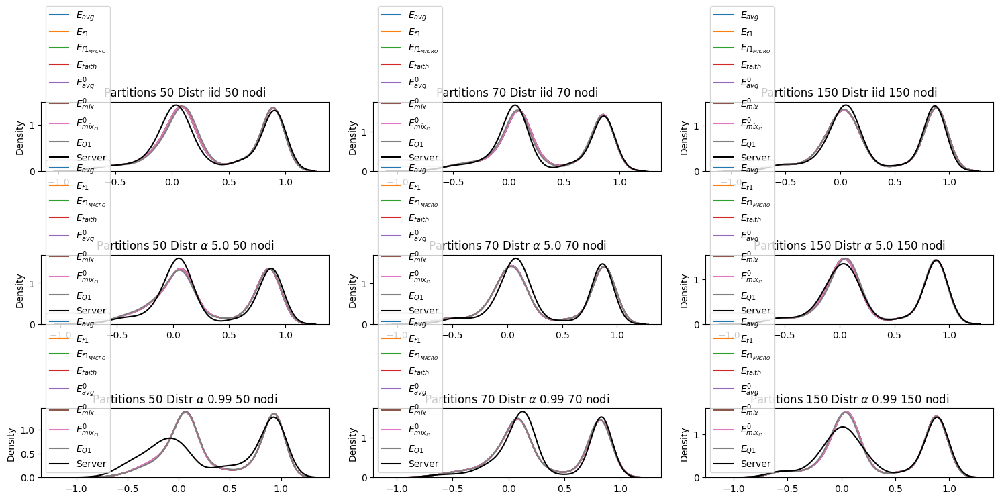

In [181]:
fig,ax = plt.subplots(3,3,figsize=(15,7))
axes = ax.flatten()
i = 0
for dist in distribs:
    for p in partitions:
        exp = (dist,p)
        print(all_faith_dict_recomputed[exp][b_v]["Server"].shape)
        # plot the distribution of the faithfulness values of the samples of the clients using sns.kdeplot
        #sns.kdeplot(all_faith_dict[exp][b_v]["Server"][0],ax=axes[i],label="Server",cumulative=False)
        #for c in range(len(all_faith_dict[exp][b_v]["Clients"])):
        #    sns.kdeplot(all_faith_dict[exp][b_v]["Clients"][c],ax=axes[i],alpha=0.1,cumulative=True)#,label="Client "+str(c))
        for prop in props:
            sns.kdeplot(np.array(all_faith_dict_recomputed[exp][b_v][prop]).flatten(),ax=axes[i],label=res_d[prop],cumulative=    False)
        sns.kdeplot(all_faith_dict_recomputed[exp][b_v]["Server"][0],ax=axes[i],label="Server",cumulative= False,c="black")
        axes[i].set_title("Partitions "+str(p.split("_")[0])+" Distr "+fancytitle((dist,p)))
        axes[i].legend()
        i+=1
plt.tight_layout()
plt.show()
        
        


9 recalculated faiths (2 are for the Server, and the Clients)
(2000, 9)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566


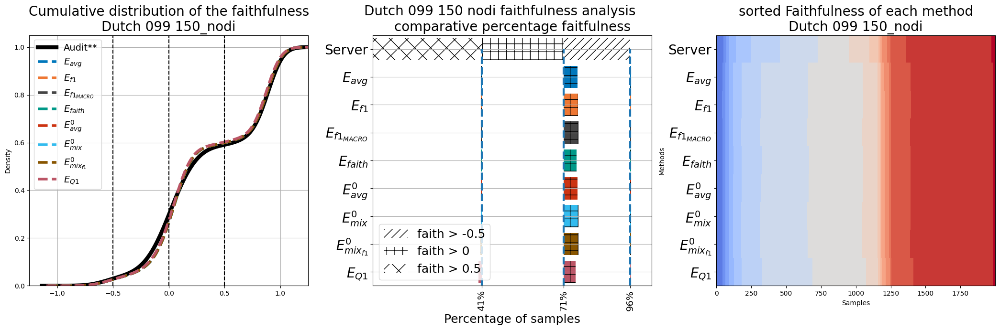

In [167]:
for exp in focus[::-1]:
    plot_recalulated_faiths(exp =exp,
                        faiths = all_faith_dict_recomputed,
                        base_value = b_v,
                        proposals = props,
                        dt_name=dt_name,
                        show=True)

    break#plt.show()

In [182]:
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1']

In [183]:
all_faith_dict_recomputed[exp][b_v].keys()

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])

In [184]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

Dataset & Clients & Distribution & $E_{avg}$ & $E_{f1}$ & $E_{f1_{MACRO}}$ & $E_{faith}$ & $E_{avg}^{0}$ & $E_{mix}^{0}$ & $E_{mix_{f1}}^0$ & $E_{Q1}$ & Server
('iid', '50_nodi')


AttributeError: 'tuple' object has no attribute 'split'

In [187]:
props_old = props
smaller_props = props
#["E_hat","E_weighted","E_f1_macro","E_fait_weighted"]#,"E_avg_t_06","E_avg_t_0"]

In [188]:
smaller_props = props

In [189]:
all_faith_dict.keys()

dict_keys([('iid', '50_nodi'), ('iid', '70_nodi'), ('iid', '150_nodi'), ('5', '50_nodi'), ('5', '70_nodi'), ('5', '150_nodi'), ('099', '50_nodi'), ('099', '70_nodi'), ('099', '150_nodi')])

In [192]:
# plot the recalculated faithfulness values as a latex table 1 colum for each aggregation method
# one raw for each experiment
# the first column is the name of the dataset, the second is the # of clients the third is the distribution
# from the fourth on, we have the faithfulness values mean and std of the faithfulness values of the aggregations
# and the server
print(" & ".join(["Dataset","Clients","Distribution"]+[res_d[p] for p in props]+["Server"]))
for exp in focus:    
    d = exp[0].replace("imb","$\\alpha$")
    nc = int(exp[1].split("_")[0])
    vals = [all_faith_dict_recomputed[exp][b_v][p] for p in props+["Server"]]
    row = " & ".join([dt_name,str(nc)+", "+d]+[f"{v.mean():.2f}±{v.std():.2f}" for v in vals])
    print(row)
    

Dataset & Clients & Distribution & $E_{avg}$ & $E_{f1}$ & $E_{f1_{MACRO}}$ & $E_{faith}$ & $E_{avg}^{0}$ & $E_{mix}^{0}$ & $E_{mix_{f1}}^0$ & $E_{Q1}$ & Server
Dutch & 50, iid & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.36±0.44 & 0.34±0.46
Dutch & 70, iid & 0.35±0.43 & 0.35±0.43 & 0.35±0.43 & 0.35±0.43 & 0.35±0.43 & 0.35±0.43 & 0.35±0.43 & 0.34±0.43 & 0.33±0.43
Dutch & 150, iid & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.45
Dutch & 50, 5 & 0.33±0.44 & 0.33±0.44 & 0.33±0.44 & 0.33±0.44 & 0.33±0.44 & 0.33±0.44 & 0.33±0.44 & 0.32±0.45 & 0.34±0.44
Dutch & 70, 5 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.35±0.43
Dutch & 150, 5 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.46 & 0.34±0.45 & 0.34±0.46
Dutch & 50, 099 & 0.38±0.46 & 0.38±0.46 & 0.37±0.46 & 0.38±0.46 & 0.38±0.46 & 0.37±0.46 & 0.37±0.46 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '50_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


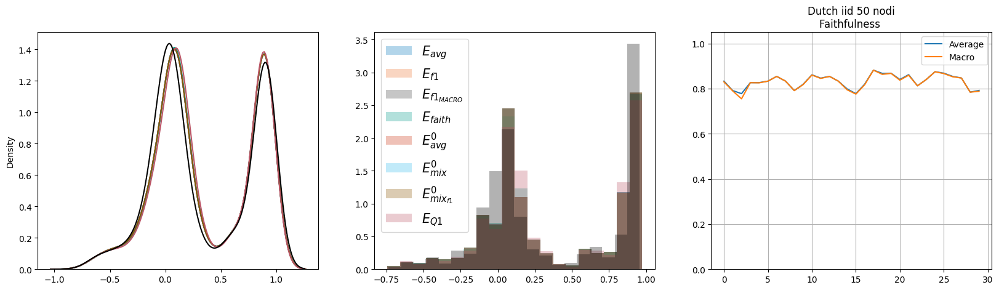

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '50_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


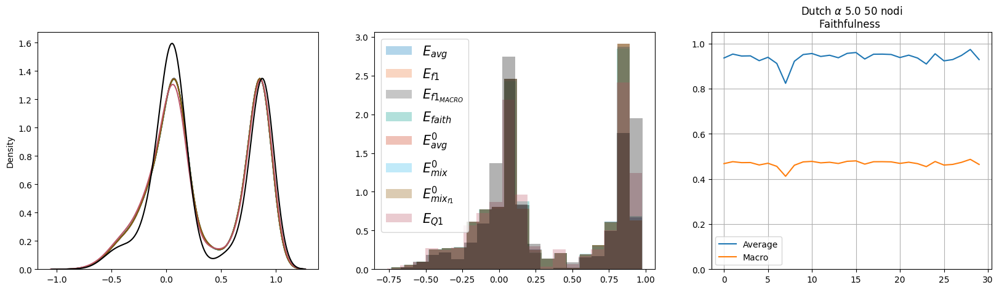

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '50_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


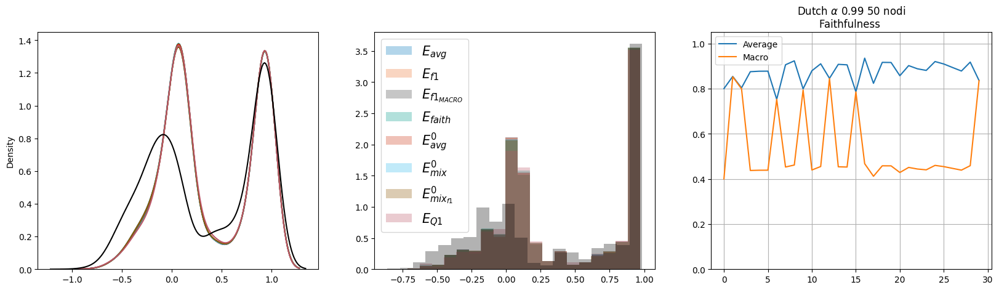

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '70_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


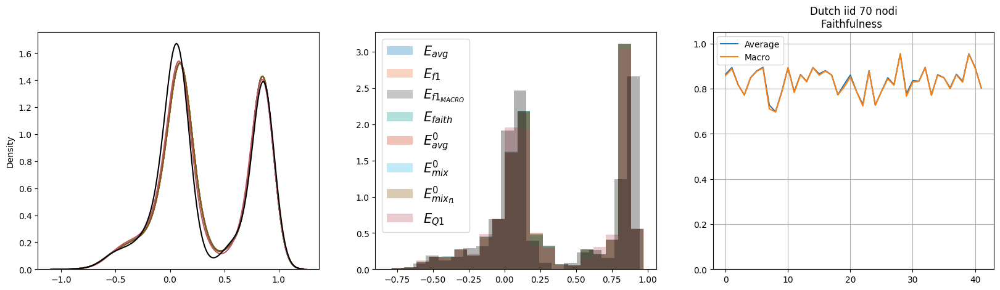

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '70_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


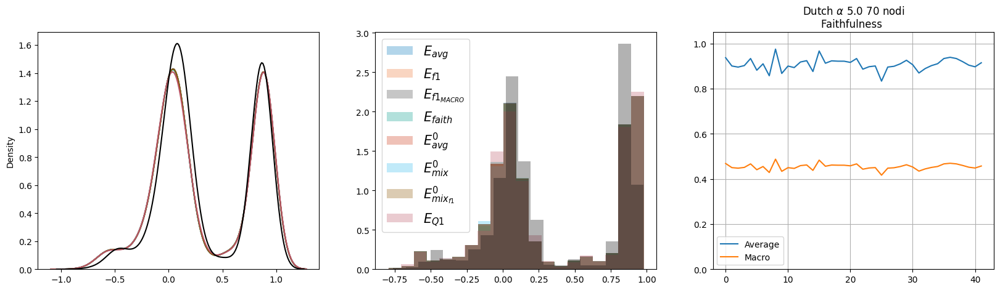

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '70_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


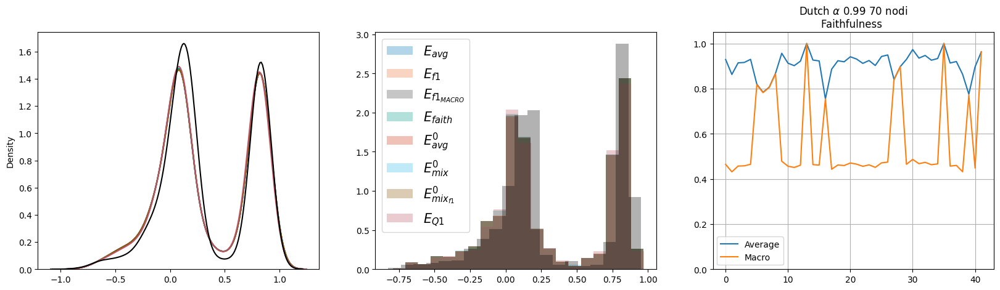

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('iid', '150_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


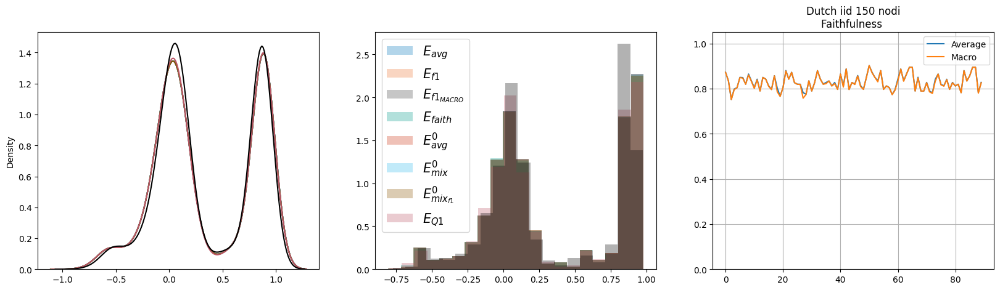

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('5', '150_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


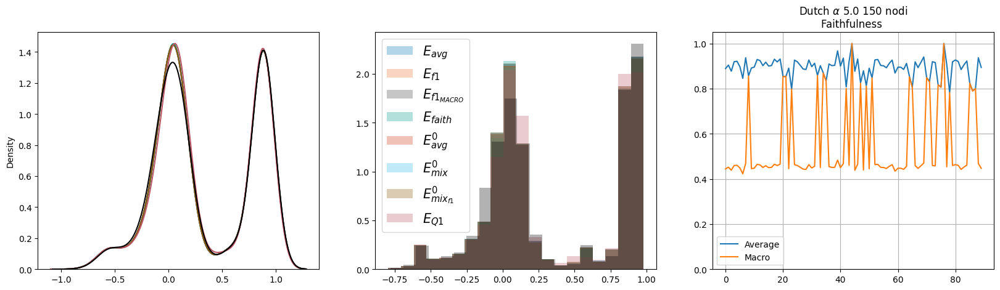

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


('099', '150_nodi')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


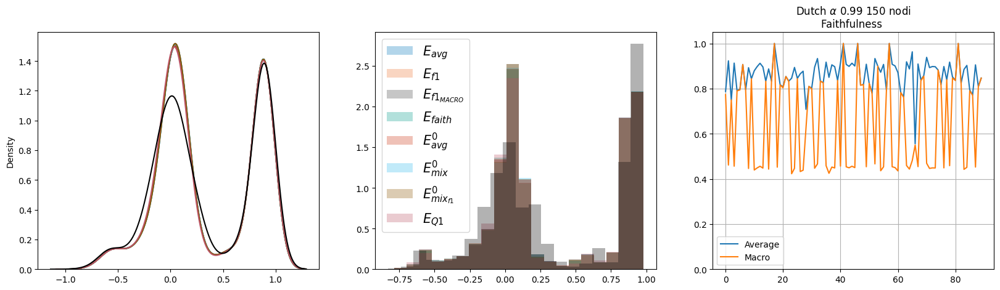

In [193]:
for p in partitions:
    for dist in distribs:
        exp = (dist,p)
        # now we want to produce the cd diagrams for the faithfulness values as well, for the same aggregations and the server
        # as "metric" we use the faithfulness values
        # as for the metric functions, the higher the value the better
        # so we do not need to flip the values
        all_faith_dict_list = all_faith_dict_recomputed[exp][b_v]
        values = np.array([np.array(all_faith_dict_list[p]).reshape(-1) for p in smaller_props+["Server"]])
        values = values.T
        metr = "Faithfulness"
        print(exp)
        current_title = dt_name+" "

        current_title+=fancytitle(exp)
        current_title+="\n"+metr+" "
        # plot the distribution of the faithfulness values of the samples of the clients using sns.kdeplot
        fig, ax = plt.subplots(1,3,figsize=(20,5))
        for pr in smaller_props+["Server"]:
            sns.kdeplot(values[:,(smaller_props+["Server"]).index(pr)],label=res_d[pr],cumulative=False,color=colors[pr],ax=ax[0])
            ax[1].legend(fontsize=15)
            ax[1].hist(values[:,(smaller_props+["Server"]).index(pr)],label=res_d[pr],color=colors[pr],alpha=0.3,density=True,bins=20)
            plt.legend(fontsize=15)
        plt.plot(all_weights_dict[exp],label="Average")
        plt.plot(all_weights_dict_MACRO[exp],label="Macro")
        # set y lims for the kde plot
        ax[2].set_ylim(0,1.05)

        plt.legend()
        plt.grid(True)
        plt.title(current_title)
        plt.show()

1000
10 recalculated faiths (2 are for the Server, and the Clients)
(2000, 9)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566


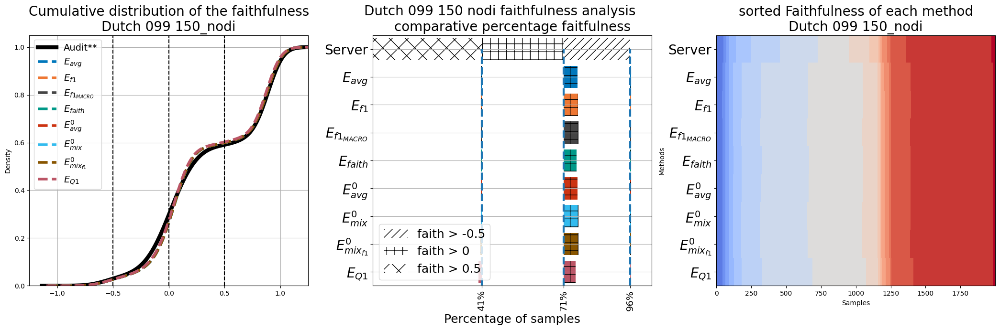

In [175]:

for exp in focus[::-1]:
    print(b_v)
    all_faith_dict_recomputed[exp][b_v]["Clients"] = all_faith_dict[exp][b_v]["Clients"]
    plot_recalulated_faiths(exp =exp,
                        faiths = all_faith_dict_recomputed,
                        base_value = b_v,
                        proposals = props,
                        dt_name=dt_name,
                        show=True)

    plt.show()
    break


<BarContainer object of 90 artists>

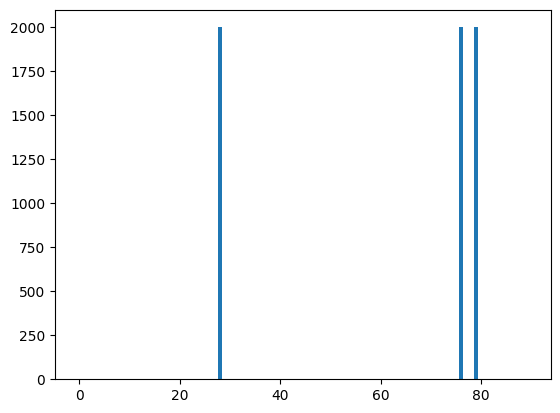

In [194]:
# check if the sum of the FI values of the server is equal to the sum of the FI values of one of the clients
exp  = focus[2]
closer = np.zeros(len(all_shap_dict[exp]["Clients"]))
for j,el in enumerate(all_shap_dict[exp]["Server"]):
    s = el.sum()

    for jj,el2 in enumerate(all_shap_dict[exp]["Clients"]):
        el2 = el2[j]
        if np.abs(el2.sum()-s)<0.01:
            closer[jj] += 1
plt.bar(np.arange(len(closer)),closer)
            


In [201]:
for exp in focus:
    # now we want to produce the cd diagrams for the faithfulness values as well, for the same aggregations and the server
    # as "metric" we use the faithfulness values
    # as for the metric functions, the higher the value the better
    # so we do not need to flip the values
    all_faith_dict_list = all_faith_dict_recomputed[exp][b_v]
    print(all_faith_dict_recomputed[exp][b_v].keys())
    values = np.array([np.array(all_faith_dict_list[p]).reshape(-1) for p in props+["Server"]])
    print(values.shape)    
    
    values = values.T
    metr = "Faithfulness"
    #current_title = dt_name+" "+(" ".join([str(elemento) for elemento in exp])if not isinstance(exp,str) else " ".join((exp.replace("imb","$\\alpha$")).split("_")))+"\n"+metr+" "
    current_title = dt_name+" "+fancytitle(exp)+"\n"+metr+" "
    create_df_and_check(methods_names=props+["Server"],
                        values=-values,
                        title=current_title,
                        show = False,
                        exp = exp,
                        metrica=metr,
                        dt_name=dt_name,
                        vmin=-1.025,vmax=1.025,
                        vertica_image_size=6)
    '''plt.clf()
    fig, ax = plt.subplots(1,2,figsize=(10,5))
    
    # select the samples with std of the faithfulness values higher than 0.2
    # and plot the faithfulness values of the samples
    stds = np.std(values,axis=1)
    print(stds.shape)
    # find the knee of the stds
    std_sorted = np.sort(stds)
    tresh = std_sorted[-150]
    #tresh = 0.05
    idx_stds = stds>tresh
    print(idx_stds.shape,values[idx_stds,:].shape)
    print(idx_stds.sum()/len(idx_stds),values.shape)

    ax[0].plot(values[idx_stds,:].T,alpha=0.3,c='black')
    #set the xticks
    ax[0].set_xticks(np.arange(len(props)+1),
            [res_d[pn] for pn in props+["Server"]]
            ,rotation=30,fontsize=15)
    ax[0].set_ylabel("Faithfulness")
    ax[0].set_title(dt_name+"\n"+"Faithfulness of the explanations of the samples"+"\n"+fancytitle(exp))
    ax[0].grid(True)
    ax[0].set_ylim(-1.025,1.025)
    ax[0].set_xlabel("Aggregations")
    # in the other ax plot the other with std < 0.2
    ax[1].plot(sorted(stds),alpha=0.3,c='black')
    ax[1].set_title("std of the faithfulness values")
    ax[1].set_ylabel("std")
    ax[1].set_xlabel("Samples")
    # add a horizontal line to separate the samples with std > 0.2
    ax[1].axhline(tresh,ls='--',c='red')
    # use sns to plot the kde of the faithfulness values
    plt.tight_layout()
    #plt.savefig("cddiagrams/"+dt_name+"_"+exp+"_faithfulness.pdf")
    plt.show()'''

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])
(9, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{MACRO}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000'} res_colors
Index(['$E_{avg}$', '$E_{f1}$', '$E_{f1_{MACRO}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1}$  $E_{f1_{MACRO}}$  $E_{faith}$  \
$E_{avg}$               1.0      0.00              0.00          0.0   
$E_{f1}$                0.0      1.00              0.01          0.0   
$E_{f1_{MACRO}}$        0.0      0.01              1.00          0.0   
$E_{faith}$             0.0      0.00    

In [202]:
for f in focus:
    print("_".join(f[::-1]))

50_nodi_iid
70_nodi_iid
150_nodi_iid
50_nodi_5
70_nodi_5
150_nodi_5
50_nodi_099
70_nodi_099
150_nodi_099


In [139]:
dt_name

'Dutch'

In [143]:
# now save all the all_shap_values_dict converting the numpy arrays to lists
json.dump({"%".join(k): {k2: np.array(v2).tolist() for k2, v2 in vv.items()} for k, vv in all_shap_dict.items()}
    ,open(dt_name+"_all_shap_values_dict_new.json","w+"))

unclosed file <_io.TextIOWrapper name='Dutch_all_shap_values_dict_new.json' mode='w+' encoding='UTF-8'>


In [144]:

with open(dt_name+"_all_shap_values_dict_new.json", "r") as f:
    loaded_dict = json.load(f)

all_shap_values_dict_loaded = {tuple(k.split("%")): {k2: np.array(v2) for k2, v2 in v.items()} for k, v in loaded_dict.items()}

In [203]:
all_shap_values_dict_loaded = all_shap_dict
# i want to plot now a thing. let's start by producing a scattering plot of the faithfulness values of the samples and the L2 norm of the explanations
for exp in focus:
    fix,ax = plt.subplots(2,4,figsize=(15,7))
    ax=ax.flatten()
    # add all the faithfulness values of the samples and the L2 norms of the explanations per aggregation
    data_d = {}
    for j,p in enumerate(props):
        data_d[p] = {"faithfulness":np.array(all_faith_dict_recomputed[exp][b_v][p]).flatten(),
                     "L2":compare_heatmaps_Frobenius(all_shap_values_dict_loaded[exp]["Server"],all_shap_values_dict_loaded[exp][p])}

    for j,p in enumerate(props):        
        data = pd.DataFrame(data_d[p])    
        for jj,axe in enumerate(ax):
            sns.kdeplot(data=data,x="faithfulness",y="L2",ax=axe,fill=False,color="grey",label='',alpha=0.2)

        ax[j].set_title(res_d[p],fontsize=15)
        ax[j].set_xlabel("faithfulness")
        ax[j].set_ylabel("$ShapGap_{L2}$")
        #ax[j].set_xlim(-1.15,1.35)
        #ax[j].set_ylim(0.01,0.9)
    for j,p in enumerate(props):
        data = pd.DataFrame(data_d[p])
        sns.kdeplot(data=data,x="faithfulness",y="L2",label=p,ax=ax[j],fill=True,color=colors[p])
        # scatter plot the faithfulness values of the samples and the L2 norm of the explanations
        ax[j].scatter(data["faithfulness"],data["L2"],label=p,c=colors[p],alpha=0.5,s=5,marker=".")
    # in the last plot we plot the faithfulness values of the samples and the L2 norm of the explanations of the server
    # the L2 is trivially 0, so we plot only the faithfulness kde values, without a 1d kde plot
    #sns.kdeplot(all_faith_dict_recomputed[exp][b_v]["Server"][0],fill=True,label="",ax=ax[-1],color=colors["Server"])
    #ax[-1].set_title("Server")
    # remove the y ticks from the last plot
    plt.suptitle(dt_name+" "+fancytitle(exp)+"\nfaithfulness vs $ShapGap_{L2}$",fontsize=15)
    plt.tight_layout()
    plt.savefig(dt_name+"_"+"_".join(exp[::-1])+"_faithfulness_vs_L2.pdf")
    plt.clf()
    # create the dataframe
    # create the scatter plot

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

In [ ]:
'''
os.chdir("Multi_Comparison_Matrix")
from multi_comp_matrix import MCM
os.chdir("..")

df_results = pd.read_csv('results_df.csv')

output_dir = '.'

MCM.compare(
        output_dir=output_dir,
        df_results=df_results,
        used_statistic='F1 score',
        # try excluding columns
        #excluded_col_comparates = ["SVM","KNeighbors","RandomForest","DecisionTree","XGBoost"],
        order_WinTieLoss='higher',
        pdf_savename="heatmap",
        png_savename="heatmap",

        #colorbar_orientation='horizontal',
    )
'''

In [204]:
metriche = ["$ShapGap_{Kendall}$","$ShapGap_{L2}$","$ShapGap_{CosSim}$","$ShapGap_{Spearman}$"]
metric_functions = [compare_heatmaps_kendalltau,
                    compare_heatmaps_Frobenius,
                    compare_heatmaps_cosinesim,
                    compare_heatmaps_spearmanr]

In [205]:
SHOWW = False
valueminmax = [(0.1,1.025)]# kendall
valueminmax+= [(-0.025,.8)]# frobenius
valueminmax+= [(0.70,1.025)]# cosine sim
valueminmax+= [(0.3,1.025)]# spearman
date = time.strftime("%Y-%m-%d")
for metr,metr_f,(vm,vM) in zip(metriche,metric_functions,valueminmax):
    for exp in focus:
            values = []
            print(metr)
            
            for p in props:
                print(p)
                vals = metr_f(all_shap_dict[exp]["Server"],all_shap_dict[exp][p])
                if metr != "$ShapGap_{L2}$":
                    # we multiply the values for -1 because the Frobenius distance is a distance, so the higher the value the worse
                    print("flipped",metr)
                    vals *=-1
                values.append(vals)

            '''
            sns.kdeplot(vals,label=res_d[p],cumulative=False,color=colors[p])
            plt.legend()
            plt.show()
            '''
            #QUIQUOQUA

            values = np.array(values)
            current_title = dt_name+" "
            current_title+=fancytitle(exp)
            current_title+="\n"+metr+" "
            print(values.shape)
                
            # open the file "table_results_"+dt_name+".csv" and append the date with the results (the mean of the values for every aggregation and its std)
            with open("table_results_"+dt_name+".csv","a+") as f:

                f.write("\n"+date)
                f.write(current_title)
                f.write("\n")
                f.write("Aggregation,mean,std\n")
                for p,v in zip(props,values):
                    f.write(p+","+str(v.mean())+","+str(v.std())+"\n")
            print("updated results on ","table_results_"+dt_name+".csv")
            create_df_and_check(methods_names=props,
                                values=values.T,
                                title=current_title,
                                show=SHOWW,
                                exp=exp,
                                metrica=metr,
                                dt_name = dt_name,
                                vmin=vm,vmax=vM,
                                vertica_image_size=6)
            #input("continue")

$ShapGap_{Kendall}$
E_hat
flipped $ShapGap_{Kendall}$
E_weighted
flipped $ShapGap_{Kendall}$
E_f1_macro
flipped $ShapGap_{Kendall}$
E_fait_weighted
flipped $ShapGap_{Kendall}$
E_avg_t_0
flipped $ShapGap_{Kendall}$
E_mixed
flipped $ShapGap_{Kendall}$
E_mix_f1
flipped $ShapGap_{Kendall}$
E_Q1
flipped $ShapGap_{Kendall}$
(8, 2000)
updated results on  table_results_Dutch.csv
{'$E_{avg}$': '#0077BB', '$E_{f1}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{MACRO}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000'} res_colors
Index(['$E_{avg}$', '$E_{f1}$', '$E_{f1_{MACRO}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$'],
      dtype='object') columns of the ranking_df
                 E_hat  E_weighted  E_f1_macro  E_fait_weighted  E_avg_t_0  \
E_hat              1.0        0.90        0.90 

In [206]:
focus

[('iid', '50_nodi'),
 ('iid', '70_nodi'),
 ('iid', '150_nodi'),
 ('5', '50_nodi'),
 ('5', '70_nodi'),
 ('5', '150_nodi'),
 ('099', '50_nodi'),
 ('099', '70_nodi'),
 ('099', '150_nodi')]

In [159]:
# import the compoents to create the pdfs
from PyPDF2 import PdfMerger

# now merge all the pdf created by experiment first, then by metric
for m in metriche+["Faithfulness"]:
    if "004" in exp:
        continue
    merger = PdfMerger()
    
    pdfs = ["cddiagrams/"+dt_name+"_"+"_".join(exp)+"_CD_"+m+".pdf" for exp in focus]
    for pdf in pdfs:
        # append the pdfs
        merger.append(pdf)
    if m=="Faithfulness":
        merged_name = "ALL_"+m+"_"+dt_name+".pdf"
        print("merged",merged_name)
        print(pdfs)
    merged_name = "ALL_"+m+" "+dt_name+".pdf"
    merger.write("cddiagrams/"+merged_name)
    merger.close()
    print("merged",merged_name)
    #for pdd in pdfs:
    #    print(pdd)


merged ALL_$ShapGap_{Kendall}$ Dutch.pdf
merged ALL_$ShapGap_{L2}$ Dutch.pdf
merged ALL_$ShapGap_{CosSim}$ Dutch.pdf
merged ALL_Faithfulness_Dutch.pdf
['cddiagrams/Dutch_iid_50_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_iid_70_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_iid_150_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_5_50_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_5_70_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_5_150_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_099_50_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_099_70_nodi_CD_Faithfulness.pdf', 'cddiagrams/Dutch_099_150_nodi_CD_Faithfulness.pdf']
merged ALL_Faithfulness Dutch.pdf


In [ ]:
for exp in focus:
    fig,ax = plt.subplots(1,1,figsize=(10,10))
    plot_differences(dictionary = all_shap_dict[exp],
                    proposals=props,
                    axes=ax,
                    colorbar = True)
    plt.suptitle(dt_name+"\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    ax = plt.gca()
    ax.set_title("Difference matrix between the server, the clients and all the aggregations",fontsize=18)
    plt.savefig(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_difference_matrix.pdf")
    plt.show()
    plt.close()
    plt.clf()

In [158]:
# use the PDF merger to merge the CD plots
import PyPDF2
import os
merger = PyPDF2.PdfMerger()
pdfs = [el for el in os.listdir() if "CD_$" in el and "pdf" in el and dt_name in el]
pdfs_found = sorted([p[::-1] for p in pdfs])
assert len(pdfs_found) == 3*len(focus),"not all the plots have been found"+str(pdfs_found)
# sort them so that the order is L2, CosSim and Kendall
pdfs = []
pdfs += [p for p in pdfs_found if "{L2}" in p[::-1]]
pdfs += [p for p in pdfs_found if "{CosSim}" in p[::-1]]
pdfs += [p for p in pdfs_found if "{Kendall}" in p[::-1]]
print(pdfs)
for e in pdfs:
    print(e)
    merger.append(e[::-1])  
    print(e[::-1])
merger.write(dt_name+"_CD_plots.pdf")
print("file saved at",dt_name+"_CD_plots.pdf")

AssertionError: not all the plots have been found['fdp.$}2L{_paGpahS$_DC_idon 051 5_dii_non_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon 051 dii_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon 07 5_dii_non_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon 07 990_dii_non_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon 07 dii_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_051 5_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_051 990_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_051 dii_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_07 5_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_07 990_hctuD', 'fdp.$}2L{_paGpahS$_DC_idon_07 dii_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon 051 5_dii_non_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon 051 dii_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon 07 5_dii_non_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon 07 990_dii_non_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon 07 dii_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_051 5_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_051 990_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_051 dii_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_07 5_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_07 990_hctuD', 'fdp.$}lladneK{_paGpahS$_DC_idon_07 dii_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon 051 5_dii_non_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon 051 dii_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon 07 5_dii_non_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon 07 990_dii_non_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon 07 dii_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_051 5_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_051 990_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_051 dii_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_07 5_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_07 990_hctuD', 'fdp.$}miSsoC{_paGpahS$_DC_idon_07 dii_hctuD']

In [ ]:
dt_name+"_CD_plots.pdf"

In [109]:
indexes_per_calss_list.keys()#len(indexes_per_calss_list[exp])
indexes_per_calss_list2 = {exp:indexes_per_calss_list["%".join(exp)] for exp in focus}

In [ ]:
pdfs = []
for p in partitions:
    for dist in distribs:
        exp = (dist,p)
        pdfs.append(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
print(pdfs)
# use the pdf merger to merge the faithfulness distributions
import PyPDF2
import os
merger = PyPDF2.PdfMerger()
for e in pdfs:
    print(e)
    if os.path.exists(e):
        merger.append(e)  
        print(e)
    else:
        print(e,"not found")
merger.write(dt_name+"_faithfulness_distributions.pdf")
print("file saved at",dt_name+"_faithfulness_distributions.pdf")




In [ ]:
1

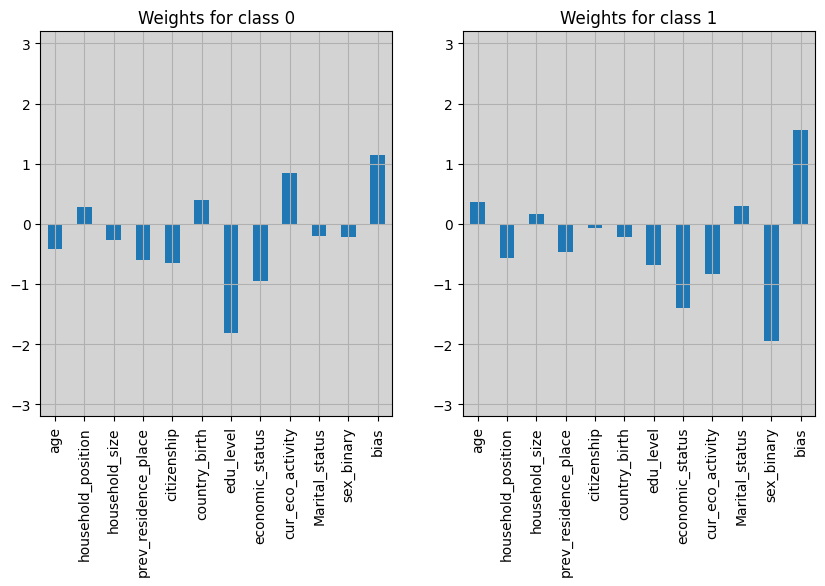

In [197]:
# now plot the model.layer1.weights as histograms
# the bars should be placed on 2 subplots with the same y axis
df = pd.DataFrame(model.layer1.weight.detach().numpy(),columns=feat_names)
fig,ax = plt.subplots(1,2,figsize=(10,5))
df.loc[0].plot(kind='bar',ax=ax[0],alpha=1,stacked=False)
ax[0].set_title("Weights for class 0")
df.loc[1].plot(kind='bar',ax=ax[1],alpha=1,stacked=False)
ax[1].set_title("Weights for class 1")
for a in ax:
    a.set_facecolor('lightgray')
    a.grid(True)
    # set y lim
    a.set_ylim(-3.2,3.2)
    
plt.show()

In [198]:
for p in props:
    plt.bar(np.arange(54),np.abs(all_shap_dict[folder]["Server"]).mean(0),label="Server",alpha=0.5,edgecolor='black',
                color="grey")
    plt.bar(np.arange(54),np.abs(all_shap_dict[folder][p]).mean(0),label=p,alpha=0.9,edgecolor='black',
            color=colors[p] if p!="Server" else "black")
    plt.grid(True)
    plt.legend()
    plt.show()

KeyError: 'dutch/150_nodi/099'

In [199]:
for exp in focus:
    test_s = load_npz(os.path.sep.join([all_shap_folders[exp].replace("shap","samples"),
                                        "explain_samples_income_"+exp[1]+"_"+exp[0]+".npz"]))
    exp_dt = TensorDataset(torch.Tensor(test_s["X"]),
                        torch.Tensor(np.eye(2)[test_s["y"]]))
    
    # find the best one relatively to the metric ShapGap_{L2}

    top_k = sort_aggrg(exp)
    top_k = [el[0] for el in top_k][:2]
    print(top_k,"TOOOOOP")
    plot_faith_dry(exp=exp,
                faits = all_faith_dict[exp][b_v],
                all_shap_values_dict=all_shap_dict,
                te_set=exp_dt,
                activations=activations_of_models[exp][b_v],
                show_samples=1500,
                chosen_idxs=indexes_per_calss[exp],
                dt_name=dt_name,
                feat_names=feat_names,
                top_k=top_k,
                show=False,
                vmax=0.45,
                vmax_diff = 0.1
    )

    

FileNotFoundError: [Errno 2] No such file or directory: 'dutch_50_nodi_iid_samples/explain_samples_income_50_nodi_iid.npz'

In [200]:
pdfs = []
for exp in focus:
    pdfs.append(dt_name+"_"+" ".join([str(e4) for e4 in exp])+"_faithfulness_analysis_post.pdf")
print(pdfs)
# use the pdf merger to merge the faithfulness strides
import PyPDF2
import os
merger = PyPDF2.PdfMerger()
for e in pdfs:
    print(e)
    if os.path.exists(e):
        merger.append(e)
        print(e)
    else:
        print(e,"not found")
merger.write(dt_name+"_faithfulness_analysis_post.pdf")
print("file saved at",dt_name+"_faithfulness_analysis_post.pdf")

['Dutch_iid 50_nodi_faithfulness_analysis_post.pdf', 'Dutch_iid 70_nodi_faithfulness_analysis_post.pdf', 'Dutch_iid 150_nodi_faithfulness_analysis_post.pdf', 'Dutch_5 50_nodi_faithfulness_analysis_post.pdf', 'Dutch_5 70_nodi_faithfulness_analysis_post.pdf', 'Dutch_5 150_nodi_faithfulness_analysis_post.pdf', 'Dutch_099 50_nodi_faithfulness_analysis_post.pdf', 'Dutch_099 70_nodi_faithfulness_analysis_post.pdf', 'Dutch_099 150_nodi_faithfulness_analysis_post.pdf']
Dutch_iid 50_nodi_faithfulness_analysis_post.pdf
Dutch_iid 50_nodi_faithfulness_analysis_post.pdf not found
Dutch_iid 70_nodi_faithfulness_analysis_post.pdf
Dutch_iid 70_nodi_faithfulness_analysis_post.pdf
Dutch_iid 150_nodi_faithfulness_analysis_post.pdf
Dutch_iid 150_nodi_faithfulness_analysis_post.pdf
Dutch_5 50_nodi_faithfulness_analysis_post.pdf
Dutch_5 50_nodi_faithfulness_analysis_post.pdf not found
Dutch_5 70_nodi_faithfulness_analysis_post.pdf
Dutch_5 70_nodi_faithfulness_analysis_post.pdf
Dutch_5 150_nodi_faithfulness_

PyPDF2 is deprecated. Please move to the pypdf library instead.


file saved at Dutch_faithfulness_analysis_post.pdf


In [32]:
# in this notebook we created the following plots:
# 1) the faithfulness of the samples of the clients and the server (faithfulness_strides.pdf)
